# **Цифровая обработка спутниковых снимков и гравитационного поля: уточнение цифровой модели рельефа методами машинного обучения и уточнение аномалий Буге**

## **Введение**

В предыдущих блокнотах мы работали со спутниковым снимком как с многоканальным изображением: строили безоблачный композит, классифицировали пиксели ([лекция по GEE и машинному обучению](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2)) и искали в них группы без учителя ([лекция по кластеризации](https://colab.research.google.com/drive/1rWGeyE30g6rAk6eYgdLkFdEFaiVZ3cey)). В этом блокноте те же приёмы применяются к изображениям другой природы — к цифровой модели рельефа, где значение пикселя равно высоте, и к карте гравитационного поля, где значение пикселя равно силе тяжести.

Цифровая модель рельефа (ЦМР) нужна при проектировании дорог и трубопроводов, расчёте объёмов земляных работ, моделировании затопления и обработке гравиметрических измерений. Для большей части России подробных съёмок нет, поэтому используют открытые глобальные модели, построенные по радарной или оптической космической съёмке. У них есть систематическая ошибка: радар и стереосъёмка «видят» верхнюю границу объектов, поэтому в лесу модель передаёт высоту крон, а не земли, и завышает рельеф на метры и десятки метров.

Исправить эту ошибку помогает спутниковый лазерный высотомер ICESat-2. Часть его импульсов проходит сквозь просветы в кронах и отражается от земли, поэтому он измеряет высоту земли и под лесом — но только вдоль узких треков, разнесённых на километры. Между треками высота земли неизвестна. Задача обработки изображений здесь такая: по снимку и самой модели рельефа понять, где лес и насколько он высок, обучить модель машинного обучения предсказывать ошибку высот в точках лазерных измерений и применить её ко всем пикселям изображения рельефа.

Уточнённый рельеф затем используется для расчёта **аномалий Буге** — карты, на которой из измеренного гравитационного поля вычтено притяжение видимого рельефа. По этой карте ищут то, что скрыто под землёй: плотные рудные тела, разломы, впадины с рыхлыми отложениями. Что это такое и почему здесь важна точность высот, подробно разобрано в разделе 8.

**Основные задачи:**
- Собрать изображения разных источников (снимок, четыре модели рельефа, карты покрова, гравитационное поле) и точечные лазерные измерения на одной сетке
- Построить безоблачный медианный композит и спектральные индексы как попиксельные операции над каналами
- Рассчитать производные рельефа фильтрами в окне: уклон, индекс топографического положения, шероховатость
- Отфильтровать и очистить точечные измерения, привязать их к растру билинейной интерполяцией
- Классифицировать пиксели и честно оценить точность по пространственным блокам
- Уточнить модель рельефа регрессией и показать результат трёхмерными поверхностями
- Выделить аномалии Буге: вычитание притяжения рельефа, сглаживание фона фильтром низких частот, пороговая сегментация остатка
- Решить прикладные задачи: затопление (связные области), профиль, объёмы, высота растительности

Все этапы разобраны на примере окрестностей Красноярска — лесистой территории с городом, Енисеем и заповедником «Столбы», где ошибка глобальной модели в лесу проявляется наглядно. На схеме показана вся цепочка обработки.

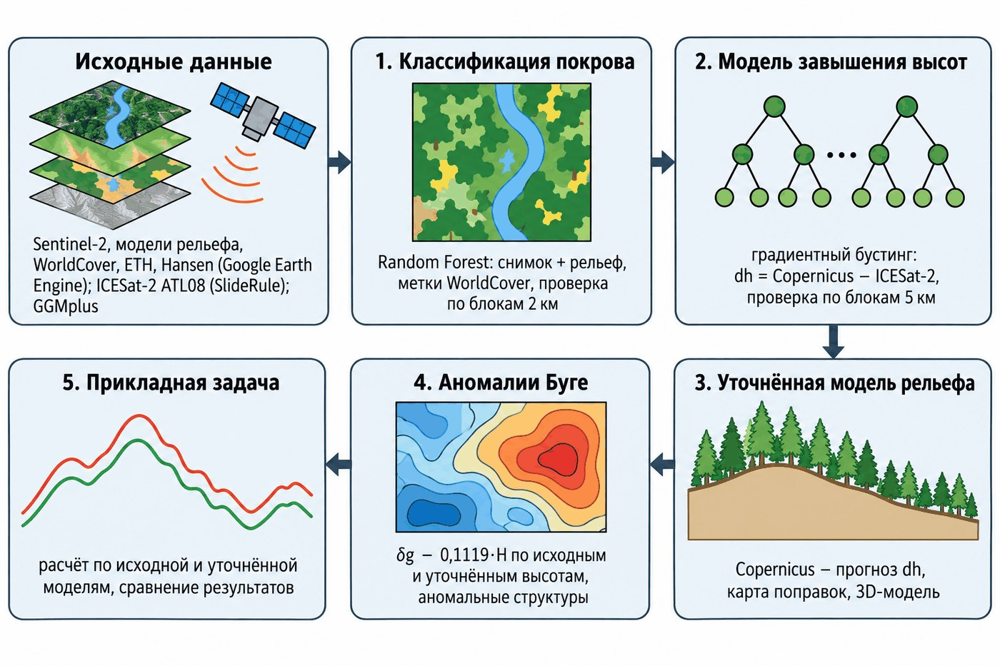

*Цепочка обработки: от исходных изображений к уточнённому рельефу, аномалиям Буге и прикладным задачам.*

### **Основные определения**

**Растр (изображение)** — прямоугольная сетка ячеек (пикселей), в каждой из которых записано число. Для снимка это коэффициент отражения в спектральном канале, для модели рельефа — высота, для карты поля — сила тяжести. Методы обработки изображений применимы к любому из них.

**Цифровая модель рельефа (ЦМР)** — растр высот земной поверхности. **Цифровая модель поверхности (ЦМП, DSM)** — растр высот верхней границы всего, что на ней находится: крон, крыш, сооружений. Глобальные «модели рельефа» в лесу на деле ближе к ЦМП.

**Безоблачный композит** — изображение, в котором значение каждого пикселя вычислено по многим снимкам разных дат (здесь — медиана по безоблачным наблюдениям).

**Фильтр в окне (свёртка)** — операция, заменяющая значение пикселя функцией значений его соседей в окне: среднее (сглаживание), разность соседей (производная), стандартное отклонение (шероховатость). Сглаживание — **фильтр низких частот**: оставляет плавные изменения. Разность исходного и сглаженного изображения — **фильтр высоких частот**: оставляет мелкие детали.

**Билинейная интерполяция** — оценка значения растра в произвольной точке по четырём ближайшим пикселям с весами, зависящими от расстояния. Так значения изображения «снимаются» в точках лазерных измерений.

**Эталон** — независимые измерения, по которым проверяется точность. Здесь эталоном высоты земли служат лазерные измерения ICESat-2.

**Аномалия Буге** — гравитационное поле, из которого вычтено притяжение масс рельефа над уровнем моря. Показывает, где под поверхностью породы плотнее или легче среднего.

**Пороговая сегментация** — разделение изображения на объекты и фон по условию на значение пикселя (например, $|x| > 1{,}5\sigma$). **Связная область** — группа соседних пикселей, удовлетворяющих одному условию.

---

## **Раздел 1. Подготовка среды и данных**

### **1.1. Настройка рабочей среды**

Кроме знакомых библиотек понадобятся `sliderule` (клиент сервиса лазерных данных ICESat-2; версия зафиксирована, чтобы результаты не зависели от обновлений), `pyproj` (пересчёт координат и систем высот), `plotly` (интерактивные трёхмерные модели) и `folium` (интерактивные карты).

In [ ]:
%pip install -q geemap sliderule==5.6.3 pyproj rasterio folium plotly geopandas

In [ ]:
# Импорт библиотек
import os, re, math, time, warnings, urllib.request                 # Файлы, текст, время, загрузка по ссылке.
import numpy as np                                                       # Массивы и расчёты на сетке.
import pandas as pd                                                      # Таблицы.
import matplotlib.pyplot as plt                                          # Графики и карты.
from matplotlib.colors import ListedColormap, BoundaryNorm, LightSource, to_rgb   # Палитры, отмывка рельефа, цвета.
from matplotlib.patches import Patch                                     # Элементы легенд.
import ee, geemap, folium, pyproj                                        # Earth Engine, интерактивные карты, системы координат.
import plotly.graph_objects as go                                        # Трёхмерная модель.
import plotly.io as pio                                                  # Настройка вывода графиков plotly.
from pyproj import Transformer                                           # Пересчёт координат и высот.
from scipy.ndimage import uniform_filter, gaussian_filter, map_coordinates, label   # Сглаживание, интерполяция, связные области.
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier  # Случайный лес и градиентный бустинг.
from sklearn.linear_model import LogisticRegression                      # Логистическая регрессия.
from sklearn.svm import SVC                                              # Метод опорных векторов.
from sklearn.pipeline import make_pipeline                               # Цепочка «стандартизация → модель».
from sklearn.preprocessing import StandardScaler                         # Стандартизация признаков.
from sklearn.model_selection import GroupKFold, KFold                    # Перекрёстная проверка: по пространственным блокам и случайная.
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, precision_score, recall_score  # Метрики классификации.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay     # Матрица ошибок классификации.
from sklearn.cluster import KMeans                                       # Кластеризация k-средних.
from sklearn.metrics import silhouette_score                             # Коэффициент силуэта: контроль качества кластеризации.
from sklearn.inspection import permutation_importance                   # Важность признаков перестановкой.

warnings.filterwarnings("ignore")                                       # Не выводим служебные предупреждения библиотек.
pio.renderers.default = "colab+plotly_mimetype"                         # Графики plotly видны и в Colab, и в VS Code/Jupyter.
pyproj.network.set_network_enabled(True)                                 # Сетки геоида загружаются автоматически.
SEED = 42                                                                # Начальное значение генератора случайных чисел: результаты воспроизводимы.
N_JOBS = int(os.environ.get("NB_N_JOBS", "-1"))                          # Число потоков для обучения моделей (−1 – все).
OUT = "data"                                                             # Папка для загруженных данных (лазерные измерения, фотоны).
os.makedirs(OUT, exist_ok=True)                                          # Создаём папку, если её нет.
print("ee", ee.__version__, "| geemap", geemap.__version__, "| pyproj", pyproj.__version__)  # Версии ключевых библиотек.
%config InlineBackend.figure_format = "jpeg"                             # Рисунки со снимками компактнее в JPEG.

ee 1.7.47 | geemap 0.38.9 | pyproj 3.8.0


**Пояснение используемых библиотек:**
- `ee` и `geemap` — Google Earth Engine и интерактивные карты
- `scipy.ndimage` — фильтры в окне (`uniform_filter`, `gaussian_filter`), интерполяция (`map_coordinates`) и поиск связных областей (`label`)
- `scikit-learn` — классификация, регрессия, кластеризация и проверка моделей
- `pyproj` — пересчёт координат между проекциями и высот между системами
- `plotly` и `folium` — трёхмерные модели и карты на подложке Esri

### **1.2. Аутентификация и инициализация**

Перед началом работы с geemap и Google Earth Engine необходимо:

- **Зарегистрировать аккаунт Google Earth Engine**: Перейдите на [https://code.earthengine.google.com/register](https://code.earthengine.google.com/register) для создания аккаунта GEE. После регистрации нужно настроить проект Google Cloud и активировать API Earth Engine, следуя инструкциям [здесь](https://docs.google.com/document/d/1ZGSmrNm6_baqd8CHt33kIBWOlvkh-HLr46bODgJN1h0/edit?usp=sharing). GEE бесплатен для [некоммерческого и исследовательского использования](https://earthengine.google.com/noncommercial).

- **Проверить аутентификацию API**: Чтобы убедиться в правильности настройки аккаунта Earth Engine, запустите [этот тестовый блокнот](https://colab.research.google.com/github/gee-community/geemap/blob/master/docs/notebooks/geemap_colab.ipynb) в Google Colab.

In [ ]:
PROJECT_ID = "seraphic-effect-413810"   # Замените на свой проект Google Cloud.

ee.Authenticate()                                                        # При первом запуске откроется окно авторизации Google.
ee.Initialize(project=PROJECT_ID)                                        # Подключаемся к Earth Engine.
print("Earth Engine подключён:", ee.Number(1).add(1).getInfo() == 2)     # Пробный расчёт на сервере: 1 + 1 = 2.

Earth Engine подключён: True


### **1.3. Территория**

Участок задаётся прямоугольником в градусах: запад, юг, восток, север. Остальные параметры понадобятся в конце блокнота для прикладных задач; значение `None` означает автоматический выбор.

| Параметр | Что означает |
|---|---|
| `TERRITORY` | Название территории для подписей |
| `ROI_BOUNDS` | Границы участка: запад, юг, восток, север (градусы) |
| `S2_PERIOD` | Период съёмки Sentinel-2 для безоблачного композита (лето) |
| `ICESAT_PERIOD` | Период лазерных измерений ICESat-2 |
| `WATER_RISE_M`, `WATER_POINT` | Затопление: подъём уровня воды, м, и точка на водном объекте (`None` – самый крупный водный объект) |
| `PROFILE` | Профиль: начальная и конечная точки (`None` – диагональ участка) |
| `VOLUME_BOX`, `VOLUME_LEVEL` | Объёмы: участок расчёта и отметка (`None` – выбор автоматически, объём над самой низкой точкой) |

In [ ]:
TERRITORY = "Красноярск: Енисей и окрестности заповедника «Столбы»"   # Название для подписей.
ROI_BOUNDS = [92.75, 55.87, 93.07, 56.05]          # Запад, юг, восток, север, градусы.
S2_PERIOD = ("2023-06-15", "2023-08-31")           # Летний период для композита Sentinel-2.
ICESAT_PERIOD = ("2018-10-14", "2025-12-31")       # Период лазерных измерений ICESat-2.
WATER_RISE_M = 3.0                                 # Затопление: подъём уровня воды, м.
WATER_POINT = None                                 # Затопление: точка на водном объекте (долгота, широта) или None.
PROFILE = None                                     # Профиль: две точки [(долгота, широта), (долгота, широта)] или None.
VOLUME_BOX = None                                  # Объёмы: границы участка (запад, юг, восток, север) или None.
VOLUME_LEVEL = None                                # Объёмы: отметка выемки, м, или None.

In [ ]:
REGION = ee.Geometry.Rectangle(ROI_BOUNDS)                               # Территория как геометрия Earth Engine.
center = [(ROI_BOUNDS[1] + ROI_BOUNDS[3]) / 2, (ROI_BOUNDS[0] + ROI_BOUNDS[2]) / 2]   # Центр участка: широта, долгота.
m = geemap.Map(center=center, zoom=11)                                   # Интерактивная карта geemap.
m.add_basemap("Esri.WorldImagery")                                       # Подложка – космические снимки Esri.
m.add_layer(REGION, {"color": "yellow"}, "Участок")                      # Границы участка.
m                                                                        # Показываем карту.

Map(center=[55.959999999999994, 92.91], controls=(WidgetControl(options=['position', 'transparent_bg'], positi…

Жёлтый прямоугольник — участок около 20×20 км: левый берег Енисея с застройкой Красноярска на севере и сплошной тайгой заповедника «Столбы» на юге.

### **1.4. Готовые функции**

Технические функции собраны в свёрнутых ячейках. Их достаточно выполнить; каждый шаг пояснён комментарием справа от строки.

| Функция | Что делает |
|---|---|
| `make_grid` | Общая сетка участка: проекция UTM, шаг 30 м |
| `gee_to_numpy` | Получает изображение Earth Engine сразу в виде массивов NumPy на сетке участка |
| `s2_composite` | Безоблачный медианный композит Sentinel-2 и индексы NDVI, NDWI, NDBI |
| `dem_images`, `auxiliary_images` | Четыре модели рельефа; карта покрова, высота леса, год потери леса |
| `load_icesat2`, `load_photons` | Лазерные измерения ICESat-2 (подготовленные данные или сервис SlideRule) |
| `load_ggmplus` | Гравитационное поле GGMplus для участка |
| `ellipsoid_to_geoid` | Пересчёт высоты от эллипсоида к геоиду |
| `relief_features` | Уклон, индексы топографического положения, шероховатость |
| `lonlat_to_rowcol`, `grid_lonlat` | Связь географических координат и пикселей сетки |
| `block_id`, `height_metrics` | Номер пространственного блока; показатели точности высот |
| `mesh3d_pair`, `surface_3d`, `overlay_layer` | Интерактивная 3D-модель, трёхмерная поверхность растра, слой карты на подложке Esri |

Источники различаются разрешением: 10–20 м у снимков, 30 и 90 м у моделей рельефа, около 220 м у гравитационного поля, а лазерные измерения — отдельные точки. Чтобы их сравнивать, все растры приводятся к одной сетке: проекция UTM зоны участка, пиксель 30×30 м. Пиксели получаются квадратными в метрах, поэтому площади, расстояния и уклоны считаются напрямую.

В [лекции по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2) изображения экспортировались в GeoTIFF. Здесь используется более короткий путь — `ee.data.computePixels`: Earth Engine сам пересчитывает изображение на сетку участка и возвращает массив NumPy. Размер одного запроса ограничен, поэтому участок загружается фрагментами 400×400 пикселей.

In [ ]:
# Готовые функции: сетка участка и загрузка из Google Earth Engine
def utm_epsg(lon, lat):
    """Код EPSG зоны UTM для точки."""
    zone = int((lon + 180) // 6) + 1                                     # Номер шестиградусной зоны UTM.
    return f"EPSG:{(32600 if lat >= 0 else 32700) + zone}"               # 326xx – северное полушарие, 327xx – южное.

def make_grid(bounds, res=30):
    """Общая сетка участка в проекции UTM с шагом res метров."""
    lon0, lat0, lon1, lat1 = bounds                                      # Запад, юг, восток, север.
    crs = utm_epsg((lon0 + lon1) / 2, (lat0 + lat1) / 2)                 # Зона UTM по центру участка.
    to_utm = Transformer.from_crs("EPSG:4326", crs, always_xy=True)      # Пересчёт градусов в метры UTM.
    xs, ys = to_utm.transform([lon0, lon1, lon0, lon1], [lat0, lat0, lat1, lat1])   # Четыре угла участка.
    x0, x1 = math.floor(min(xs) / res) * res, math.ceil(max(xs) / res) * res        # Границы, кратные шагу сетки.
    y0, y1 = math.floor(min(ys) / res) * res, math.ceil(max(ys) / res) * res  # То же по вертикали.
    W, H = int((x1 - x0) / res), int((y1 - y0) / res)                    # Число столбцов и строк.
    return dict(crs=crs, x0=x0, y1=y1, res=res, W=W, H=H)               # Левый верхний угол, шаг и размер сетки.

def gee_to_numpy(image, grid, tile=400):
    """Загружает многоканальное изображение GEE на сетку участка; возвращает словарь {канал: массив}."""
    bands = image.bandNames().getInfo()                                  # Имена каналов изображения.
    out = np.full((len(bands), grid["H"], grid["W"]), np.nan, np.float32)   # Пустой массив под все каналы.
    for r0 in range(0, grid["H"], tile):                                 # Обходим участок фрагментами по 400 строк
        for c0 in range(0, grid["W"], tile):                             # и 400 столбцов.
            h, w = min(tile, grid["H"] - r0), min(tile, grid["W"] - c0)  # У края фрагмент меньше.
            transform = {"scaleX": grid["res"], "shearX": 0, "translateX": grid["x0"] + c0 * grid["res"],   # Привязка фрагмента:
                         "shearY": 0, "scaleY": -grid["res"], "translateY": grid["y1"] - r0 * grid["res"]}  # угол и шаг в метрах.
            request = {"expression": image.toFloat(), "fileFormat": "NUMPY_NDARRAY",   # Что считать и в каком виде вернуть.
                       "grid": {"dimensions": {"width": w, "height": h}, "affineTransform": transform, "crsCode": grid["crs"]}}
            arr = ee.data.computePixels(request)                         # Значения пикселей фрагмента.
            for k, b in enumerate(bands):                                # Для каждого канала:
                out[k, r0:r0 + h, c0:c0 + w] = arr[b]                    # Раскладываем по каналам.
    return dict(zip(bands, out))                                         # Словарь {имя канала: массив}.

def s2_composite(region, start, end, cs_threshold=0.6):
    """Безоблачный медианный композит Sentinel-2 с индексами; маска облаков по Cloud Score+."""
    def mask_clouds(img):
        return img.updateMask(img.select("cs_cdf").gte(cs_threshold))   # Оставляем пиксели с оценкой ясности ≥ порога.
    cs = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")  # Оценки ясности неба для каждого снимка.
    col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")             # Коллекция снимков Sentinel-2 L2A:
           .filterBounds(region).filterDate(start, end)                  # Снимки над участком за период.
           .linkCollection(cs, ["cs_cdf"])                               # Добавляем к каждому снимку канал ясности cs_cdf.
           .map(mask_clouds))                                            # Маскируем облака и тени.
    img = col.select(["B2", "B3", "B4", "B8", "B11", "B12"]).median().divide(10000)   # Медиана по снимкам, отражение 0–1.
    ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")         # Вегетационный индекс.
    ndwi = img.normalizedDifference(["B3", "B8"]).rename("NDWI")         # Водный индекс.
    ndbi = img.normalizedDifference(["B11", "B8"]).rename("NDBI")        # Индекс застройки.
    n_clear = col.select("B4").count().rename("n_clear")                 # Число безоблачных наблюдений в пикселе.
    return img.addBands([ndvi, ndwi, ndbi, n_clear]), col.size().getInfo()   # Композит и число снимков.

def collection_mosaic(collection_id, band, region, name):
    """Мозаика тайлов модели рельефа в её исходной проекции с билинейной интерполяцией."""
    col = ee.ImageCollection(collection_id).filterBounds(region).select(band)   # Тайлы над участком.
    mosaic = col.mosaic().setDefaultProjection(col.first().projection())         # Склеиваем, сохраняя исходную сетку.
    return mosaic.resample("bilinear").rename(name)                              # Билинейная интерполяция при пересчёте.

def dem_images(region):
    """Четыре глобальные модели рельефа с билинейной интерполяцией."""
    cop = collection_mosaic("COPERNICUS/DEM/GLO30_2024_1", "DEM", region, "cop")        # Copernicus GLO-30.
    alos = collection_mosaic("JAXA/ALOS/AW3D30/V4_1", "DSM", region, "alos")             # ALOS AW3D30.
    merit = ee.Image("MERIT/DEM/v1_0_3").select("dem").resample("bilinear").rename("merit")              # MERIT DEM.
    nasadem = ee.Image("NASA/NASADEM_HGT/001").select("elevation").resample("bilinear").rename("nasadem")   # NASADEM.
    return cop.addBands(alos).addBands(merit).addBands(nasadem)          # Одно изображение с четырьмя каналами.

def auxiliary_images():
    """Карта покрова WorldCover, высота леса ETH, год потери леса Hansen."""
    wc = ee.ImageCollection("ESA/WorldCover/v200").first().rename("wc")  # Классы покрова, 10 м.
    wc = wc.reduceResolution(ee.Reducer.mode(), maxPixels=64)            # На сетку 30 м – самый частый класс.
    eth = ee.Image("users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1").rename("eth").unmask(0)   # Высота леса, м (вне леса 0).
    eth = eth.reduceResolution(ee.Reducer.mean(), maxPixels=64)          # На сетку 30 м – средняя высота.
    loss = ee.Image("UMD/hansen/global_forest_change_2025_v1_13").select("lossyear").unmask(0).rename("lossyear")   # Год потери леса.
    return wc.addBands(eth).addBands(loss)                               # Три слоя одним изображением.

Лазерные измерения ICESat-2 и фрагмент гравитационного поля GGMplus для Красноярска и для 70 зон практической работы подготовлены заранее и скачиваются из репозитория GitHub за секунды, поэтому у всех получаются одинаковые данные. Для другого участка функции запрашивают их напрямую у сервисов — это занимает несколько минут.

In [ ]:
# Готовые функции: лазерные высоты ICESat-2, системы высот, гравитационное поле GGMplus
DATA_URL = "https://raw.githubusercontent.com/tester170/geoai-internship-data/main"   # Подготовленные данные для Красноярска и 70 зон практической работы.

def roi_key(bounds):
    """Имя файла подготовленных данных: границы участка «запад_юг_восток_север»."""
    return "_".join(f"{v:.2f}" for v in bounds)

NOT_PREPARED = set()                                                     # Адреса, по которым подготовленных данных нет.

def fetch_prepared(folder, ext, path):
    """Скачивает подготовленный файл участка ROI_BOUNDS в path; False, если для участка его нет (другой участок)."""
    url = f"{DATA_URL}/{folder}/{roi_key(ROI_BOUNDS)}.{ext}"     # Адрес файла в репозитории.
    if url in NOT_PREPARED:                                              # Уже проверено: файла нет,
        return False                                                     # повторно не запрашиваем.
    try:
        urllib.request.urlretrieve(url, path + ".part")                  # Скачиваем во временный файл
        os.replace(path + ".part", path)                                 # и переименовываем целиком.
        return True
    except Exception:                                                    # Файла нет (другой участок) или нет связи:
        NOT_PREPARED.add(url)                                            # данные будут получены напрямую из сервиса.
        return False

def files_ru(n):
    """«1 файл», «3 файла», «5 файлов»."""
    word = "файл" if n % 10 == 1 and n % 100 != 11 else "файла" if n % 10 in (2, 3, 4) and n % 100 not in (12, 13, 14) else "файлов"
    return f"{n} {word}"

def ggm_source():
    """Откуда получено поле GGMplus: подготовленный фрагмент (участок из списка зон) или тайлы сервера Curtin University."""
    prep = os.path.join("ggmplus_cache", f"{roi_key(ROI_BOUNDS)}.npz")  # Подготовленный фрагмент поля для участка.
    tiles = sorted(f for f in os.listdir("ggmplus_cache") if f.endswith((".dg", ".ha"))) if os.path.isdir("ggmplus_cache") else []
    return ("подготовленные данные", prep) if os.path.exists(prep) and not tiles else ("тайлы", tiles)

def load_icesat2(bounds, t0, t1, cache=None):
    """Сегменты ICESat-2 ATL08 (100 м) по границам участка через сервис SlideRule. Повторный вызов читает кэш."""
    if cache and os.path.exists(cache):                                  # Данные уже скачаны:
        return pd.read_parquet(cache)                                    # читаем файл, сервис не вызываем.
    if cache and list(bounds) == list(ROI_BOUNDS) and fetch_prepared("icesat2", "parquet", cache):   # Участок из списка зон:
        if "2018-10-14" <= t0 and t1 <= "2025-12-31":                    # Период внутри подготовленного (14.10.2018–31.12.2025):
            df = pd.read_parquet(cache)                                  # тот же запрос, выполненный заранее,
            df = df[(df["time"] >= t0) & (df["time"] < pd.Timestamp(t1) + pd.Timedelta(days=1))]   # за выбранный период.
            df.to_parquet(cache)
            print("Сегменты ICESat-2 взяты из подготовленных данных")
            return df
        os.remove(cache)                                                 # Период шире подготовленного: запрос к сервису.
    from sliderule import sliderule, icesat2                             # Клиент сервиса SlideRule.
    sliderule.init("slideruleearth.io", verbose=False)                   # Подключение к открытому серверу.
    lon0, lat0, lon1, lat1 = bounds                                      # Границы участка.
    poly = [{"lon": lon0, "lat": lat0}, {"lon": lon1, "lat": lat0}, {"lon": lon1, "lat": lat1},
            {"lon": lon0, "lat": lat1}, {"lon": lon0, "lat": lat0}]      # Замкнутый контур участка.
    parms = {"poly": poly,                                               # Область запроса.
             "srt": icesat2.SRT_LAND,                                    # Тип поверхности: суша.
             "cnf": icesat2.CNF_POSSIBLE_TEP,                            # Фотоны всех уровней достоверности: шум отсеет ATL08.
             "len": 100.0, "res": 100.0,                                 # Сегменты длиной 100 м с шагом 100 м.
             "atl08_class": ["atl08_ground", "atl08_canopy", "atl08_top_of_canopy"],   # Только фотоны земли и растительности.
             "phoreal": {"binsize": 1.0, "geoloc": "center", "use_abs_h": False, "send_waveform": False},   # Расчёт высот земли и полога.
             "t0": f"{t0}T00:00:00Z", "t1": f"{t1}T23:59:59Z"}            # Период измерений.
    failed = set()                                                       # Файлы-гранулы, которые сервер не смог прочитать.
    def on_alert(rec, session):                                          # Сообщения сервера о сбоях чтения.
        m = re.search(r"(ATL03_\S+?\.h5)", rec["text"])                  # Имя гранулы в тексте сообщения.
        if rec["code"] < 0 and m:                                        # Сбой чтения конкретной гранулы:
            failed.add(m.group(1))                                       # запоминаем её для повтора.
    for attempt in range(4):                                             # Сервер иногда временно недоступен (ошибка 502):
        try:
            first = icesat2.atl08p(parms, callbacks={"exceptrec": on_alert})   # Основной запрос.
        except Exception as e:
            first = pd.DataFrame()                                       # Пустой результат – повторим запрос.
            print("Ошибка сервиса SlideRule:", str(e)[:120])
        if len(first) > 0:                                               # Данные получены:
            break                                                        # Выходим из цикла повторов.
        if attempt < 3:                                                  # Остались попытки:
            print(f"Сервис вернул пустой ответ, повторный запрос через {60 * (attempt + 1)} с")
            time.sleep(60 * (attempt + 1))                               # Пауза перед повтором растёт с каждой попыткой.
    if len(first) == 0:                                                  # Все четыре попытки неудачны.
        raise RuntimeError("SlideRule не вернул данных. Проверьте границы участка и период или повторите запуск ячейки позже.")
    parts = [first]                                                      # Части результата.
    if failed:                                                           # Повторный запрос только для сбойных гранул.
        retry = sorted(failed)                                           # Список сбойных гранул.
        failed.clear()                                                   # Очищаем, чтобы учесть новые сбои.
        parts.append(icesat2.atl08p(parms, callbacks={"exceptrec": on_alert}, resources=retry))  # Запрашиваем только их.
        print(f"Гранул со сбоем чтения: {len(retry)}; после повторного запроса не прочитано: {len(failed)}")
    g = pd.concat([p.reset_index() for p in parts if len(p) > 0]).drop_duplicates(subset=["time", "spot"])   # Без повторов.
    df = pd.DataFrame({"time": pd.to_datetime(g["time"]),                # Время измерения.
                       "lon": g.geometry.x, "lat": g.geometry.y,         # Координаты центра сегмента.
                       "h_ground": g["h_te_median"],                     # Высота земли над эллипсоидом, м.
                       "gnd_ph_count": g["gnd_ph_count"],                # Число фотонов земли в сегменте.
                       "snowcover": g["snowcover"],                      # Флаг снега (1 – без снега, 2 – снег).
                       "landcover": g["landcover"],                      # Класс покрова по данным ATL08.
                       "h_canopy": g["h_canopy"],                        # Высота растительности над землёй, м.
                       "rgt": g["rgt"], "cycle": g["cycle"], "spot": g["spot"]})   # Номер трека, цикла и луча.
    if cache:
        df.to_parquet(cache)                                             # Сохраняем, чтобы не загружать повторно.
    return df

def ellipsoid_to_geoid(h, lon, lat, geoid="EGM2008"):
    """Пересчёт эллипсоидальной высоты в высоту над геоидом EGM2008 или EGM96."""
    scalar = np.ndim(h) == 0 and np.ndim(lon) == 0                       # Одна точка или массив точек.
    h, lon, lat = (np.asarray(v, dtype=float) for v in (h, lon, lat))
    prep = os.path.join("ggmplus_cache", f"{roi_key(ROI_BOUNDS)}.npz")  # Подготовленные данные участка из списка зон.
    os.makedirs("ggmplus_cache", exist_ok=True)
    if os.path.exists(prep) and "nlats" not in np.load(prep).files:    # Файл прежней версии без высот геоида:
        os.remove(prep)                                                  # скачиваем заново.
    if (os.path.exists(prep) or fetch_prepared("ggmplus", "npz", prep)) and "nlats" in np.load(prep).files:
        P = np.load(prep)                                                # Высоты геоида с шагом 0,01° вокруг участка.
        fi, fj = (lat - P["nlats"][0]) / 0.01, (lon - P["nlons"][0]) / 0.01   # Дробные номера узлов.
        if fi.min() >= 0 and fj.min() >= 0 and fi.max() <= len(P["nlats"]) - 1 and fj.max() <= len(P["nlons"]) - 1:
            from scipy.ndimage import map_coordinates
            N = map_coordinates(P["geoid_" + geoid.lower()], [np.atleast_1d(fi), np.atleast_1d(fj)], order=1)   # Высота геоида N.
            H = np.atleast_1d(h) - N                                     # H = h − N.
            return float(H[0]) if scalar else H.reshape(h.shape)
    epsg = {"EGM2008": "EPSG:4326+3855", "EGM96": "EPSG:4326+5773"}[geoid]   # Широта, долгота и высота над выбранным геоидом.
    to_geoid = Transformer.from_crs("EPSG:4979", epsg, always_xy=True)   # Из WGS 84 с эллипсоидальной высотой.
    H = to_geoid.transform(lon, lat, h)[2]                               # Третья координата – высота над геоидом.
    if np.allclose(H, h):                                                # Сетка геоида не загрузилась: pyproj вернул h без изменений.
        raise RuntimeError("Сетка геоида " + geoid + " не загрузилась с cdn.proj.org; перезапустите ячейку через минуту")
    return float(H) if scalar else H

GGM_SPEC = {"dg": (">i2", -2**15, 0.1, "dg"),                           # Возмущения: двухбайтовые целые, шаг 0,1 мГал.
            "geoid": (">i4", -2**31, 0.001, "ha")}                      # Квазигеоид: четырёхбайтовые целые, шаг 1 мм.

def load_ggmplus(bounds, quantity="dg", cache="ggmplus_cache"):
    """Сетка GGMplus (шаг 0,002°) по границам участка: dg – возмущение силы тяжести, мГал; geoid – высота квазигеоида, м."""
    lon0, lat0, lon1, lat1 = bounds                                      # Границы участка.
    if max(abs(lat0), abs(lat1)) > 60:                                   # Модель покрывает сушу только до ±60°.
        raise ValueError("GGMplus покрывает сушу только между 60° ю. ш. и 60° с. ш.")
    dtype, nodata, scale, suf = GGM_SPEC[quantity]                      # Формат файлов выбранной величины.
    step = 0.002                                                         # Шаг сетки GGMplus, градусы (около 220 м).
    os.makedirs(cache, exist_ok=True)                                    # Папка для скачанных тайлов.
    lats = np.arange(math.floor(lat0 / step) * step + step / 2, lat1 + step, step)   # Центры ячеек по широте.
    lons = np.arange(math.floor(lon0 / step) * step + step / 2, lon1 + step, step)   # Центры ячеек по долготе.
    prep = os.path.join(cache, f"{roi_key(ROI_BOUNDS)}.npz")             # Подготовленный фрагмент поля для участка.
    if os.path.exists(prep) or fetch_prepared("ggmplus", "npz", prep):   # Участок из списка зон:
        P = np.load(prep)                                                # поле вокруг участка с запасом 0,1°.
        ii = np.round((lats - P["lats"][0]) / step).astype(int)          # Строки фрагмента для наших широт.
        jj = np.round((lons - P["lons"][0]) / step).astype(int)          # Столбцы для наших долгот.
        if ii.min() >= 0 and jj.min() >= 0 and ii.max() < len(P["lats"]) and jj.max() < len(P["lons"]):
            return P[quantity][np.ix_(ii, jj)], lons, lats              # Те же значения, что и из тайлов модели.
    out = np.full((len(lats), len(lons)), np.nan, np.float32)            # Результат для участка.
    for t_lat in range(int(math.floor(lat0 / 5) * 5), int(math.ceil(lat1 / 5) * 5), 5):       # Тайлы 5°×5°,
        for t_lon in range(int(math.floor(lon0 / 5) * 5), int(math.ceil(lon1 / 5) * 5), 5):   # покрывающие участок.
            name = f"{'N' if t_lat >= 0 else 'S'}{abs(t_lat):02d}{'E' if t_lon >= 0 else 'W'}{abs(t_lon):03d}"   # Например, N55E090.
            path = os.path.join(cache, f"{name}.{suf}")                  # Файл тайла в кэше.
            if not os.path.exists(path):                                 # Скачиваем только новые тайлы:
                url = f"https://ddfe.curtin.edu.au/models/GGMplus/data/{quantity}/{name}.{suf}"  # Адрес тайла на сервере.
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})   # Сервер отклоняет запросы без имени браузера.
                try:
                    with urllib.request.urlopen(req, timeout=120) as r, open(path + ".part", "wb") as f:
                        f.write(r.read())                                # сначала во временный файл,
                except urllib.error.HTTPError as e:                      # Сервер отказал (в Colab бывает 403):
                    raise RuntimeError(f"Сервер GGMplus отказал ({e.code}). Скачайте файл {name}.{suf} по адресу {url} "
                                       f"и загрузите его в папку {cache} (панель «Файлы» слева), затем выполните ячейку ещё раз.") from None
                os.replace(path + ".part", path)                         # затем переименовываем целиком.
            a = np.fromfile(path, dtype=dtype).astype(np.float32)        # Двоичные целые числа тайла.
            a[a == nodata] = np.nan                                      # Пропуски (море) – NaN.
            a = a.reshape(2500, 2500).T * scale                          # Записи идут вдоль меридианов; переводим в мГал или м.
            ti = np.round((lats - (t_lat + 0.001)) / step).astype(int)   # Номера строк тайла для наших широт.
            tj = np.round((lons - (t_lon + 0.001)) / step).astype(int)   # Номера столбцов для наших долгот.
            mi, mj = (ti >= 0) & (ti < 2500), (tj >= 0) & (tj < 2500)    # Какие ячейки участка попадают в этот тайл.
            out[np.ix_(mi, mj)] = a[np.ix_(ti[mi], tj[mj])]              # Переносим значения в результат.
    return out, lons, lats

def load_photons(parms, cache):
    """Фотоны ATL03 отрезка трека: подготовленные данные для участков из списка зон, иначе сервис SlideRule."""
    import geopandas as gpd
    if os.path.exists(cache) or fetch_prepared("photons", "parquet", cache):   # Подготовленные фотоны:
        df = pd.read_parquet(cache).set_index("time")                   # таблица с координатами точек.
        return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326")
    from sliderule import sliderule, icesat2                             # Другой участок: запрос к сервису.
    sliderule.init("slideruleearth.io", verbose=False)                   # Подключение к открытому серверу.
    return icesat2.atl03sp(parms)                                        # Фотоны ATL03 с классами ATL08.

In [ ]:
# Готовые функции: признаки рельефа, координаты, блоки, метрики, классы покрова
def relief_features(dem, res=30):
    """Уклон, индексы топографического положения TPI и шероховатость по модели рельефа."""
    gy, gx = np.gradient(dem, res, res)                                  # Изменение высоты на метр по осям.
    m7, m31 = uniform_filter(dem, 7), uniform_filter(dem, 31)            # Средняя высота в окнах 7×7 (210 м) и 31×31 (930 м).
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))                      # Уклон, градусы.
    rough7 = np.sqrt(np.maximum(uniform_filter(dem * dem, 7) - m7 ** 2, 0))   # Стандартное отклонение высоты в окне 7×7.
    return {"slope": slope, "tpi7": dem - m7, "tpi31": dem - m31, "rough7": rough7}   # TPI > 0 – возвышение, < 0 – понижение.

def lonlat_to_rowcol(lon, lat, grid):
    """Дробные индексы строки и столбца сетки участка для точек."""
    X, Y = Transformer.from_crs("EPSG:4326", grid["crs"], always_xy=True).transform(lon, lat)   # Градусы → метры UTM.
    row = (grid["y1"] - np.asarray(Y)) / grid["res"] - 0.5               # Строки отсчитываются от северного края.
    col = (np.asarray(X) - grid["x0"]) / grid["res"] - 0.5               # Столбцы – от западного края.
    return row, col

def grid_lonlat(grid):
    """Долгота и широта центров всех ячеек сетки."""
    rr, cc = np.indices((grid["H"], grid["W"]))                          # Номера строки и столбца каждой ячейки.
    X = grid["x0"] + (cc + 0.5) * grid["res"]                            # Координаты центров в метрах UTM.
    Y = grid["y1"] - (rr + 0.5) * grid["res"]                            # Север сверху: Y убывает по строкам.
    return Transformer.from_crs(grid["crs"], "EPSG:4326", always_xy=True).transform(X, Y)   # Метры → градусы.

def block_id(row, col, grid, size_m):
    """Номер пространственного блока размером size_m для пространственной проверки."""
    k = size_m / grid["res"]                                             # Сторона блока в ячейках.
    block_row = np.floor(np.asarray(row) / k)                            # Номер блока по вертикали.
    block_col = np.floor(np.asarray(col) / k)                            # Номер блока по горизонтали.
    return (block_row * 10000 + block_col).astype(int)                   # Один номер на блок.

def height_metrics(e):
    """Метрики ошибки высот: RMSE, MAE, медианное смещение, NMAD, LE90."""
    e = np.asarray(e)                                                    # Ошибки как массив NumPy.
    return {"RMSE": np.sqrt(np.mean(e ** 2)),                            # Среднеквадратическая ошибка.
            "MAE": np.mean(np.abs(e)),                                   # Средняя абсолютная ошибка.
            "смещение": np.median(e),                                    # Систематическое завышение (+) или занижение (−).
            "NMAD": 1.4826 * np.median(np.abs(e - np.median(e))),        # Устойчивый аналог стандартного отклонения.
            "LE90": np.percentile(np.abs(e), 90)}                        # Ошибка, которую не превышают 90 % точек.

CLASS_NAMES = {1: "Лес", 2: "Кустарник", 3: "Луга и пашня", 4: "Застройка", 5: "Открытый грунт", 6: "Вода", 7: "Болота и мхи"}  # Классы покрова, используемые в работе.
CLASS_COLORS = {1: "#1f7a3a", 2: "#9bbf4a", 3: "#e8d36b", 4: "#c0392b", 5: "#b8a48a", 6: "#2e86de", 7: "#7fc8b8"}  # Цвета классов на картах.
WC_TO_CLASS = {10: 1, 20: 2, 30: 3, 40: 3, 50: 4, 60: 5, 80: 6, 90: 7, 95: 7, 100: 7}   # Код WorldCover → класс покрова в работе.

In [ ]:
# Готовые функции: трёхмерная модель местности
def mesh_trace(height, colors_rgb, grid, step, exag):
    """Треугольная сетка рельефа с цветами вершин; возвращает объект plotly и пропорции сцены."""
    Z = height[::step, ::step]                                           # Прореживаем сетку: каждая step-я ячейка.
    C = colors_rgb[::step, ::step]                                       # Цвета тех же ячеек.
    h, w = Z.shape                                                       # Число строк и столбцов вершин.
    xs = np.arange(w) * grid["res"] * step / 1000                        # Координаты вершин по X, км.
    ys = (h - 1 - np.arange(h)) * grid["res"] * step / 1000              # По Y, км (север сверху).
    XX, YY = np.meshgrid(xs, ys)                                         # Координаты всех вершин.
    idx = np.arange(h * w).reshape(h, w)                                 # Номер каждой вершины.
    a, b = idx[:-1, :-1].ravel(), idx[:-1, 1:].ravel()                   # Верхние углы каждой клетки сетки.
    c, d = idx[1:, :-1].ravel(), idx[1:, 1:].ravel()                     # Нижние углы.
    i = np.r_[a, b].astype(np.int32)                                     # Клетка делится на два треугольника,
    j = np.r_[b, d].astype(np.int32)                                     # (a, b, c) и (b, d, c);
    k = np.r_[c, c].astype(np.int32)                                     # i, j, k – номера их вершин.
    colors = [f"rgb({r},{g},{bl})" for r, g, bl in C.reshape(-1, 3)]     # Цвет каждой вершины.
    tr = go.Mesh3d(x=XX.ravel().astype(np.float32), y=YY.ravel().astype(np.float32), z=Z.ravel().astype(np.float32),  # Поверхность из треугольников.
                   i=i, j=j, k=k, vertexcolor=colors, flatshading=False, hoverinfo="skip", showlegend=False,
                   lighting=dict(ambient=0.55, diffuse=0.9, specular=0.05))   # Мягкое освещение рельефа.
    zr = float(np.nanmax(Z) - np.nanmin(Z)) * exag / 1000                # Перепад высот с вертикальным масштабом, км.
    return tr, dict(x=1, y=h / w, z=max(zr / max(xs.max(), 1e-6), 0.05))   # Пропорции сцены по осям.

SYNC_JS = """var gd = document.getElementById('{plot_id}');
gd.on('plotly_relayout', function (e) {
  if (gd._sync) return;
  var cam = e['scene.camera'] || e['scene2.camera'];
  if (!cam) return;
  gd._sync = true;
  Plotly.relayout(gd, {'scene.camera': cam, 'scene2.camera': cam}).then(function () { gd._sync = false; });
});"""   # Скрипт для браузера: поворот одной сцены повторяется на второй.

def mesh3d_pair(height, rgb8, cls_rgb, classes, grid, step=4, exag=3, title=""):
    """Два трёхмерных вида в одной строке: снимок и карта покрова на одной модели рельефа."""
    from plotly.subplots import make_subplots
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]], horizontal_spacing=0.01,  # Две трёхмерные сцены рядом.
                        subplot_titles=["Снимок Sentinel-2 на уточнённом рельефе", "Карта покрова (модель ИИ) на уточнённом рельефе"])
    t1, aspect = mesh_trace(height, rgb8, grid, step, exag)              # Рельеф в цветах снимка.
    t2, _ = mesh_trace(height, cls_rgb, grid, step, exag)                # Тот же рельеф в цветах классов.
    fig.add_trace(t1, 1, 1)                                              # Левая сцена.
    fig.add_trace(t2, 1, 2)                                              # Правая сцена.
    for c in classes:                                                    # Легенда классов (невидимые точки).
        fig.add_trace(go.Scatter3d(x=[None], y=[None], z=[None], mode="markers", name=CLASS_NAMES[c],
                                   marker=dict(size=10, symbol="square", color=CLASS_COLORS[c])), 1, 2)
    cam = dict(eye=dict(x=0.08, y=-1.14, z=0.66), center=dict(x=0, y=0, z=-0.12))   # Обзор с юга под углом сверху.
    hidden = dict(visible=False, showbackground=False)                   # Без осей и фона.
    scene = dict(aspectmode="manual", aspectratio=aspect, camera=cam, xaxis=hidden, yaxis=hidden, zaxis=hidden)  # Одинаковые настройки обеих сцен.
    fig.update_layout(title=dict(text=title, y=0.98, x=0.5, xanchor="center"), height=620, margin=dict(l=0, r=0, t=90, b=0),  # Заголовок, размер, легенда.
                      scene=scene, scene2=scene,
                      legend=dict(orientation="h", yanchor="bottom", y=0.01, xanchor="center", x=0.75, font=dict(size=14)))
    for a in fig.layout.annotations:                                     # Подписи панелей ниже общего заголовка.
        a.y = 0.93
        a.font = dict(size=15)
    return fig

def surface_3d(ax, Z, colors=None, cmap="terrain", exag=3, z_ratio=None, title="", zlabel="Высота, м", nodes=170):
    """Трёхмерная поверхность растра в осях matplotlib: высота – значения массива, цвет – снимок или палитра."""
    step = max(1, max(Z.shape) // nodes)                                 # Прореживаем: не больше nodes узлов по стороне.
    Zs = Z[::step, ::step]                                               # Значения в узлах поверхности.
    h, w = Zs.shape                                                      # Число узлов по строкам и столбцам.
    X, Y = np.meshgrid(np.arange(w) * GRID["res"] * step / 1000,         # Координаты узлов, км:
                       (h - 1 - np.arange(h)) * GRID["res"] * step / 1000)   # север – дальняя сторона.
    if colors is None:                                                   # Цвет по значению (палитра cmap):
        lo, hi = np.nanpercentile(Zs, 2), np.nanpercentile(Zs, 98)       # Растяжение без крайних 2 %.
        colors = plt.get_cmap(cmap)(np.clip((Z - lo) / (hi - lo), 0, 1))
    ax.plot_surface(X, Y, Zs, facecolors=colors[::step, ::step], rstride=1, cstride=1,
                    linewidth=0, antialiased=False, shade=False)          # Поверхность из четырёхугольников.
    if z_ratio is None:                                                  # Для рельефа – вертикальный масштаб exag:
        z_ratio = exag * float(np.nanmax(Zs) - np.nanmin(Zs)) / 1000 / X.max()
    ax.set_box_aspect((1, Y.max() / X.max(), max(z_ratio, 0.05)))        # Пропорции осей.
    ax.view_init(elev=38, azim=-115)                                     # Взгляд с юго-запада под углом сверху.
    ax.zaxis.set_major_locator(plt.MaxNLocator(3))                       # Три деления по оси высоты: подписи не налезают.
    ax.set_xlabel("км"); ax.set_ylabel("км"); ax.set_zlabel(zlabel)      # Подписи осей.
    ax.set_title(title)

def overlay_layer(arr, name, cmap, vmin, vmax, categorical=False, opacity=0.7, show=False):
    """Растр сетки участка – слой folium в географических координатах (пересчёт из UTM в широту и долготу)."""
    from rasterio.warp import reproject, Resampling, calculate_default_transform
    from rasterio.transform import from_origin
    left, top = GRID["x0"], GRID["y1"]                                   # Левый верхний угол сетки, м.
    right, bottom = left + GRID["W"] * GRID["res"], top - GRID["H"] * GRID["res"]
    src_t = from_origin(left, top, GRID["res"], GRID["res"])             # Привязка исходной сетки.
    dst_t, w, h = calculate_default_transform(GRID["crs"], "EPSG:4326", GRID["W"], GRID["H"], left, bottom, right, top)
    out = np.full((h, w), np.nan, np.float32)                            # Растр в градусах.
    reproject(arr.astype(np.float32), out, src_transform=src_t, src_crs=GRID["crs"], dst_transform=dst_t, dst_crs="EPSG:4326",
              resampling=Resampling.nearest if categorical else Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    rgba = plt.get_cmap(cmap)(np.clip((out - vmin) / (vmax - vmin), 0, 1)) if not categorical else cmap(out.astype(int))
    rgba[np.isnan(out)] = 0                                              # Пропуски – прозрачные.
    west, north = dst_t.c, dst_t.f                                       # Границы растра в градусах.
    east, south = west + w * dst_t.a, north + h * dst_t.e
    return folium.raster_layers.ImageOverlay((rgba * 255).astype(np.uint8), bounds=[[south, west], [north, east]],
                                             opacity=opacity, name=name, show=show)

Создадим рабочую сетку участка: проекция UTM той зоны, где лежит участок, пиксель 30 м.

In [ ]:
GRID = make_grid(ROI_BOUNDS)                                             # Рабочая сетка участка, 30 м, UTM.
print(f"Сетка {GRID['W']}×{GRID['H']} пикселей по 30 м ({GRID['W'] * 0.03:.0f}×{GRID['H'] * 0.03:.0f} км), {GRID['crs']}")

Сетка 668×669 пикселей по 30 м (20×20 км), EPSG:32646


### **Выводы по разделу 1:**

1. Все изображения приводятся к одной сетке 30 м в проекции UTM: так попиксельные операции и сравнения разных источников становятся корректными
2. Изображения Earth Engine поступают в блокнот сразу массивами NumPy, без промежуточных файлов
3. Лазерные измерения и гравитационное поле загружаются из подготовленных данных

---

## **Раздел 2. Источники изображений и точечных данных**

Прежде чем обрабатывать данные, посмотрим, что каждый источник содержит, с каким разрешением и в какой системе координат и высот он задан. Для быстрого просмотра используется грубая сетка 120 м; рабочая сетка 30 м загружается в разделе 3.

### **2.1. Снимки Sentinel-2**

Sentinel-2 снимает каждую точку суши раз в 2–5 дней в 13 спектральных каналах с разрешением 10–60 м. Продукт уровня L2A (`COPERNICUS/S2_SR_HARMONIZED`) содержит коэффициенты отражения поверхности. В работе используются шесть каналов: синий B2, зелёный B3, красный B4, ближний инфракрасный B8 и два коротковолновых инфракрасных B11 и B12. Прочитаем из каталога, сколько снимков покрывает участок за лето, какова их облачность и в какой проекции они хранятся.

In [ ]:
PREVIEW = make_grid(ROI_BOUNDS, res=120)                                 # Грубая сетка 120 м для предварительного просмотра.
s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(REGION).filterDate(*S2_PERIOD)   # Снимки над участком за период.
n_s2 = s2.size().getInfo()                                               # Число снимков (сцен).
dates = pd.to_datetime(s2.aggregate_array("system:time_start").getInfo(), unit="ms")   # Даты и время съёмки каждой сцены.
clouds = pd.Series(s2.aggregate_array("CLOUDY_PIXEL_PERCENTAGE").getInfo())   # Облачность сцен по оценке производителя, %.
first = s2.first()                                                       # Первый снимок: читаем его свойства.
bands = first.bandNames().getInfo()                                      # Каналы снимка.
scale = first.select("B4").projection().nominalScale().getInfo()        # Размер пикселя красного канала, м.
crs = first.select("B4").projection().crs().getInfo()                   # Проекция, в которой хранится снимок.
s2_meta = pd.DataFrame([                                                 # Сводка метаданных.
    ["Снимков (сцен) над участком за период", n_s2],
    ["Дней со съёмкой", dates.normalize().nunique()],
    ["Первая и последняя съёмка", f"{dates.min():%Y-%m-%d} – {dates.max():%Y-%m-%d}"],
    ["Облачность сцен, %: медиана и максимум", f"{clouds.median():.0f} и {clouds.max():.0f}"],
    ["Каналов", f"{len(bands)} ({', '.join(bands[:12])}, …)"],
    ["Размер пикселя канала B4, м", scale],
    ["Проекция снимка", crs],
], columns=["Характеристика", "Значение"])
s2_meta                                                                  # Показываем таблицу.

,Характеристика,Значение
0,Снимков (сцен) над участком за период,120
1,Дней со съёмкой,30
2,Первая и последняя съёмка,2023-06-17 – 2023-08-28
3,"Облачность сцен, %: медиана и максимум",66 и 100
4,Каналов,"26 (B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B..."
5,"Размер пикселя канала B4, м",10
6,Проекция снимка,EPSG:32646


Снимков в несколько раз больше, чем дней съёмки: участок лежит на стыке листов снимка, и за один пролёт в коллекцию попадают несколько файлов. Облачность сцены оценивается для всего листа 100×100 км, а не для участка, поэтому облака отбираются не целыми сценами, а по пикселям.

Посмотрим на один снимок с частичной облачностью, на его маску облаков и на безоблачный композит за лето. Маска строится по продукту Cloud Score+: для каждого пикселя каждого снимка он даёт оценку ясности неба от 0 до 1 с учётом облаков и их теней.

In [ ]:
cs = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")      # Оценки ясности неба для каждого снимка.
s2cs = s2.linkCollection(cs, ["cs_cdf"])                                 # К каждому снимку добавлен канал ясности cs_cdf.
covering = s2cs.filter(ee.Filter.contains(leftField=".geo", rightValue=REGION))   # Сцены, лист которых покрывает участок целиком.
if covering.size().getInfo() == 0:                                       # Участок на стыке листов:
    covering = s2cs                                                      # берём любые сцены.
partly = covering.filter(ee.Filter.rangeContains("CLOUDY_PIXEL_PERCENTAGE", 20, 80))   # Сцены с частичной облачностью.
if partly.size().getInfo() == 0:                                         # Таких сцен нет:
    partly = covering.sort("CLOUDY_PIXEL_PERCENTAGE", False)             # берём самую облачную.
scene = partly.first()                                                   # Одна сцена для показа.
scene_date = pd.to_datetime(scene.get("system:time_start").getInfo(), unit="ms")   # Её дата.
sc = gee_to_numpy(scene.select(["B4", "B3", "B2", "cs_cdf"]), PREVIEW)   # Сцена и её маска на сетке 120 м.
comp120, _ = s2_composite(REGION, *S2_PERIOD)                            # Безоблачный композит за период (вычисляется на сервере).
cp = gee_to_numpy(comp120.select(["B4", "B3", "B2"]), PREVIEW)           # Композит на сетке 120 м.
print(f"Сцена для показа: {scene_date:%Y-%m-%d}; композит собран за {S2_PERIOD[0]} – {S2_PERIOD[1]}")

Сцена для показа: 2023-06-17; композит собран за 2023-06-15 – 2023-08-31


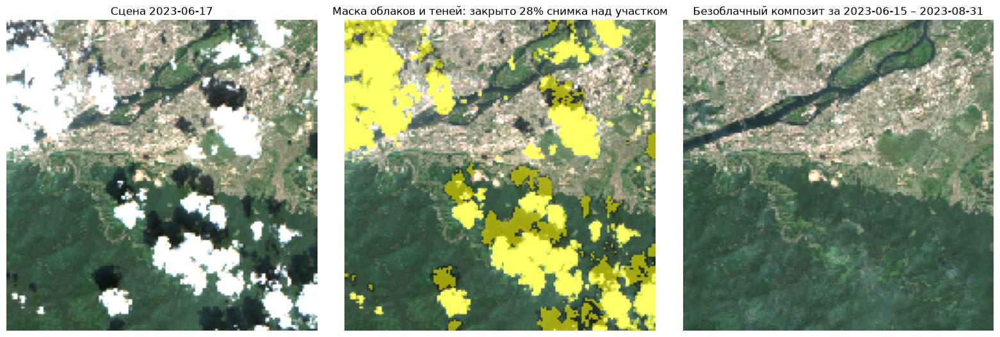

In [ ]:
def show_rgb(d):
    """Три канала в изображение для показа: растяжение яркости и осветление."""
    return np.clip(np.stack([d["B4"], d["B3"], d["B2"]], -1) / 0.18, 0, 1) ** (1 / 1.25)
valid = sc["B4"] > 0                                                     # Пиксели, покрытые листом снимка (вне листа – нули).
scene_rgb = show_rgb({k: sc[k] / 10000 for k in ["B4", "B3", "B2"]})      # Сцена: отражение хранится в тысячных долях.
scene_rgb[~valid] = np.nan                                               # Вне листа – пусто.
mask = (sc["cs_cdf"] < 0.6) & valid                                      # Облака и тени: ясность ниже порога.
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))                          # Три рисунка рядом.
ax[0].imshow(scene_rgb); ax[0].set_title(f"Сцена {scene_date:%Y-%m-%d}")   # Сцена как есть.
ax[1].imshow(scene_rgb); ax[1].imshow(np.where(mask, 1.0, np.nan), cmap="autumn", alpha=0.6, vmin=0, vmax=1)   # Маска поверх сцены.
ax[1].set_title(f"Маска облаков и теней: закрыто {100 * mask[valid].mean():.0f}% снимка над участком")
ax[2].imshow(show_rgb(cp)); ax[2].set_title(f"Безоблачный композит за {S2_PERIOD[0]} – {S2_PERIOD[1]}")   # Композит.
for a in ax: a.axis("off")                                               # Без осей.
plt.tight_layout(); plt.show()               # Показываем рисунок.

Слева — снимок одного дня с облаками и их тенями, в середине — то, что маска считает непригодным, справа — композит: облаков нет, растительность в полном развитии. Как он собирается, разобрано в разделе 3.

### **2.2. Глобальные цифровые модели рельефа**

| Модель | Как получена | Съёмка | Шаг | Система высот |
|---|---|---|---|---|
| Copernicus DEM GLO-30 | радарная интерферометрия, спутники TanDEM-X | 2011–2015 | 30 м | геоид EGM2008 |
| ALOS AW3D30 | оптическая стереосъёмка, спутник ALOS | 2006–2011 | 30 м | геоид EGM96 |
| NASADEM | радарная интерферометрия, миссия SRTM | 2000 | 30 м | геоид EGM96 |
| MERIT DEM | SRTM и AW3D30 с исправлением систематических ошибок, в том числе влияния растительности | 2000–2011 | 90 м | геоид EGM96 |

Радарная и оптическая съёмка регистрирует верхнюю границу объектов, поэтому в лесу все эти модели ближе к поверхности крон, чем к земле. Рисунок показывает, почему лазер ведёт себя иначе.

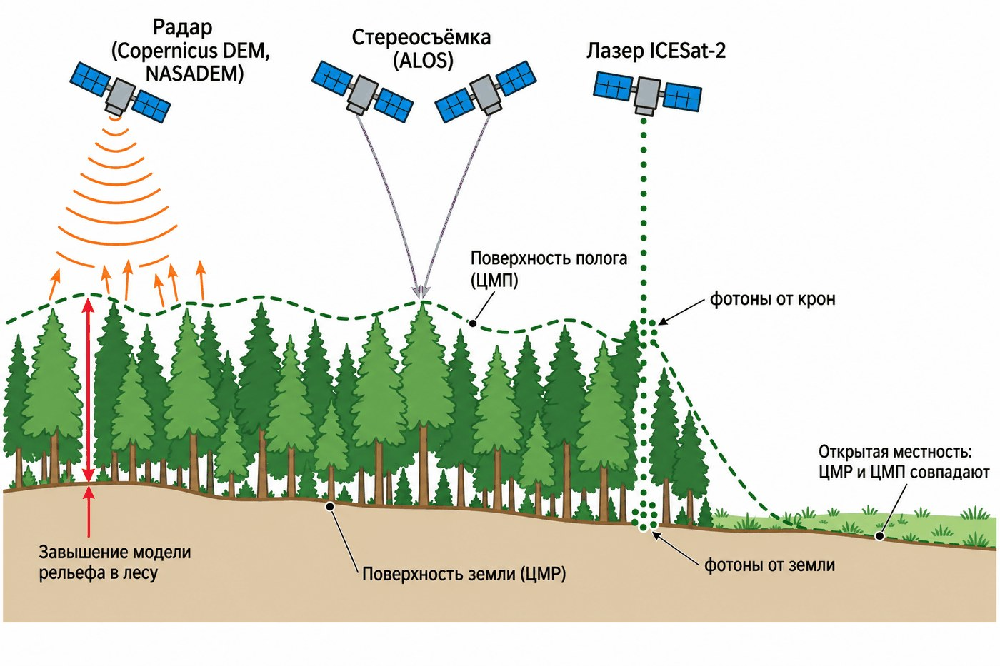

*Отражение радарного, оптического и лазерного сигналов над лесом и открытой местностью.*

Уточнять будем Copernicus, остальные модели нужны для сравнения. Загрузим четыре модели на сетку 120 м, построим отмывку рельефа и вычтем из Copernicus каждую из остальных. Разности посчитаем отдельно в лесу и вне леса по карте покрова WorldCover.

In [ ]:
dem120 = gee_to_numpy(dem_images(REGION), PREVIEW)                      # Четыре модели рельефа на сетке 120 м.
wc120 = gee_to_numpy(ee.ImageCollection("ESA/WorldCover/v200").first().rename("wc"), PREVIEW)["wc"]   # Карта покрова на той же сетке.
forest120 = wc120 == 10                                                  # Класс 10 WorldCover – деревья.
MODELS = [("cop", "Copernicus GLO-30"), ("alos", "ALOS AW3D30"), ("nasadem", "NASADEM"), ("merit", "MERIT DEM")]   # Ключ и название.
rows = []                                                                # Строки таблицы разностей.
for k, name in MODELS[1:]:                                               # Для каждой модели, кроме Copernicus:
    d = dem120["cop"] - dem120[k]                                        # разность высот, м,
    rows.append([name, np.nanmedian(d[forest120]), np.nanmedian(d[~forest120]), np.nanpercentile(np.abs(d), 90)])   # медианы в лесу и вне леса.
dem_diff = pd.DataFrame(rows, columns=["Модель", "Медиана разности с Copernicus в лесу, м", "Медиана разности вне леса, м", "90-й процентиль |разности|, м"]).round(2)
h_range = (float(np.nanmin(dem120["cop"])), float(np.nanmax(dem120["cop"])))   # Диапазон высот участка для реестра и проверки.
print(f"Высоты Copernicus на участке: {h_range[0]:.0f} … {h_range[1]:.0f} м")
dem_diff                                                                 # Показываем таблицу.

Высоты Copernicus на участке: 133 … 807 м


,Модель,"Медиана разности с Copernicus в лесу, м","Медиана разности вне леса, м","90-й процентиль |разности|, м"
0,ALOS AW3D30,0.58,1.34,5.82
1,NASADEM,3.53,1.34,6.23
2,MERIT DEM,6.49,0.94,10.56


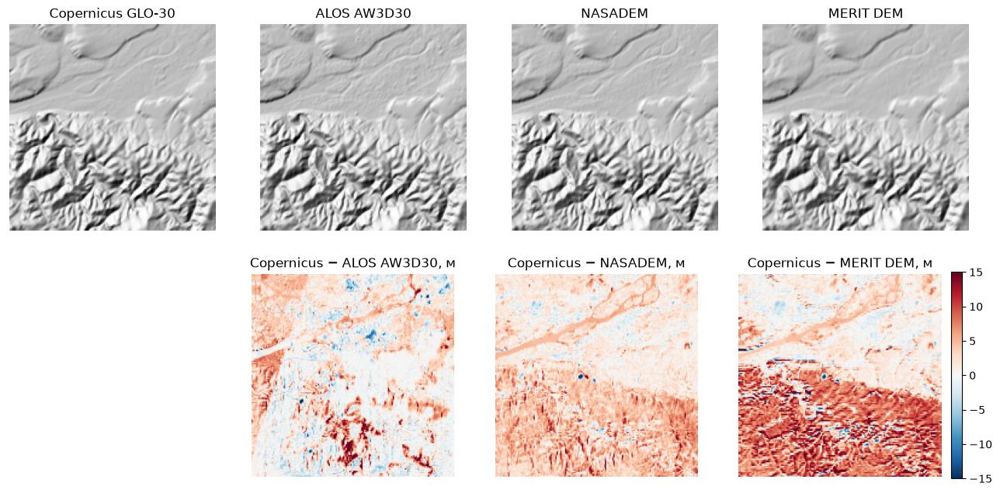

In [ ]:
ls = LightSource(315, 40)                                                # Источник света для отмывки: азимут 315°, высота 40°.
fig, ax = plt.subplots(2, 4, figsize=(16, 7.6))                          # Два ряда: отмывки и разности.
for a, (k, name) in zip(ax[0], MODELS):                                  # Верхний ряд – отмывка каждой модели.
    a.imshow(ls.hillshade(np.nan_to_num(dem120[k]), vert_exag=3, dx=120, dy=120), cmap="gray"); a.set_title(name); a.axis("off")
ax[1][0].axis("off")                                                     # Левая нижняя ячейка пустая.
for a, (k, name) in zip(ax[1][1:], MODELS[1:]):                          # Нижний ряд – разности с Copernicus.
    d = dem120["cop"] - dem120[k]                                        # Разность высот, м.
    im = a.imshow(d, cmap="RdBu_r", vmin=-15, vmax=15); a.set_title(f"Copernicus − {name}, м"); a.axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.02, pad=0.01)                      # Общая шкала разностей.
plt.show()                                      # Показываем рисунок.

Отмывки похожи: все модели передают один рельеф. Разность изображений показывает другое. Вне леса модели расходятся на метр с небольшим — в основном из-за разных систем высот (EGM2008 и EGM96). В лесу Copernicus выше NASADEM на 3,5 м и выше MERIT на 6,5 м, и рисунок разностей повторяет границы лесных массивов: MERIT исправлена за влияние растительности, а радар SRTM (NASADEM) проникает в кроны глубже. ALOS и Copernicus в лесу почти совпадают — обе модели передают поверхность крон. Это признак не случайной, а систематической ошибки, связанной с покровом. Какая модель ближе к истине, по самим моделям узнать нельзя — для этого нужен независимый эталон (раздел 2.4).

### **2.3. Карты покрова, высоты леса и потерь леса**

Три карты играют вспомогательные роли:
* **ESA WorldCover** (10 м, 2021 г.) — карта из 11 классов покрова, построенная машинным обучением по снимкам Sentinel-1 и Sentinel-2. Даёт обучающие метки для собственной карты покрова (раздел 6).
* **ETH Global Canopy Height** (10 м, 2020 г.) — высота полога леса, рассчитанная нейронной сетью по лидару GEDI и снимкам Sentinel-2. Служит признаком: чем выше полог, тем сильнее завышена модель рельефа.
* **Hansen Global Forest Change** (30 м, 2001–2025 гг.) — год, в котором на месте пикселя исчез лес (вырубка, пожар, ветровал); 0 — лес не исчезал. Нужна для очистки измерений (раздел 5).

In [ ]:
aux120 = gee_to_numpy(ee.Image("users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1").rename("eth").unmask(0)   # Высота леса, м (вне леса 0),
                      .addBands(ee.Image("UMD/hansen/global_forest_change_2025_v1_13").select("lossyear").unmask(0).rename("lossyear")), PREVIEW)   # и год потери леса.
label120 = np.zeros(wc120.shape, int)                                    # Классы покрова работы (1–7) на сетке 120 м.
for wc_code, our_class in WC_TO_CLASS.items():                           # Коды WorldCover → классы работы.
    label120[wc120 == wc_code] = our_class
shares = pd.DataFrame({"Класс": [CLASS_NAMES[c] for c in range(1, 8)],   # Доля каждого класса на участке:
                       "Доля участка, %": [round(100 * float((label120 == c).mean()), 1) for c in range(1, 8)]})
shares = shares[shares["Доля участка, %"] > 0].reset_index(drop=True)    # Только классы, которые есть на участке.
eth_forest = float(np.nanmedian(aux120["eth"][forest120]))               # Медианная высота полога в лесу.
loss_share = float(100 * (aux120["lossyear"] >= 11).mean())              # Доля участка с потерей леса после 2010 г.
print(f"Медианная высота полога в лесу: {eth_forest:.1f} м; потеря леса после 2010 г. на {loss_share:.1f}% участка")
shares                                                                   # Показываем таблицу.

Медианная высота полога в лесу: 23.0 м; потеря леса после 2010 г. на 1.8% участка


,Класс,"Доля участка, %"
0,Лес,64.4
1,Луга и пашня,7.4
2,Застройка,23.6
3,Открытый грунт,0.3
4,Вода,4.3


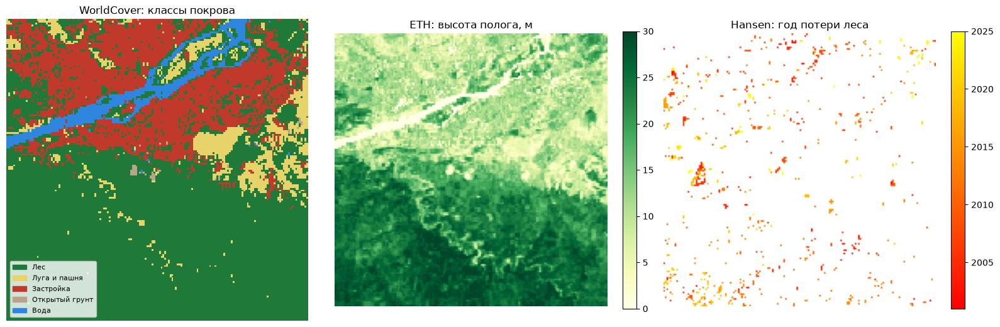

In [ ]:
cmap_cls = ListedColormap([CLASS_COLORS[i] for i in range(1, 8)])        # Палитра классов.
norm_cls = BoundaryNorm(np.arange(0.5, 8.5), 7)                          # Каждому номеру класса – свой цвет.
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))                          # Три карты рядом.
ax[0].imshow(np.ma.masked_equal(label120, 0), cmap=cmap_cls, norm=norm_cls, interpolation="nearest"); ax[0].set_title("WorldCover: классы покрова")
ax[0].legend(handles=[Patch(color=CLASS_COLORS[c], label=CLASS_NAMES[c]) for c in range(1, 8) if (label120 == c).any()], loc="lower left", fontsize=8)
im = ax[1].imshow(aux120["eth"], cmap="YlGn", vmin=0, vmax=30); ax[1].set_title("ETH: высота полога, м"); plt.colorbar(im, ax=ax[1], fraction=0.046)
loss = np.where(aux120["lossyear"] > 0, aux120["lossyear"] + 2000, np.nan)   # Год потери леса (пропуск – потерь не было).
im = ax[2].imshow(loss, cmap="autumn", vmin=2001, vmax=2025); ax[2].set_title("Hansen: год потери леса"); plt.colorbar(im, ax=ax[2], fraction=0.046)
for a in ax: a.axis("off")                                               # Без осей.
plt.tight_layout(); plt.show()                   # Показываем рисунок.

Лес занимает около двух третей участка, высота полога — порядка 20–25 м. Значит, ошибка модели рельефа в лесу будет измеряться метрами и десятками метров.

### **2.4. Лазерные измерения ICESat-2**

Спутник ICESat-2 (NASA, с 2018 г.) несёт лазерный высотомер ATLAS: 10 000 импульсов в секунду в зелёном диапазоне (532 нм) шестью лучами. Три пары лучей разнесены примерно на 3 км, лучи в паре — на 90 м; в каждой паре один луч сильный, другой в четыре раза слабее. Приёмник регистрирует отдельные отражённые фотоны, а по времени их возвращения рассчитывается высота точки отражения.

Сервис SlideRule обрабатывает эти фотоны на своих серверах: отделяет шум, землю и полог и рассчитывает высоту земли на отрезках трека (сегментах) длиной 100 м. Высота земли сегмента `h_ground` — медиана высот фотонов земли; она отсчитывается от эллипсоида WGS 84, а не от уровня моря (раздел 2.6).

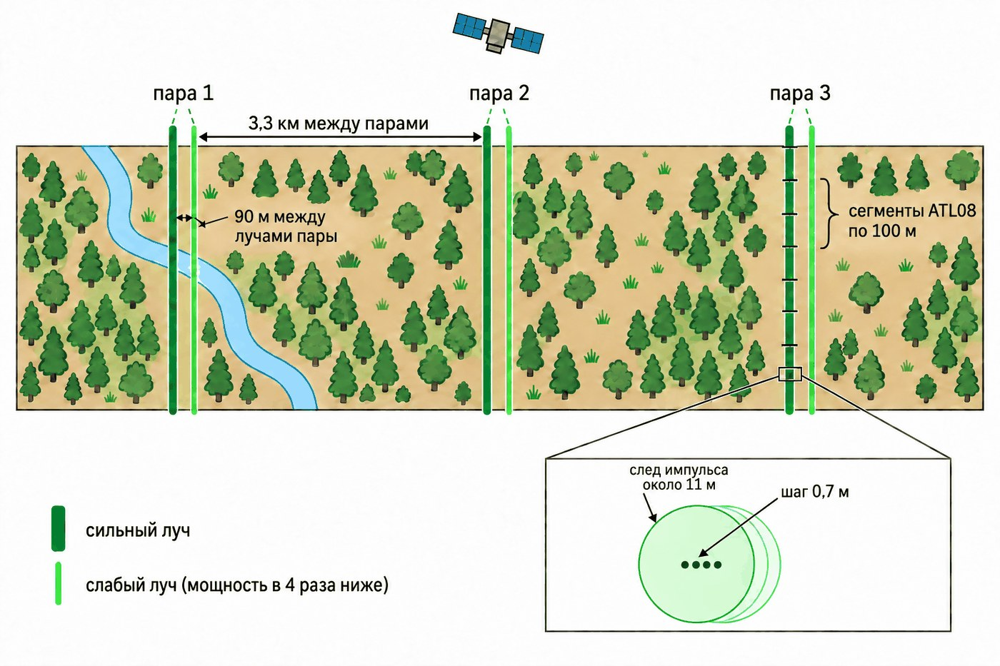

*Шесть лучей ICESat-2 и сегменты, по которым рассчитывается высота земли.*

In [ ]:
t = time.time()                                                          # Засекаем время.
isat = load_icesat2(ROI_BOUNDS, *ICESAT_PERIOD, cache=f"{OUT}/icesat2_atl08.parquet")   # Сегменты ATL08 участка.
print(f"Сегментов ICESat-2: {len(isat)}; треков: {isat.rgt.nunique()}; период {isat.time.min():%Y-%m} – {isat.time.max():%Y-%m}; {time.time() - t:.0f} с")

Сегментов ICESat-2: 31063; треков: 6; период 2018-11 – 2025-11; 0 с


In [ ]:
by_beam = isat.groupby("spot").agg(сегментов=("h_ground", "size"), фотонов_земли_медиана=("gnd_ph_count", "median"),   # Сводка по лучам.
                                   доля_с_найденной_землёй=("h_ground", lambda s: round(100 * s.notna().mean(), 1))).reset_index()
by_beam.columns = ["Луч (spot)", "Сегментов", "Фотонов земли в сегменте, медиана", "Сегментов с найденной землёй, %"]
by_beam["Мощность луча"] = np.where(by_beam["Фотонов земли в сегменте, медиана"] >= by_beam["Фотонов земли в сегменте, медиана"].median(), "сильный", "слабый")   # По числу фотонов.
by_month = isat.groupby(isat.time.dt.month).agg(сегментов=("h_ground", "size"), со_снегом=("snowcover", lambda s: round(100 * (s > 1).mean())))   # По месяцам.
by_month.index.name = "Месяц"; by_month.columns = ["Сегментов", "Со снегом, %"]
display(by_beam)                                                         # Таблица по лучам.
by_month.T                                                               # Таблица по месяцам (в строку).

,Луч (spot),Сегментов,"Фотонов земли в сегменте, медиана","Сегментов с найденной землёй, %",Мощность луча
0,1,5825,62.0,100.0,сильный
1,2,4528,20.0,100.0,слабый
2,3,5504,57.0,100.0,сильный
3,4,4628,22.0,100.0,слабый
4,5,5890,61.0,100.0,сильный
5,6,4688,22.0,100.0,слабый


Месяц,1,2,3,4,5,6,7,8,9,10,11,12
Сегментов,4633,2786,60,6368,2974,184,4571,3256,1090,3064,1670,407
"Со снегом, %",100,100,100,21,0,0,0,0,0,15,92,100


Сильные лучи (1, 3, 5) дают примерно в три раза больше фотонов земли, чем слабые. Зимой почти все измерения сделаны по снегу (флаг `snowcover`), их придётся исключить (раздел 5).

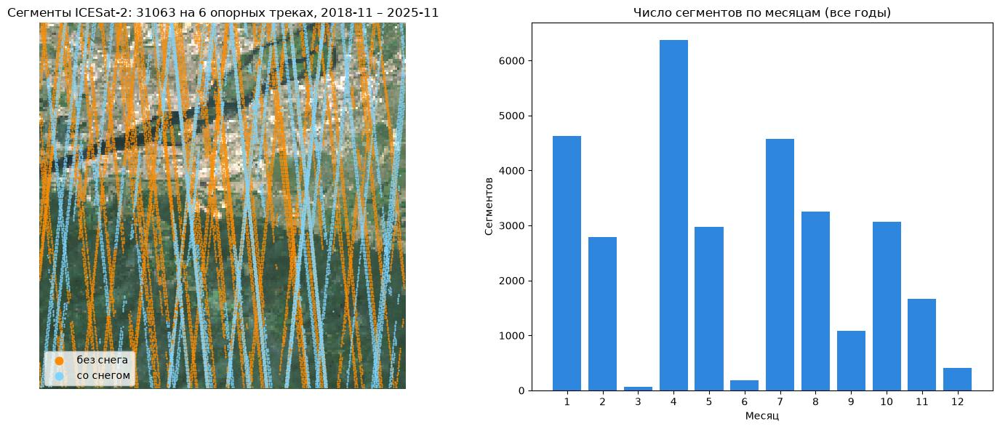

In [ ]:
pr_, pc_ = lonlat_to_rowcol(isat.lon.values, isat.lat.values, PREVIEW)   # Положение сегментов на сетке просмотра.
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})   # Карта и диаграмма.
ax[0].imshow(show_rgb(cp))                                                 # Подложка – композит.
snow = isat.snowcover.values > 1                                         # Сегменты со снегом.
ax[0].scatter(pc_[~snow], pr_[~snow], s=0.4, c="#ff8c00", label="без снега"); ax[0].scatter(pc_[snow], pr_[snow], s=0.4, c="#7fd4ff", label="со снегом")
ax[0].set_xlim(0, PREVIEW["W"]); ax[0].set_ylim(PREVIEW["H"], 0); ax[0].axis("off"); ax[0].legend(loc="lower left", markerscale=12)
ax[0].set_title(f"Сегменты ICESat-2: {len(isat)} на {isat.rgt.nunique()} опорных треках, {isat.time.min():%Y-%m} – {isat.time.max():%Y-%m}")
ax[1].bar(by_month.index, by_month["Сегментов"], color="#2e86de"); ax[1].set_xticks(range(1, 13)); ax[1].set_xlabel("Месяц"); ax[1].set_ylabel("Сегментов")
ax[1].set_title("Число сегментов по месяцам (все годы)")
plt.tight_layout(); plt.show()                   # Показываем рисунок.

Измерения лежат полосами с пробелами в несколько километров: это и есть «точечные» данные, между которыми высоту земли предстоит восстановить по изображениям.

### **2.5. Гравитационное поле GGMplus**

GGMplus — модель гравитационного поля Земли с шагом 0,002° (около 220 м) для суши между 60° ю. ш. и 60° с. ш. Она объединяет спутниковые гравиметрические миссии GRACE и GOCE (крупные детали поля), модель EGM2008 (средние) и притяжение рельефа, рассчитанное по SRTM (мелкие). Используются две величины:

* **возмущение силы тяжести** $\delta g$ — разность реальной силы тяжести и нормальной (рассчитанной для эллипсоида) в той же точке, мГал; 1 мГал = $10^{-5}$ м/с², примерно одна миллионная доля ускорения силы тяжести;
* **высота квазигеоида** $\zeta$, м — расстояние от эллипсоида до поверхности, от которой в России отсчитываются нормальные высоты.

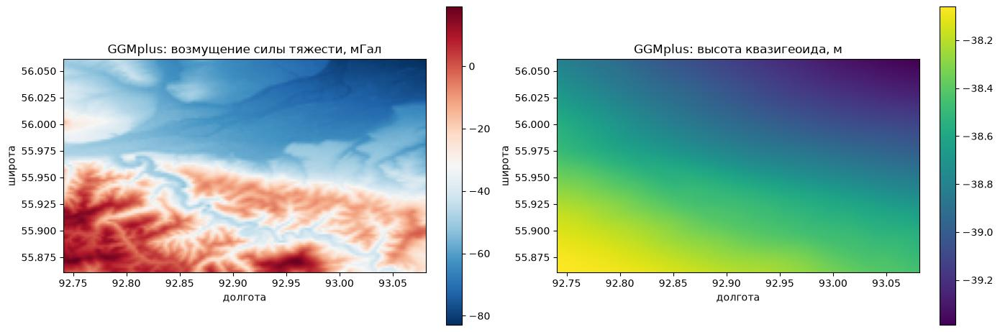

,Характеристика,Значение
0,Источник поля,фрагмент вокруг участка из подготовленных данных
1,Узлов сетки на участке,"101×171 с шагом 0,002° (около 220 м)"
2,"Узлов без данных, %",0.0
3,"Возмущения силы тяжести, мГал",-82.9 … 19.1
4,"Высота квазигеоида, м",-39.39 … -38.06


In [ ]:
dg_ll, g_lons, g_lats = load_ggmplus([ROI_BOUNDS[0] - 0.01, ROI_BOUNDS[1] - 0.01, ROI_BOUNDS[2] + 0.01, ROI_BOUNDS[3] + 0.01], "dg")   # Возмущения, мГал.
zeta_ll, _, _ = load_ggmplus([ROI_BOUNDS[0] - 0.01, ROI_BOUNDS[1] - 0.01, ROI_BOUNDS[2] + 0.01, ROI_BOUNDS[3] + 0.01], "geoid")   # Квазигеоид, м.
ggm_nan = 100 * np.isnan(dg_ll).mean()                                   # Доля узлов без данных (море, выход за 60°).
fig, ax = plt.subplots(1, 2, figsize=(14, 5))                            # Два рисунка рядом.
extent = [g_lons[0], g_lons[-1], g_lats[0], g_lats[-1]]                  # Границы сетки GGMplus в градусах.
im = ax[0].imshow(dg_ll, origin="lower", extent=extent, cmap="RdBu_r"); ax[0].set_title("GGMplus: возмущение силы тяжести, мГал"); plt.colorbar(im, ax=ax[0], fraction=0.04)
im = ax[1].imshow(zeta_ll, origin="lower", extent=extent, cmap="viridis"); ax[1].set_title("GGMplus: высота квазигеоида, м"); plt.colorbar(im, ax=ax[1], fraction=0.04)
for a in ax: a.set_xlabel("долгота"); a.set_ylabel("широта")
plt.tight_layout(); plt.show()                         # Показываем рисунок.
ggm_meta = pd.DataFrame([                                                # Сводка для реестра и проверки.
    ["Источник поля", "фрагмент вокруг участка из подготовленных данных" if ggm_source()[0] == "подготовленные данные" else f"{files_ru(len(ggm_source()[1]))} 5°×5° с сервера Curtin University"],
    ["Узлов сетки на участке", f"{dg_ll.shape[0]}×{dg_ll.shape[1]} с шагом 0,002° (около 220 м)"],
    ["Узлов без данных, %", round(ggm_nan, 2)],
    ["Возмущения силы тяжести, мГал", f"{np.nanmin(dg_ll):.1f} … {np.nanmax(dg_ll):.1f}"],
    ["Высота квазигеоида, м", f"{np.nanmin(zeta_ll):.2f} … {np.nanmax(zeta_ll):.2f}"],
], columns=["Характеристика", "Значение"])
ggm_meta                                                                 # Показываем таблицу.

Возмущения меняются на участке на десятки миллигал и повторяют крупные формы рельефа: в поле на поверхности входит притяжение гор и холмов. Это притяжение будет вычтено в разделе 8. Высота квазигеоида на участке около −39 м и меняется в пределах полутора метров.

### **2.6. Системы высот: эллипсоид, геоид, квазигеоид**

Спутниковые измерения дают *эллипсоидальную высоту* $h$ — расстояние по нормали от эллипсоида WGS 84, математической фигуры Земли. На практике высоты отсчитывают от уровня моря, точнее от *геоида* — уровенной поверхности поля силы тяжести, близкой к среднему уровню океана. Геоид отстоит от эллипсоида на *высоту геоида* $N$:

$$H = h - N.$$

Модели рельефа заданы над геоидом (Copernicus — над EGM2008, остальные — над EGM96), лазерные высоты — над эллипсоидом. Прежде чем сравнивать изображение рельефа с лазерными точками, высоты нужно привести к одной системе.

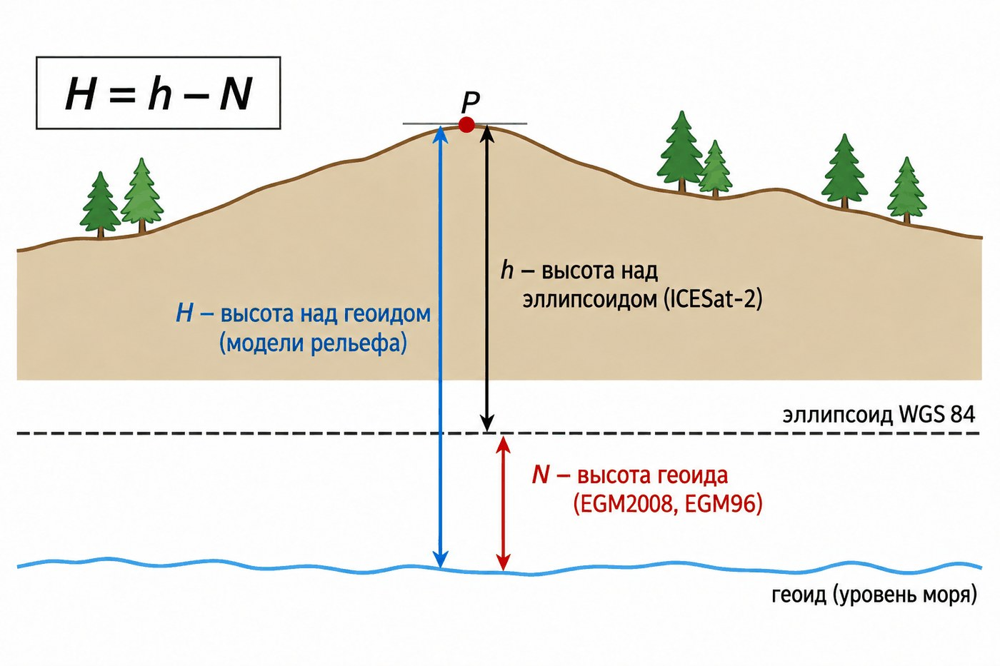

*Высота одной точки в трёх системах: эллипсоид, геоид и поверхность Земли.*

In [ ]:
lon_c, lat_c = (ROI_BOUNDS[0] + ROI_BOUNDS[2]) / 2, (ROI_BOUNDS[1] + ROI_BOUNDS[3]) / 2   # Центр участка.
pts = {"центр": (lon_c, lat_c), "юго-запад": (ROI_BOUNDS[0], ROI_BOUNDS[1]), "северо-восток": (ROI_BOUNDS[2], ROI_BOUNDS[3])}   # Три точки.
rows = []                                                                # Строки таблицы.
for name, (lo, la) in pts.items():                                       # Для каждой точки:
    n08 = -ellipsoid_to_geoid(0.0, lo, la, "EGM2008")                   # Высота геоида EGM2008 над эллипсоидом, м (точка с h = 0).
    n96 = -ellipsoid_to_geoid(0.0, lo, la, "EGM96")                     # То же для EGM96.
    gi, gj = int(round((la - g_lats[0]) / 0.002)), int(round((lo - g_lons[0]) / 0.002))   # Ближайший узел GGMplus.
    rows.append([name, n08, n96, n08 - n96, float(zeta_ll[gi, gj])])
geoid_tbl = pd.DataFrame(rows, columns=["Точка", "EGM2008: высота геоида, м", "EGM96: высота геоида, м", "Разность EGM2008 − EGM96, м", "GGMplus: высота квазигеоида, м"]).round(2)
geoid_tbl                                                                # Показываем таблицу.

,Точка,"EGM2008: высота геоида, м","EGM96: высота геоида, м","Разность EGM2008 − EGM96, м","GGMplus: высота квазигеоида, м"
0,центр,-39.11,-38.82,-0.29,-38.68
1,юго-запад,-38.49,-38.45,-0.03,-38.07
2,северо-восток,-39.75,-39.19,-0.56,-39.34


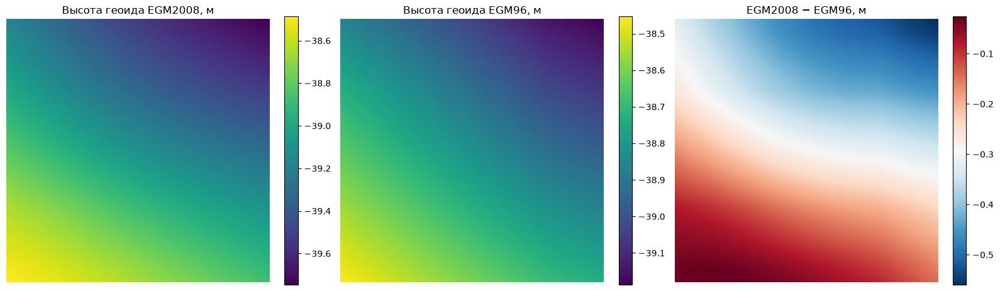

,Поверхность,"Минимум на участке, м","Максимум на участке, м"
0,EGM2008,-39.75,-38.49
1,EGM96,-39.19,-38.45
2,EGM2008 − EGM96,-0.56,-0.03
3,Квазигеоид GGMplus,-39.39,-38.06


In [ ]:
PREVIEW = make_grid(ROI_BOUNDS, res=120)                                 # Грубая сетка для карт геоида.
LONp, LATp = grid_lonlat(PREVIEW)                                        # Долгота и широта узлов.
N08 = -ellipsoid_to_geoid(np.zeros(LONp.size), LONp.ravel(), LATp.ravel(), "EGM2008").reshape(LONp.shape)   # Высота геоида EGM2008, м.
N96 = -ellipsoid_to_geoid(np.zeros(LONp.size), LONp.ravel(), LATp.ravel(), "EGM96").reshape(LONp.shape)     # Высота геоида EGM96, м.
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))                          # Три карты.
for a, arr, t in [(ax[0], N08, "Высота геоида EGM2008, м"), (ax[1], N96, "Высота геоида EGM96, м"), (ax[2], N08 - N96, "EGM2008 − EGM96, м")]:
    im = a.imshow(arr, cmap="viridis" if "−" not in t else "RdBu_r"); a.set_title(t); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()                           # Показываем рисунок.
geoid_stats = pd.DataFrame([["EGM2008", np.nanmin(N08), np.nanmax(N08)], ["EGM96", np.nanmin(N96), np.nanmax(N96)],
                            ["EGM2008 − EGM96", np.nanmin(N08 - N96), np.nanmax(N08 - N96)], ["Квазигеоид GGMplus", np.nanmin(zeta_ll), np.nanmax(zeta_ll)]],
                           columns=["Поверхность", "Минимум на участке, м", "Максимум на участке, м"]).round(2)
geoid_stats                                                              # Показываем таблицу.

Высота геоида на участке — около −39 м: без пересчёта лазерные высоты оказались бы на 39 м выше моделей рельефа. Разность EGM2008 и EGM96 — дециметры, она важна лишь при сравнении моделей между собой.

### **Выводы по разделу 2:**

1. Снимок, четыре модели рельефа, карты покрова и гравитационное поле — изображения с разным разрешением и в разных системах высот; лазерные измерения — точки вдоль треков
2. Разность изображений рельефа повторяет границы леса: глобальные модели завышают высоты в лесу систематически
3. Эталоном высоты земли служат лазерные измерения ICESat-2, но сравнивать их с моделями можно только после пересчёта от эллипсоида к геоиду

---

## **Раздел 3. Многоканальное изображение: безоблачный композит и спектральные индексы**

### **3.1. Маска облаков и медианный композит**

Облака нельзя отбрасывать целыми снимками: оценка облачности относится к листу 100×100 км, и над участком снимок может быть ясным при высокой общей облачности. Поэтому маска строится для каждого пикселя: пиксели с оценкой ясности Cloud Score+ ниже 0,6 исключаются. Затем для каждого пикселя из оставшихся наблюдений всех снимков периода вычисляется **медиана** — по каждому каналу отдельно.

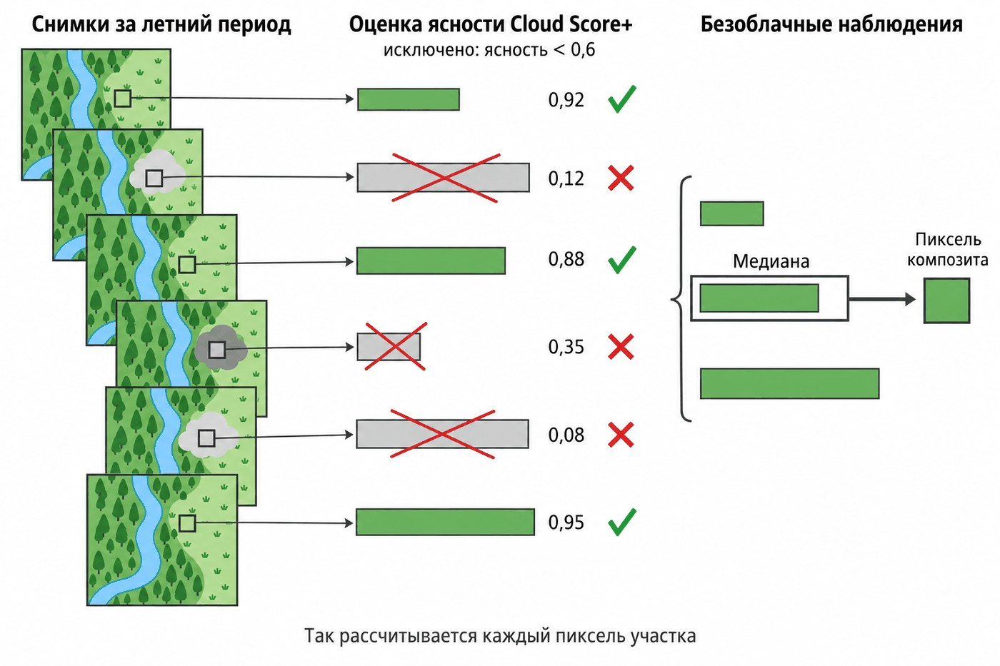

*Медианный композит для одного пикселя: облачные наблюдения отброшены маской, из оставшихся берётся медиана.*

С точки зрения обработки изображений это медианный фильтр не в пространстве, а во времени: для каждого пикселя упорядочиваются его значения на разных снимках и берётся среднее по порядку. Медиана не чувствительна к единичным выбросам — остаткам облаков, не распознанным маской, и теням, — тогда как среднее арифметическое они бы исказили.

Вместе с композитом одним запросом загружаются все остальные изображения: четыре модели рельефа, карта покрова, высота леса и год потери леса. Earth Engine пересчитывает их на сетку 30 м, и способ пересчёта зависит от смысла данных: высоты интерполируются билинейно, для классов покрова берётся самый частый класс среди пикселей 10 м внутри пикселя 30 м, для высоты леса — среднее.

In [ ]:
t = time.time()                                                          # Засекаем время загрузки.
s2_img, n_scenes = s2_composite(REGION, *S2_PERIOD)                      # Композит Sentinel-2 и число снимков.
all_layers = s2_img.addBands(dem_images(REGION)).addBands(auxiliary_images())   # Все слои одним изображением.
stack = gee_to_numpy(all_layers, GRID)                                   # Словарь {слой: массив на сетке участка}.
print(f"Каналов получено: {len(stack)}; время {time.time() - t:.0f} с")  # Сколько слоёв получено и за какое время.
s2_filter = pd.DataFrame([                                               # Таблица шагов фильтрации снимков.
    ["Отбор по территории и периоду", f"{S2_PERIOD[0]} – {S2_PERIOD[1]}", f"{n_scenes} снимков"],
    ["Маска облаков и теней Cloud Score+", "cs_cdf ≥ 0,6", f"медиана {np.nanmedian(stack['n_clear']):.0f} безоблачных наблюдений на пиксель (минимум {np.nanmin(stack['n_clear']):.0f})"],
    ["Медианный композит", "медиана по каждому пикселю", f"пикселей без данных: {100 * np.isnan(stack['B4']).mean():.2f}%"],
], columns=["Шаг фильтрации", "Правило", "Результат"])
s2_filter                                                                # Показываем таблицу.

Каналов получено: 17; время 27 с


,Шаг фильтрации,Правило,Результат
0,Отбор по территории и периоду,2023-06-15 – 2023-08-31,120 снимков
1,Маска облаков и теней Cloud Score+,"cs_cdf ≥ 0,6",медиана 16 безоблачных наблюдений на пиксель (...
2,Медианный композит,медиана по каждому пикселю,пикселей без данных: 0.00%


Медиана числа безоблачных наблюдений на пиксель — главный показатель качества композита: при десяти и более наблюдениях медиана устойчива. Пикселей без данных быть не должно.

### **3.2. Композит, отмывка рельефа и число наблюдений**

Коэффициенты отражения суши обычно меньше 0,2, поэтому для показа значения растягиваются (делятся на 0,18) и немного осветляются гамма-коррекцией. Рельеф показан *отмывкой*: поверхность освещается условным источником света с северо-запада под углом 40°, склоны, обращённые к свету, светлее, противоположные — темнее. Отмывка — тоже операция над изображением: яркость пикселя зависит от наклона и ориентации поверхности, то есть от производных высоты.

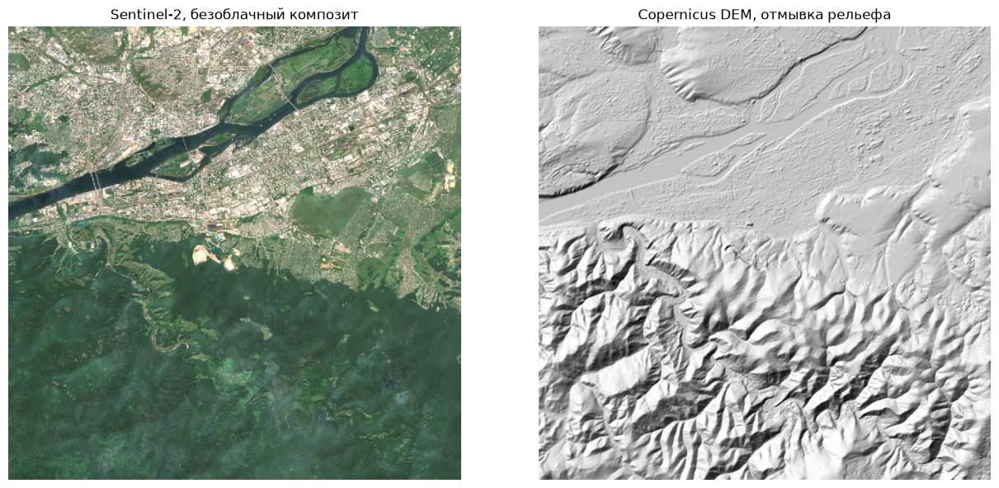

In [ ]:
rgb = np.stack([stack["B4"], stack["B3"], stack["B2"]], -1)              # Красный, зелёный, синий каналы.
rgb = np.clip(rgb / 0.18, 0, 1) ** (1 / 1.25)                           # Растяжение яркости и осветление для показа.
ls = LightSource(315, 40)                                                # Источник света: азимут 315°, высота 40°.
fig, ax = plt.subplots(1, 2, figsize=(13, 6))                            # Два рисунка рядом.
ax[0].imshow(rgb); ax[0].set_title("Sentinel-2, безоблачный композит")   # Слева – композит.
ax[1].imshow(ls.hillshade(stack["cop"], vert_exag=3, dx=30, dy=30), cmap="gray"); ax[1].set_title("Copernicus DEM, отмывка рельефа")  # Справа – отмывка.
for a in ax: a.axis("off")                                               # Без осей координат.
plt.tight_layout(); plt.show()               # Показываем рисунок.

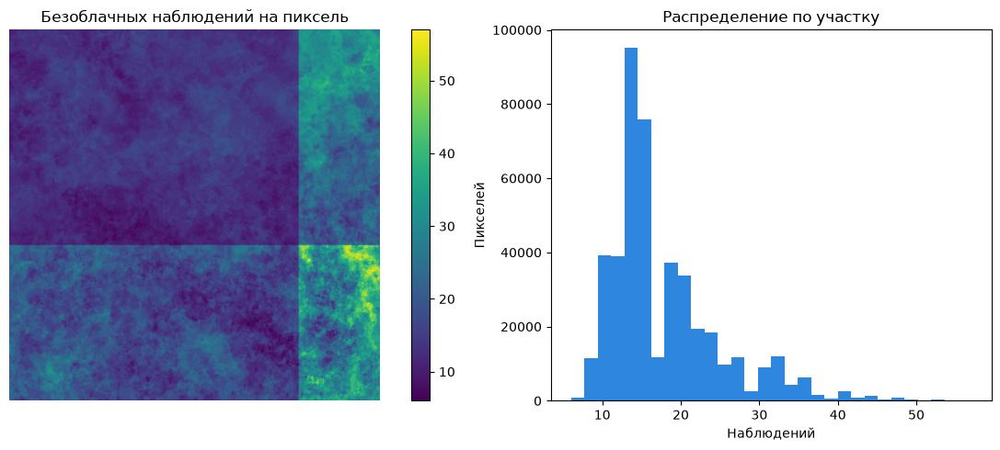

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.4, 1]})   # Карта и гистограмма.
im = ax[0].imshow(stack["n_clear"], cmap="viridis"); ax[0].set_title("Безоблачных наблюдений на пиксель"); ax[0].axis("off"); plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].hist(stack["n_clear"].ravel(), bins=30, color="#2e86de"); ax[1].set_xlabel("Наблюдений"); ax[1].set_ylabel("Пикселей"); ax[1].set_title("Распределение по участку")
plt.tight_layout(); plt.show()                # Показываем рисунок.

Число наблюдений меньше там, где облака бывают чаще, и на стыке листов снимка, но и там его хватает для устойчивой медианы.

### **3.3. Как порог ясности и период меняют композит**

Композит зависит от двух решений: порога ясности (0,5; 0,6; 0,7) и периода съёмки (лето, весна, весь год). Для каждого варианта композит рассчитывается на сервере заново; чтобы это заняло секунды, варианты сравниваются на грубой сетке 120 м.

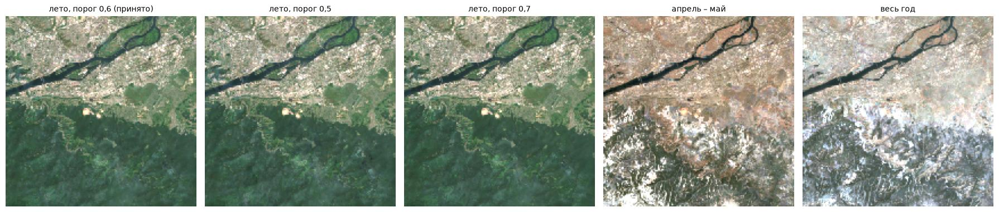

,Вариант,Период,Порог ясности,Снимков,"Безоблачных наблюдений на пиксель, медиана","Пикселей без данных, %"
0,"лето, порог 0,6 (принято)",2023-06-15 – 2023-08-31,0.6,120,16.0,0.0
1,"лето, порог 0,5",2023-06-15 – 2023-08-31,0.5,120,18.0,0.0
2,"лето, порог 0,7",2023-06-15 – 2023-08-31,0.7,120,13.0,0.0
3,апрель – май,2023-04-01 – 2023-05-31,0.6,96,20.0,0.0
4,весь год,2023-01-01 – 2023-12-31,0.6,576,122.0,0.0


In [ ]:
PREVIEW = make_grid(ROI_BOUNDS, res=120)                                 # Грубая сетка для быстрых сравнений.
def show_rgb(d, scale=1.0):
    """Три канала композита в изображение для показа."""
    return np.clip(np.stack([d["B4"], d["B3"], d["B2"]], -1) / scale / 0.18, 0, 1) ** (1 / 1.25)
year = S2_PERIOD[0][:4]                                                  # Год выбранного периода.
variants = [("лето, порог 0,6 (принято)", S2_PERIOD, 0.6), ("лето, порог 0,5", S2_PERIOD, 0.5), ("лето, порог 0,7", S2_PERIOD, 0.7),
            ("апрель – май", (f"{year}-04-01", f"{year}-05-31"), 0.6), ("весь год", (f"{year}-01-01", f"{year}-12-31"), 0.6)]   # Варианты.
rows, previews = [], []                                                  # Строки таблицы и изображения.
for name, period, thr in variants:                                       # Для каждого варианта:
    img, n = s2_composite(REGION, *period, cs_threshold=thr)             # Композит на сервере.
    d = gee_to_numpy(img.select(["B4", "B3", "B2", "n_clear"]), PREVIEW)   # Каналы и число наблюдений на сетке 120 м.
    rows.append([name, f"{period[0]} – {period[1]}", thr, n, np.nanmedian(d["n_clear"]), 100 * np.isnan(d["B4"]).mean()])
    previews.append((name, d))
comp_var = pd.DataFrame(rows, columns=["Вариант", "Период", "Порог ясности", "Снимков", "Безоблачных наблюдений на пиксель, медиана", "Пикселей без данных, %"]).round(1)
fig, ax = plt.subplots(1, len(previews), figsize=(18, 4.3))              # Композиты в ряд.
for a, (name, d) in zip(ax, previews):
    a.imshow(show_rgb(d)); a.set_title(name, fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()              # Показываем рисунок.
comp_var                                                                 # Показываем таблицу.

Порог ясности почти не меняет изображение: Cloud Score+ уверенно отделяет облака, меняется лишь число наблюдений на пиксель. Период меняет сам объект съёмки: весной на композите снег и неразвитая листва, за год смешиваются сезоны, и контраст между классами падает. Период выбирается по задаче, а не по принципу «чем больше снимков, тем лучше»: для карты покрова нужен сезон полной вегетации.

### **3.4. Спектральные индексы**

Спектральный индекс — попиксельная арифметика над каналами. Нормализованная разность $(a - b)/(a + b)$ двух каналов не зависит от общей освещённости пикселя (тень, склон) и меняется от −1 до 1:

| Индекс | Каналы | Что показывает |
|---|---|---|
| NDVI | ближний ИК (B8) и красный (B4) | зелёная растительность: хлорофилл поглощает красный и отражает ближний ИК |
| NDWI | зелёный (B3) и ближний ИК (B8) | вода: она поглощает ближний ИК |
| NDBI | коротковолновый ИК (B11) и ближний ИК (B8) | застройка и открытый грунт |

Построим карты индексов и их распределения по классам карты WorldCover: так видно, какие классы индексы разделяют, а какие нет.

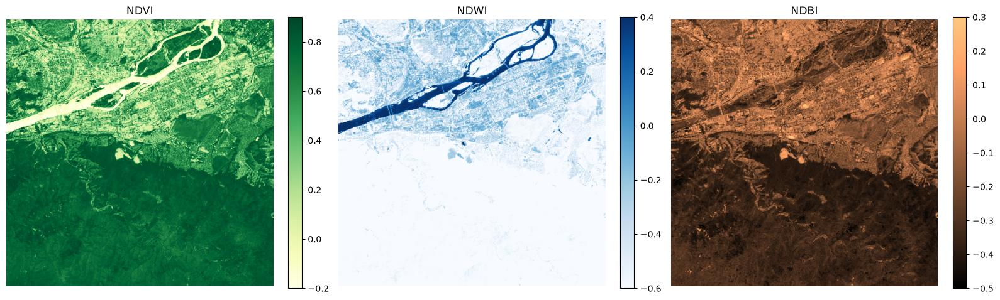

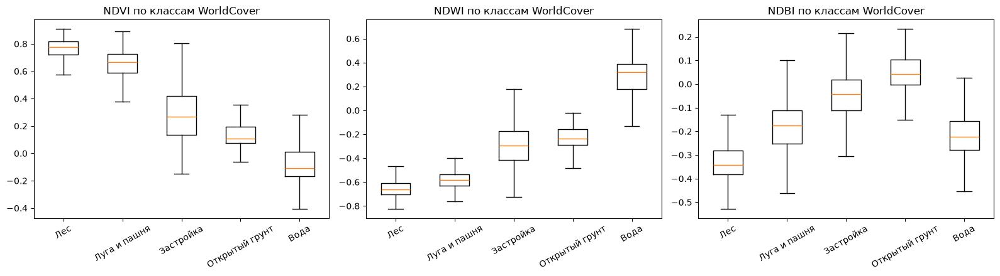

,Класс,Ячеек,"NDVI, медиана","NDWI, медиана","NDBI, медиана"
0,Лес,289901,0.78,-0.66,-0.34
1,Луга и пашня,35111,0.67,-0.58,-0.18
2,Застройка,101055,0.27,-0.29,-0.04
3,Открытый грунт,1929,0.11,-0.23,0.04
4,Вода,18874,-0.10,0.32,-0.22


In [ ]:
label_map = np.zeros(stack["wc"].shape, int)                             # Классы покрова работы (1–7); 0 – класс не используется.
for wc_code, our_class in WC_TO_CLASS.items():                           # Коды WorldCover → классы работы.
    label_map[stack["wc"] == wc_code] = our_class
classes_present = [c for c in CLASS_NAMES if (label_map == c).sum() >= 200]   # Классы, которых на участке достаточно.
fig, ax = plt.subplots(1, 3, figsize=(16, 5))                            # Три карты индексов.
for a, (name, cmap, lim) in zip(ax, [("NDVI", "YlGn", (-0.2, 0.9)), ("NDWI", "Blues", (-0.6, 0.4)), ("NDBI", "copper", (-0.5, 0.3))]):
    im = a.imshow(stack[name], cmap=cmap, vmin=lim[0], vmax=lim[1]); a.set_title(name); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()                         # Показываем рисунок.
rng = np.random.default_rng(SEED)                                        # Генератор случайных чисел.
sample = rng.choice(label_map.size, 60000, replace=False)                # Выборка ячеек для диаграмм.
sample = sample[label_map.ravel()[sample] > 0]                           # Только ячейки с классом.
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))                          # Распределения индексов по классам.
rows = []                                                                # Строки таблицы медиан.
for a, name in zip(ax, ["NDVI", "NDWI", "NDBI"]):
    vals = stack[name].ravel()[sample]; labs = label_map.ravel()[sample]
    a.boxplot([vals[labs == c] for c in classes_present], tick_labels=[CLASS_NAMES[c] for c in classes_present], showfliers=False)
    a.set_title(f"{name} по классам WorldCover"); a.tick_params(axis="x", rotation=30)
for c in classes_present:                                                # Медианы индексов по классам.
    m_ = label_map == c
    rows.append([CLASS_NAMES[c], int(m_.sum())] + [np.nanmedian(stack[n][m_]) for n in ["NDVI", "NDWI", "NDBI"]])
idx_by_class = pd.DataFrame(rows, columns=["Класс", "Ячеек", "NDVI, медиана", "NDWI, медиана", "NDBI, медиана"]).round(2)
plt.tight_layout(); plt.show()              # Показываем рисунок.
idx_by_class                                                             # Показываем таблицу.

Лес и луга отличаются высоким NDVI, вода — положительным NDWI, застройка и открытый грунт — высоким NDBI. Ни один индекс не разделяет все классы сразу: лес и луга по NDVI перекрываются, застройка и открытый грунт по NDBI тоже. Поэтому классификатор в разделе 6 использует все каналы и индексы вместе, а к ним добавляются признаки рельефа.

### **Выводы по разделу 3:**

1. **Безоблачный композит** — медианный фильтр во времени: для каждого пикселя берётся медиана безоблачных наблюдений, что устойчиво к остаткам облаков и теней
2. **Маска облаков** строится по пикселям, а не по снимкам: облачность снимка относится ко всему листу 100×100 км
3. **Период съёмки** важнее порога ясности: он определяет, что изображено (снег, листва)
4. **Спектральные индексы** — попиксельная арифметика каналов, устойчивая к освещённости; по отдельности они классы не разделяют

---

## **Раздел 4. Рельеф как изображение**

Модель рельефа — одноканальное изображение, у которого значение пикселя — высота в метрах. К нему применимы те же операции, что к снимку, но смысл у них геометрический: разность соседних пикселей — наклон поверхности, отклонение от среднего в окне — положение на склоне.

### **4.1. Трёхмерная поверхность**

Самый наглядный способ увидеть изображение рельефа — построить его как поверхность: по осям X и Y — координаты пикселя, по оси Z — значение. Если раскрасить поверхность снимком, получается трёхмерная модель местности. Вертикальный масштаб увеличен в три раза, иначе на участке 20 км перепад в несколько сотен метров был бы почти незаметен.

In [ ]:
dem = stack["cop"].astype(np.float64)                                    # Изображение рельефа Copernicus: значение пикселя – высота, м.

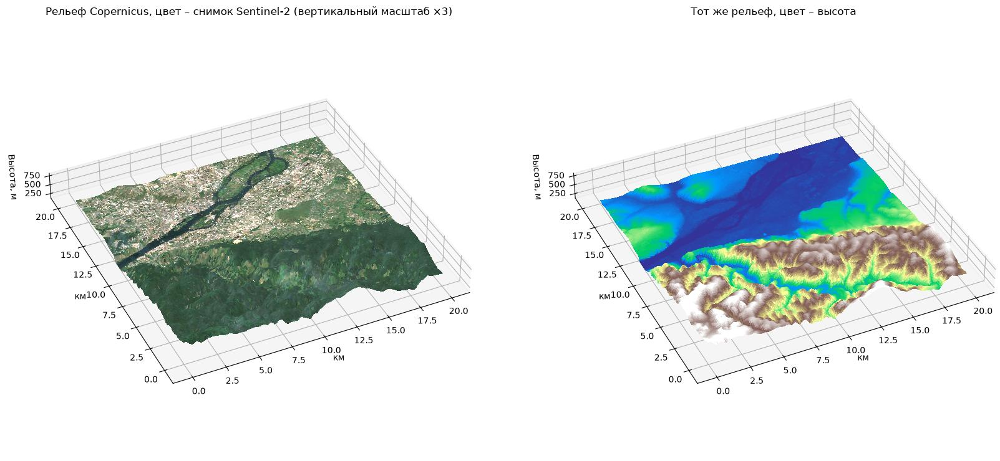

In [ ]:
fig = plt.figure(figsize=(17, 7.5))                                      # Две трёхмерные поверхности рядом.
ax = fig.add_subplot(1, 2, 1, projection="3d")                           # Левая: цвет – снимок.
surface_3d(ax, dem, colors=rgb, title="Рельеф Copernicus, цвет – снимок Sentinel-2 (вертикальный масштаб ×3)")
ax = fig.add_subplot(1, 2, 2, projection="3d")                           # Правая: цвет – высота.
surface_3d(ax, dem, cmap="terrain", title="Тот же рельеф, цвет – высота")
plt.tight_layout(); plt.show()

Тайга заповедника «Столбы» лежит на возвышенности на юге участка, Енисей и город — в долине на севере. Отдельные останцы-«столбы» на этой сетке не видны: они меньше пикселя 30 м.

### **4.2. Фильтры низких и высоких частот**

Сглаживание — замена каждого пикселя средним значением в окне $k \times k$ (функция `uniform_filter`). Это свёртка изображения с ядром, все элементы которого равны $1/k^2$. Она оставляет плавные изменения (**низкие частоты**) и убирает мелкие детали. Разность исходного и сглаженного изображения оставляет только мелкие детали (**высокие частоты**). Для рельефа эта разность имеет собственное название — индекс топографического положения TPI: положительный на гребнях и вершинах, отрицательный в долинах и ложбинах.

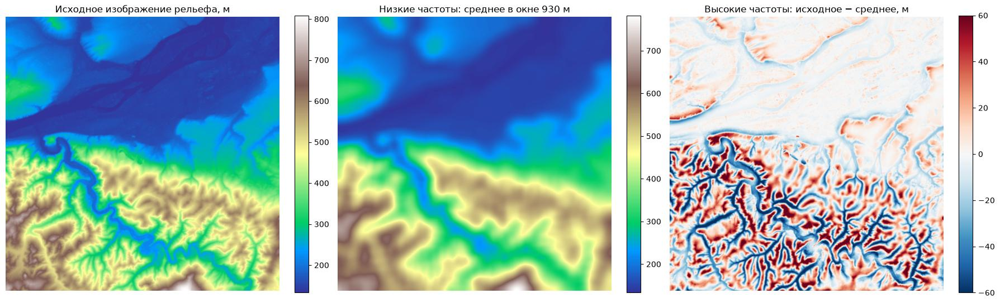

In [ ]:
low = uniform_filter(dem, 31)                                            # Фильтр низких частот: среднее в окне 31×31 пиксель (930 м).
high = dem - low                                                         # Фильтр высоких частот: отклонение от среднего (это и есть TPI 31×31).
fig, ax = plt.subplots(1, 3, figsize=(18, 5.3))                          # Три изображения рядом.
for a, arr, t, cmap, lim in [(ax[0], dem, "Исходное изображение рельефа, м", "terrain", None),
                             (ax[1], low, "Низкие частоты: среднее в окне 930 м", "terrain", None),
                             (ax[2], high, "Высокие частоты: исходное − среднее, м", "RdBu_r", (-60, 60))]:
    im = a.imshow(arr, cmap=cmap, vmin=lim[0] if lim else None, vmax=lim[1] if lim else None)
    a.set_title(t); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

Сглаженное изображение показывает крупные формы — возвышенность и долину, высокочастотное — гребни и долины притоков. Тот же приём — сглаживание и вычитание — дальше применяется к гравитационному полю, чтобы отделить глубинные структуры от локальных аномалий (раздел 8).

### **4.3. Признаки рельефа**

Для каждого пикселя рассчитываются четыре признака, каждый — фильтром в окне:

| Признак | Как считается | Что показывает |
|---|---|---|
| уклон `slope` | $\arctan \sqrt{(\partial z/\partial x)^2 + (\partial z/\partial y)^2}$; производные — разностями соседних пикселей (`np.gradient`, ядро $[-1, 0, 1] / 2\Delta$) | крутизна склона, градусы |
| `tpi7` | высота минус среднее в окне 7×7 (210 м) | мелкие гребни и ложбины |
| `tpi31` | высота минус среднее в окне 31×31 (930 м) | положение на склоне долины |
| шероховатость `rough7` | стандартное отклонение высоты в окне 7×7: $\sqrt{\overline{z^2} - \bar z^2}$ | изрезанность поверхности |

Эти признаки понадобятся классификатору (по ним лес на склонах отличается от застройки в долине) и модели уточнения высот (ошибка модели рельефа растёт на крутых склонах). Посмотрим на карты признаков и на их взаимосвязь: сильно коррелированные признаки несут одну и ту же информацию.

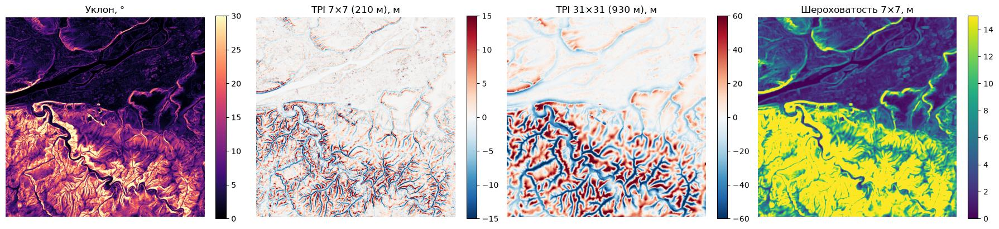

,высота,slope,tpi7,tpi31,rough7,NDVI,высота леса ETH
высота,1.00,0.51,0.13,0.27,0.54,0.62,0.76
slope,0.51,1.00,0.02,-0.01,0.95,0.51,0.64
tpi7,0.13,0.02,1.00,0.68,0.02,-0.00,0.04
tpi31,0.27,-0.01,0.68,1.00,-0.01,0.04,0.04
rough7,0.54,0.95,0.02,-0.01,1.00,0.53,0.67
NDVI,0.62,0.51,-0.00,0.04,0.53,1.00,0.79
высота леса ETH,0.76,0.64,0.04,0.04,0.67,0.79,1.00


In [ ]:
REL = relief_features(dem)                                               # Уклон, TPI, шероховатость.
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))                          # Четыре карты признаков.
for a, (k, t, cmap, lim) in zip(ax, [("slope", "Уклон, °", "magma", (0, 30)), ("tpi7", "TPI 7×7 (210 м), м", "RdBu_r", (-15, 15)),
                                     ("tpi31", "TPI 31×31 (930 м), м", "RdBu_r", (-60, 60)), ("rough7", "Шероховатость 7×7, м", "viridis", (0, 15))]):
    im = a.imshow(REL[k], cmap=cmap, vmin=lim[0], vmax=lim[1]); a.set_title(t); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()                # Показываем рисунок.
feat_tbl = pd.DataFrame({"высота": dem.ravel(), **{k: v.ravel() for k, v in REL.items()}, "NDVI": stack["NDVI"].ravel(), "высота леса ETH": stack["eth"].ravel()})
corr_tbl = feat_tbl.sample(50000, random_state=SEED).corr().round(2)    # Корреляции признаков по выборке ячеек.
corr_tbl                                                                 # Показываем таблицу.

Уклон и шероховатость почти взаимозаменяемы: оба растут на крутых склонах, их корреляция близка к единице. TPI двух масштабов связаны умеренно и описывают разное: мелкий выделяет гребни и ложбины, крупный — положение на склоне долины. Высота леса ETH связана и с высотой, и с NDVI: лес приурочен к возвышенностям.

### **Выводы по разделу 4:**

1. **Изображение рельефа** обрабатывается теми же операциями, что и снимок, но они имеют геометрический смысл: производная — уклон, отклонение от среднего — положение на склоне
2. **Фильтр низких частот** (среднее в окне) оставляет крупные формы, **фильтр высоких частот** (исходное минус среднее) — мелкие детали
3. **Трёхмерная поверхность** с текстурой снимка — наглядное представление изображения рельефа

---

## **Раздел 5. Точечные измерения: фильтрация, привязка к изображению и очистка**

Лазерные измерения — не изображение, а таблица точек с координатами. Чтобы использовать их как эталон для изображения рельефа, нужно: отбросить ненадёжные измерения, привести высоты к той же системе, «снять» значения изображений в каждой точке и исключить точки, где сравнение некорректно.

### **5.1. Откуда берётся высота земли: облако фотонов**

Высота сегмента — медиана высот фотонов земли. Чтобы понять, что за ней стоит, посмотрим на исходные данные — отдельные фотоны продукта ATL03 — на одном километре трека в лесу. Каждому фотону алгоритм ATL08 присвоил класс: шум, земля, полог, верх полога.

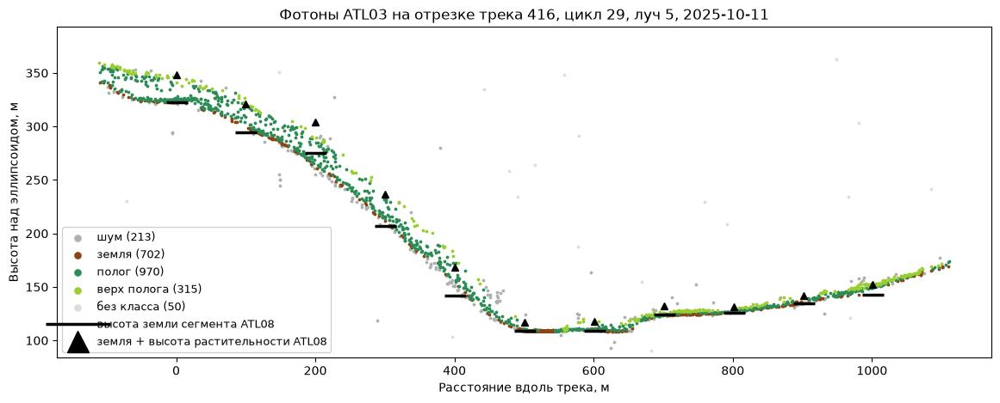

Фотонов земли на сегмент: 64; медиана числа фотонов земли по таблице ATL08: 29


,шум,земля,полог,верх полога,без класса
Фотонов,213,702,970,315,50


In [ ]:
from sliderule import icesat2                                            # Константы запроса к сервису SlideRule.
isat["trk"] = isat.rgt.astype(str) + "_" + isat.cycle.astype(str) + "_" + isat.spot.astype(str)   # Одна линия: трек, цикл, луч.
summer = isat[isat.snowcover <= 1]                                       # Летние измерения (без снега).
line = summer[summer.trk == summer.groupby("trk").size().idxmax()].sort_values("lat")   # Самая длинная летняя линия.
piece = line.iloc[len(line) // 2 - 5: len(line) // 2 + 6]               # Одиннадцать сегментов из середины линии (1,1 км).
day = piece.time.min().strftime("%Y-%m-%d")                              # Дата пролёта.
lon0, lon1, lat0, lat1 = piece.lon.min() - 0.02, piece.lon.max() + 0.02, piece.lat.min() - 0.001, piece.lat.max() + 0.001   # Рамка отрезка.
parms = {"poly": [{"lon": lon0, "lat": lat0}, {"lon": lon1, "lat": lat0}, {"lon": lon1, "lat": lat1}, {"lon": lon0, "lat": lat1}, {"lon": lon0, "lat": lat0}],
         "srt": icesat2.SRT_LAND, "cnf": icesat2.CNF_POSSIBLE_TEP, "len": 100.0, "res": 100.0, "cnt": 1, "ats": 0.0,   # Все фотоны, сегменты 100 м.
         "atl08_class": ["atl08_noise", "atl08_ground", "atl08_canopy", "atl08_top_of_canopy", "atl08_unclassified"],   # Классы ATL08.
         "t0": f"{day}T00:00:00Z", "t1": f"{day}T23:59:59Z"}             # Только этот пролёт.
ph = load_photons(parms, cache=f"{OUT}/icesat2_atl03_отрезок.parquet")   # Фотоны ATL03 с классами ATL08.
ph = ph[ph.spot == piece.spot.iloc[0]].copy()                            # Только выбранный луч.
to_m = Transformer.from_crs("EPSG:4326", GRID["crs"], always_xy=True) if "GRID" in globals() else Transformer.from_crs("EPSG:4326", make_grid(ROI_BOUNDS)["crs"], always_xy=True)
px, py = to_m.transform(ph.geometry.x.values, ph.geometry.y.values)      # Фотоны в метрах.
sx, sy = to_m.transform(piece.lon.values, piece.lat.values)              # Центры сегментов в метрах.
v = np.array([sx[-1] - sx[0], sy[-1] - sy[0]]); v /= np.hypot(*v)        # Направление линии.
ph["dist"] = (px - sx[0]) * v[0] + (py - sy[0]) * v[1]                   # Расстояние вдоль линии от первого сегмента, м.
seg_dist = (sx - sx[0]) * v[0] + (sy - sy[0]) * v[1]                     # То же для сегментов.
classes = {0: ("шум", "#b0b0b0"), 1: ("земля", "#8b4513"), 2: ("полог", "#2e8b57"), 3: ("верх полога", "#9acd32"), 4: ("без класса", "#dddddd")}
fig, ax = plt.subplots(figsize=(14, 5))                                  # Профиль фотонов.
for code_, (name, color) in classes.items():                             # Каждый класс своим цветом.
    m_ = ph.atl08_class == code_
    if m_.any(): ax.scatter(ph.dist[m_], ph.height[m_], s=3, color=color, label=f"{name} ({int(m_.sum())})")
ax.plot(seg_dist, piece.h_ground.values, "k_", markersize=18, mew=2.5, label="высота земли сегмента ATL08")   # Высоты земли сегментов.
ax.plot(seg_dist, (piece.h_ground + piece.h_canopy.fillna(0)).values, "k^", markersize=6, label="земля + высота растительности ATL08")
top = (piece.h_ground + piece.h_canopy.fillna(0)).max()                 # Верх полога на отрезке.
ax.set_ylim(piece.h_ground.min() - 25, top + 45)                         # Показываем только окрестность поверхности: шум выше и ниже обрезан.
ax.set_xlabel("Расстояние вдоль трека, м"); ax.set_ylabel("Высота над эллипсоидом, м"); ax.legend(loc="best", fontsize=9, markerscale=3, framealpha=0.9)
ax.set_title(f"Фотоны ATL03 на отрезке трека {piece.rgt.iloc[0]}, цикл {piece.cycle.iloc[0]}, луч {piece.spot.iloc[0]}, {day}")
plt.show()                                              # Показываем рисунок.
ph_tbl = ph.groupby("atl08_class").size().rename("Фотонов").to_frame(); ph_tbl.index = [classes[c][0] for c in ph_tbl.index]
print(f"Фотонов земли на сегмент: {int((ph.atl08_class == 1).sum()) / len(piece):.0f}; медиана числа фотонов земли по таблице ATL08: {piece.gnd_ph_count.median():.0f}")
ph_tbl.T                                                                 # Число фотонов по классам.

Большинство фотонов отразилось от крон (полог и верх полога), но часть прошла сквозь просветы и отразилась от земли — нижняя «полоса» точек. Шумовые фотоны (фоновый солнечный свет) лежат и на сотни метров выше и ниже поверхности; рисунок обрезан по высоте, их число указано в легенде. Чем меньше фотонов земли в сегменте, тем менее надёжна их медиана.

### **5.2. Фильтр качества и выбор порога**

Два правила качества: высота земли в сегменте определена и фотонов земли не меньше `MIN_PHOTONS`. Таблица «воронки» показывает, сколько измерений остаётся после каждого шага.

In [ ]:
MIN_PHOTONS = 20                                                         # Порог: минимальное число фотонов земли в сегменте.
funnel = [("Исходные сегменты", "все сегменты ATL08 в границах участка", len(isat))]   # Первая строка «воронки».
q = isat.copy()                                                          # Работаем с копией, исходная таблица не меняется.
q = q[q.h_ground.notna() & (q.h_ground != 0)]                            # Сегменты, где найдена земля.
funnel.append(("Найдена земля", "высота земли определена", len(q)))      # Строка «воронки».
q = q[q.gnd_ph_count >= MIN_PHOTONS]                                     # Сегменты с достаточным числом фотонов земли.
funnel.append(("Достаточно фотонов земли", f"не менее {MIN_PHOTONS} фотонов земли в сегменте", len(q)))  # Строка «воронки».
funnel_df = pd.DataFrame(funnel, columns=["Шаг фильтрации", "Правило", "Осталось сегментов"])  # «Воронка» как таблица.
funnel_df["Доля, %"] = (100 * funnel_df["Осталось сегментов"] / len(isat)).round(1)   # Доля от исходного числа.
isat_q = q                                                               # Измерения после фильтров качества.
print(f"Предварительная проверка пригодности: {len(q)} сегментов после фильтров качества (после очистки должно остаться не менее 3000)")
funnel_df                                                                # Показываем таблицу.

Предварительная проверка пригодности: 21488 сегментов после фильтров качества (после очистки должно остаться не менее 3000)


,Шаг фильтрации,Правило,Осталось сегментов,"Доля, %"
0,Исходные сегменты,все сегменты ATL08 в границах участка,31063,100.0
1,Найдена земля,высота земли определена,30731,98.9
2,Достаточно фотонов земли,не менее 20 фотонов земли в сегменте,21488,69.2


Почему порог 20, а не 10 или 40? Сравним три порога: сколько сегментов остаётся и какую долю теряем отдельно под высоким лесом (растительность выше 20 м) и на открытой местности (ниже 2 м).

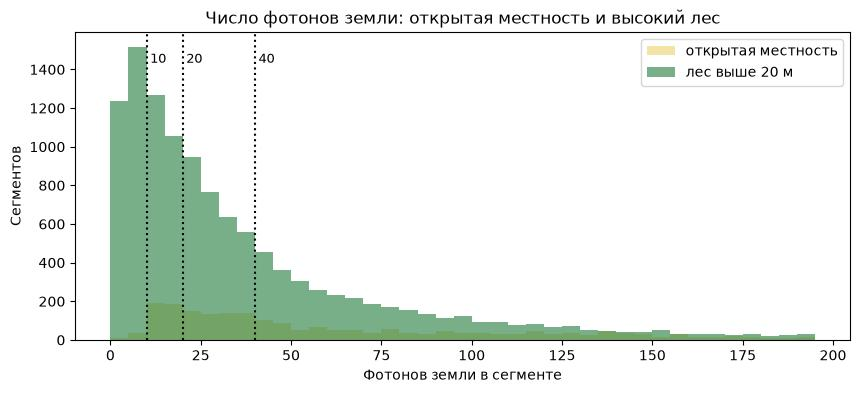

,Порог фотонов земли,Остаётся сегментов,"Доля от исходных, %","Отсеяно под лесом выше 20 м, %","Отсеяно на открытой местности, %"
0,10,26508,85.3,22.7,1.8
1,20,21488,69.2,41.8,15.7
2,40,14324,46.1,65.8,36.7


In [ ]:
q0 = isat[isat.h_ground.notna() & (isat.h_ground != 0)]                  # Сегменты, где найдена земля.
tall = q0.h_canopy.fillna(0) > 20                                        # Под высоким лесом.
open_ = q0.h_canopy.fillna(0) < 2                                        # На открытой местности.
rows = []                                                                # Строки таблицы.
for thr in (10, 20, 40):                                                 # Три порога:
    keep = q0.gnd_ph_count >= thr                                        # Сегменты, прошедшие порог.
    rows.append([thr, int(keep.sum()), 100 * keep.sum() / len(isat), 100 * (1 - keep[tall].mean()), 100 * (1 - keep[open_].mean())])
thr_tbl = pd.DataFrame(rows, columns=["Порог фотонов земли", "Остаётся сегментов", "Доля от исходных, %", "Отсеяно под лесом выше 20 м, %", "Отсеяно на открытой местности, %"]).round(1)
fig, ax = plt.subplots(figsize=(10, 4))                                  # Распределения числа фотонов земли.
bins = np.arange(0, 200, 5)                                              # Интервалы гистограммы.
ax.hist(q0.gnd_ph_count[open_].clip(0, 199), bins=bins, alpha=0.6, label="открытая местность", color="#e8d36b")
ax.hist(q0.gnd_ph_count[tall].clip(0, 199), bins=bins, alpha=0.6, label="лес выше 20 м", color="#1f7a3a")
for thr in (10, 20, 40): ax.axvline(thr, color="k", ls=":"); ax.text(thr + 1, ax.get_ylim()[1] * 0.9, str(thr), fontsize=9)
ax.set_xlabel("Фотонов земли в сегменте"); ax.set_ylabel("Сегментов"); ax.legend(); ax.set_title("Число фотонов земли: открытая местность и высокий лес")
plt.show()                                       # Показываем рисунок.
thr_tbl                                                                  # Показываем таблицу.

Под высоким лесом фотонов земли в разы меньше, и любой порог отсеивает лесные сегменты сильнее открытых. Порог 20 — компромисс: убирает ненадёжные сегменты, но сохраняет под высоким лесом большую часть измерений. Порог 40 отсеял бы под высоким лесом две трети измерений: эталона стало бы меньше всего там, где ошибка модели рельефа наибольшая.

### **5.3. Пересчёт высот и привязка точек к изображению**

Для каждой точки высота геоида $N$ вычитается из эллипсоидальной высоты $h$. Затем в точке нужно узнать высоту модели рельефа. Точка почти никогда не попадает в центр пикселя, поэтому значение находится **билинейной интерполяцией** по четырём соседним пикселям (`map_coordinates` с `order=1`): если точка лежит на долях $u$ и $v$ пикселя от левого верхнего соседа, то

$$z = (1-u)(1-v)\,z_{00} + u(1-v)\,z_{01} + (1-u)v\,z_{10} + uv\,z_{11}.$$

Систему высот удобнее всего проверять на открытой местности, где модель рельефа почти не завышена: туда отнесены точки, где высота растительности по ICESat-2 меньше 2 м.

In [ ]:
q = isat_q.copy()                                                        # Сегменты после фильтров качества.
q["h_egm08"] = ellipsoid_to_geoid(q.h_ground.values, q.lon.values, q.lat.values, "EGM2008")   # Высота над геоидом EGM2008.
q["h_egm96"] = ellipsoid_to_geoid(q.h_ground.values, q.lon.values, q.lat.values, "EGM96")     # То же над EGM96.
row, col = lonlat_to_rowcol(q.lon.values, q.lat.values, GRID)            # Положение точек на сетке участка.
inside = (row > 1) & (row < GRID["H"] - 2) & (col > 1) & (col < GRID["W"] - 2)   # Отбрасываем точки у самого края сетки.
q, row, col = q[inside].copy(), row[inside], col[inside]                 # Оставляем точки внутри.
q["row"], q["col"] = row, col                                            # Запоминаем положение на сетке.
q["cop"] = map_coordinates(stack["cop"], [row, col], order=1)            # Высота Copernicus в точке (билинейная интерполяция).
open_mask = q.h_canopy.fillna(0) < 2                                     # Открытая местность: растительность ниже 2 м.
datum_check = pd.DataFrame([                                             # Медианная разность без пересчёта и с ним.
    ["без пересчёта (эллипсоид)", np.median(q.cop - q.h_ground), np.median((q.cop - q.h_ground)[open_mask])],
    ["с пересчётом в EGM2008", np.median(q.cop - q.h_egm08), np.median((q.cop - q.h_egm08)[open_mask])],
], columns=["Высоты ICESat-2", "Медиана (Copernicus − ICESat-2), м", "То же на открытой местности, м"]).round(2)
datum_check                                                              # Показываем таблицу.

,Высоты ICESat-2,"Медиана (Copernicus − ICESat-2), м","То же на открытой местности, м"
0,без пересчёта (эллипсоид),42.68,39.64
1,с пересчётом в EGM2008,3.38,0.30


Без пересчёта медианная разность — десятки метров (это высота геоида), после пересчёта на открытой местности она близка к нулю: системы высот согласованы. Оставшаяся разность по всем точкам — это уже завышение модели рельефа в лесу. Проверим это по классам покрова.

In [ ]:
ri, ci = np.round(q.row).astype(int).values, np.round(q.col).astype(int).values   # Ячейка сетки для каждой точки.
q["wc"] = stack["wc"][ri, ci].astype(int)                                # Класс WorldCover в точке.
q["lossyear"] = stack["lossyear"][ri, ci]                                # Год потери леса (0 – потери не было).
q["dh"] = q.cop - q.h_egm08                                              # Завышение модели рельефа после пересчёта, м.
q["cls_wc"] = q.wc.map(WC_TO_CLASS).fillna(0).astype(int)                # Класс покрова работы по WorldCover.
rows = []                                                                # Строки таблицы.
for c in sorted(set(q.cls_wc) - {0}):                                    # Для каждого класса:
    m_ = (q.cls_wc == c).values
    if m_.sum() >= 50:
        rows.append([CLASS_NAMES[c], int(m_.sum()), np.median((q.cop - q.h_ground)[m_]), np.median(q.dh[m_])])
by_class = pd.DataFrame(rows, columns=["Класс покрова", "Сегментов", "Медиана Copernicus − ICESat-2 без пересчёта, м", "После пересчёта в EGM2008, м"]).round(2)
by_class                                                                 # Показываем таблицу.

,Класс покрова,Сегментов,"Медиана Copernicus − ICESat-2 без пересчёта, м","После пересчёта в EGM2008, м"
0,Лес,11832,49.650002,10.79
1,Луга и пашня,2040,39.919998,0.58
2,Застройка,6034,41.480000,2.17
3,Открытый грунт,144,42.439999,3.43
4,Вода,1408,39.000000,-0.38


Без пересчёта сдвиг одинаков для всех классов — это признак системной ошибки. После пересчёта классы расходятся: в лесу модель завышена на метры и десятки метров, в застройке — на пару метров, на лугах — почти не завышена. Именно эту зависимость от покрова и будет исправлять модель машинного обучения.

### **5.4. Очистка измерений**

Правило очистки должно опираться на качество эталона и физическую правдоподобность, а не на согласие с проверяемой моделью рельефа: если отбрасывать точки, расходящиеся с моделью, её точность окажется искусственно высокой. Каждое правило сначала проверяется на данных.

**Снег.** ICESat-2 отмечает сегменты, измеренные по снежному покрову (флаг `snowcover` > 1). Сравним завышение модели для зимних и летних измерений.

In [ ]:
q["snow"] = np.where(q.snowcover > 1, "со снегом", "без снега")       # Сезон измерения.
q["surface"] = np.where(q.wc == 10, "лес", "открытая местность и застройка")   # Тип поверхности по WorldCover.
snow_tbl = q.groupby(["surface", "snow"]).agg(Сегментов=("dh", "size"), Медиана_dh=("dh", "median"), NMAD=("dh", lambda e: 1.4826 * np.median(np.abs(e - np.median(e))))).round(2)
snow_tbl.columns = ["Сегментов", "Медиана Copernicus − ICESat-2, м", "Разброс NMAD, м"]
snow_tbl                                                                 # Показываем таблицу.

Сегментов  \
surface                        snow                   
лес                            без снега       6399   
                               со снегом       5433   
открытая местность и застройка без снега       6153   
                               со снегом       3475   

                                          Медиана Copernicus − ICESat-2, м  \
surface                        snow                                          
лес                            без снега                              9.58   
                               со снегом                             11.80   
открытая местность и застройка без снега                              1.56   
                               со снегом                              1.12   

                                          Разброс NMAD, м  
surface                        snow                        
лес                            без снега             9.25  
                               со снегом             8.29  
открытая местность и застройка без снега             1.95  
                               со снегом             1.41

Зимой и летом в одном и том же классе покрова завышение разное: на открытой местности снег поднимает отражающую поверхность, в лесу меняется доля фотонов, прошедших до земли. Если смешать сезоны, модель будет учиться на двух разных зависимостях, поэтому зимние измерения исключаются.

*NMAD* — нормированное медианное абсолютное отклонение: медиана модуля отклонений от медианы, умноженная на 1,4826. Для нормального распределения оно равно стандартному отклонению, но не чувствительно к единичным выбросам.

**Вода.** Уровень воды меняется от даты к дате, а в моделях рельефа водная поверхность искусственно выровнена. Такие сегменты определяются по классу воды WorldCover и ATL08.

In [ ]:
water = q.wc.isin([80]) | q.landcover.isin([80, 200])                    # Сегменты на воде.
water_tbl = pd.DataFrame([["вода", int(water.sum()), np.median(q.dh[water]), 1.4826 * np.median(np.abs(q.dh[water] - np.median(q.dh[water])))],
                          ["суша", int((~water).sum()), np.median(q.dh[~water]), 1.4826 * np.median(np.abs(q.dh[~water] - np.median(q.dh[~water])))]],
                         columns=["Поверхность", "Сегментов", "Медиана Copernicus − ICESat-2, м", "Разброс NMAD, м"]).round(2)
water_tbl                                                                # Показываем таблицу.

,Поверхность,Сегментов,"Медиана Copernicus − ICESat-2, м","Разброс NMAD, м"
0,вода,1561,-0.30,0.95
1,суша,19899,3.86,4.86


**Изменение поверхности.** Copernicus построен по съёмке 2011–2015 гг., лазерные измерения — с 2018 г. Там, где лес за это время исчез, поверхность понизилась на высоту деревьев, и разность отражает изменение, а не ошибку модели.

In [ ]:
lost = (q.lossyear >= 11) & (q.wc == 10)                                 # Лес, потерянный после 2010 г. (по WorldCover 2021 всё ещё лес или уже нет – неважно: карта Hansen точнее по датам).
intact = (q.lossyear == 0) & (q.wc == 10)                                # Сохранившийся лес.
lost_any = q.lossyear >= 11                                              # Любая ячейка с потерей леса после 2010 г.
loss_tbl = pd.DataFrame([["лес без изменений", int(intact.sum()), np.median(q.dh[intact])],
                         ["потеря леса после 2010 г.", int(lost_any.sum()), np.median(q.dh[lost_any]) if lost_any.any() else np.nan]],
                        columns=["Поверхность", "Сегментов", "Медиана Copernicus − ICESat-2, м"]).round(2)
loss_tbl                                                                 # Показываем таблицу.

,Поверхность,Сегментов,"Медиана Copernicus − ICESat-2, м"
0,лес без изменений,11755,10.8
1,потеря леса после 2010 г.,74,5.9


**Грубые выбросы.** Разность больше 50 м физически неправдоподобна: деревья на участке ниже, а такие значения дают ошибочные отражения от облаков. Посмотрим, что исключили бы пороги 50, 20 и 10 м.

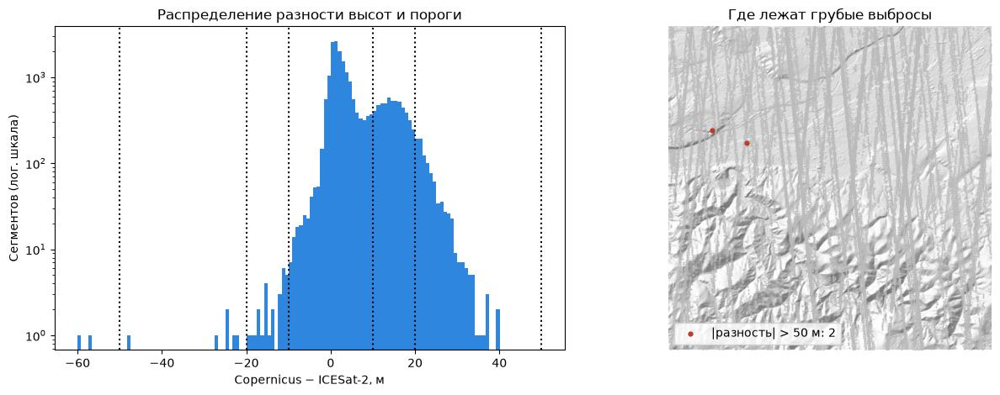

,"Порог |Copernicus − ICESat-2|, м",Исключено сегментов,"Доля исключённых под лесом выше 20 м, %","Доля исключённых на открытой местности, %"
0,50,2,0.0,0.0
1,20,956,12.0,0.0
2,10,6433,70.6,2.4


In [ ]:
tall = q.h_canopy.fillna(0) > 20                                         # Под высоким лесом.
open_ = q.h_canopy.fillna(0) < 2                                         # Открытая местность.
rows = []                                                                # Строки таблицы.
for thr in (50, 20, 10):                                                 # Три порога:
    out = q.dh.abs() > thr                                               # Сегменты, которые порог исключил бы.
    rows.append([thr, int(out.sum()), 100 * out[tall].mean(), 100 * out[open_].mean()])
outlier_tbl = pd.DataFrame(rows, columns=["Порог |Copernicus − ICESat-2|, м", "Исключено сегментов", "Доля исключённых под лесом выше 20 м, %", "Доля исключённых на открытой местности, %"]).round(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})   # Гистограмма и карта.
ax[0].hist(q.dh.clip(-60, 60), bins=120, color="#2e86de"); ax[0].set_yscale("log"); ax[0].set_xlabel("Copernicus − ICESat-2, м"); ax[0].set_ylabel("Сегментов (лог. шкала)")
for thr in (10, 20, 50): ax[0].axvline(thr, color="k", ls=":"); ax[0].axvline(-thr, color="k", ls=":")
ax[0].set_title("Распределение разности высот и пороги")
ax[1].imshow(ls.hillshade(dem, vert_exag=3, dx=30, dy=30), cmap="gray", alpha=0.6)   # Подложка – отмывка рельефа.
big = q.dh.abs() > 50                                                    # Грубые выбросы.
ax[1].scatter(q.col[~big], q.row[~big], s=0.3, c="#bbbbbb"); ax[1].scatter(q.col[big], q.row[big], s=12, c="#c0392b", label=f"|разность| > 50 м: {int(big.sum())}")
ax[1].legend(loc="lower left"); ax[1].axis("off"); ax[1].set_title("Где лежат грубые выбросы")
plt.tight_layout(); plt.show()                         # Показываем рисунок.
outlier_tbl                                                              # Показываем таблицу.

При пороге 50 м исключаются единицы сегментов — это и есть грубые выбросы. При 20 м и тем более 10 м под высоким лесом исключалась бы большая доля измерений, то есть именно та ошибка модели, которую нужно исправить. Гистограмма двугорбая: один горб около нуля — открытая местность, второй — лес, где модель завышена на метры и десятки метров.

Все правила применяются по порядку и записываются в журнал очистки: что исключено, по какому правилу, сколько и почему.

In [ ]:
ri, ci = np.round(q.row).astype(int).values, np.round(q.col).astype(int).values   # Ячейка сетки для каждой точки.
q["wc"] = stack["wc"][ri, ci].astype(int)                                # Класс WorldCover в точке.
q["lossyear"] = stack["lossyear"][ri, ci]                                # Год потери леса (0 – потери не было).
q["dh"] = q.cop - q.h_egm08                                              # Завышение модели рельефа, м.
MAX_DH = 50                                                              # Порог грубых выбросов, м.
log = []                                                                 # Журнал очистки.

def drop(data, mask, what, rule, why):
    """Исключает строки по маске и записывает шаг в журнал очистки."""
    log.append([what, rule, int(mask.sum()), why])                       # Что исключено, правило, сколько, почему.
    return data[~mask]                                                   # Оставляем только пригодные измерения.

q = drop(q, q.snowcover > 1, "Измерения со снегом", "флаг снега ICESat-2 > 1", "снег поднимает поверхность, сезон не совпадает с моделью рельефа")
q = drop(q, q.wc.isin([80]) | q.landcover.isin([80, 200]), "Водные объекты", "класс воды WorldCover или ATL08", "уровень воды меняется, в моделях рельефа водная поверхность выровнена")
q = drop(q, q.lossyear >= 11, "Вырубки и гари после 2010 г.", "год потери леса Hansen ≥ 2011", "поверхность изменилась после съёмки модели рельефа")
q = drop(q, q.dh.abs() > MAX_DH, "Грубые выбросы", f"|Copernicus − ICESat-2| > {MAX_DH} м", "ошибочные отражения (облака, шум); физически неправдоподобно")
clean_log = pd.DataFrame(log, columns=["Что исключено", "Правило", "Затронуто сегментов", "Обоснование"])  # Журнал как таблица.
print(f"После очистки осталось {len(q)} сегментов (условие пригодности ≥ 3000: {'выполнено' if len(q) >= 3000 else 'НЕ выполнено'})")
clean_log                                                                # Показываем таблицу.

После очистки осталось 11516 сегментов (условие пригодности ≥ 3000: выполнено)


,Что исключено,Правило,Затронуто сегментов,Обоснование
0,Измерения со снегом,флаг снега ICESat-2 > 1,8908,"снег поднимает поверхность, сезон не совпадает..."
1,Водные объекты,класс воды WorldCover или ATL08,989,"уровень воды меняется, в моделях рельефа водна..."
2,Вырубки и гари после 2010 г.,год потери леса Hansen ≥ 2011,45,поверхность изменилась после съёмки модели рел...
3,Грубые выбросы,|Copernicus − ICESat-2| > 50 м,2,"ошибочные отражения (облака, шум); физически н..."


После очистки остаётся около половины измерений, и почти всё сокращение — зимние. Посмотрим на очищенные измерения на интерактивной карте с подложкой Esri: при наведении на точку видна её высота.

In [ ]:
center = [(ROI_BOUNDS[1] + ROI_BOUNDS[3]) / 2, (ROI_BOUNDS[0] + ROI_BOUNDS[2]) / 2]   # Центр участка.
fmap = folium.Map(location=center, zoom_start=11, tiles="Esri.WorldImagery")   # Карта с подложкой из космических снимков.
folium.Rectangle([[ROI_BOUNDS[1], ROI_BOUNDS[0]], [ROI_BOUNDS[3], ROI_BOUNDS[2]]],  # Прямоугольник границ:
                 color="yellow", weight=2, fill=False, tooltip=TERRITORY).add_to(fmap)   # Границы участка.
sample_pts = q.sample(min(3000, len(q)), random_state=SEED)              # Случайная выборка очищенных сегментов для показа.
features = []                                                            # Точки GeoJSON.
for lon, lat, h in zip(sample_pts.lon, sample_pts.lat, sample_pts.h_egm08):   # Для каждого сегмента выборки:
    features.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(lon, 5), round(lat, 5)]},
                     "properties": {"h": round(h, 1)}})                  # Точка GeoJSON с высотой для подписи.
points = {"type": "FeatureCollection", "features": features}             # Набор точек GeoJSON.
folium.GeoJson(points, name="ICESat-2", marker=folium.CircleMarker(radius=2, color="#ff8c00", fill=True, fill_opacity=0.8),
               tooltip=folium.GeoJsonTooltip(["h"], aliases=["Высота над геоидом EGM2008, м"])).add_to(fmap)
fmap                                                                     # Показываем карту.

### **Выводы по разделу 5:**

1. **Высота земли сегмента** — медиана фотонов земли; под лесом их меньше, поэтому порог числа фотонов — компромисс между надёжностью и полнотой эталона
2. **Пересчёт систем высот** обязателен: без него лазерные высоты сдвинуты на десятки метров
3. **Билинейная интерполяция** «снимает» значения изображений в точках измерений
4. **Правила очистки** опираются на качество эталона, а не на согласие с проверяемой моделью: снег, вода, изменения поверхности и грубые выбросы исключаются с обоснованием

---

## **Раздел 6. Классификация пикселей изображения**

Модель уточнения высот должна знать, чем занят каждый пиксель: в лесу модель рельефа завышена на метры, на лугу — почти нет. Карту покрова можно взять готовой (WorldCover), но построим собственную: по снимку и признакам рельефа, как в [лекции по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), только локально и с честной проверкой точности.

### **6.1. Метки покрова и баланс классов**

Обучающие метки берутся из WorldCover, классы которой сведены к семи, важным для высот: деревья → лес; кустарник; травы и пашня → луга и пашня; застройка; открытый грунт; вода; травяные болота, мхи и лишайники → болота и мхи. WorldCover сама получена моделью, поэтому точность оценивается относительно неё, а не относительно наземной съёмки.

In [ ]:
label_map = np.zeros(stack["wc"].shape, int)                             # Метки покрова; 0 – класс не используется.
for wc_code, our_class in WC_TO_CLASS.items():                           # Для каждого кода WorldCover:
    label_map[stack["wc"] == wc_code] = our_class                        # Переводим коды WorldCover в классы работы.
counts = pd.Series(label_map.ravel()).value_counts()                     # Число ячеек каждого класса.
classes_used = [c for c in CLASS_NAMES if counts.get(c, 0) >= 200]       # Классы, которых на участке достаточно.
balance = pd.DataFrame({"Класс": [CLASS_NAMES[c] for c in classes_used], "Ячеек": [int(counts[c]) for c in classes_used]})  # Число ячеек по классам.
balance["Доля, %"] = (100 * balance["Ячеек"] / balance["Ячеек"].sum()).round(1)  # Доля класса на участке.
balance                                                                  # Показываем таблицу.

,Класс,Ячеек,"Доля, %"
0,Лес,289901,64.9
1,Луга и пашня,35111,7.9
2,Застройка,101055,22.6
3,Открытый грунт,1929,0.4
4,Вода,18874,4.2


Классы распределены неравномерно: лес занимает больше половины участка, открытый грунт — доли процента. Если обучать классификатор на всех пикселях, он выучит преобладающий класс и почти не ошибётся в общей точности, пропуская редкие. Поэтому из каждого класса берётся не более 4000 пикселей, а качество оценивается и средним F1 по классам. Классы, у которых меньше 200 пикселей, в обучение не включаются.

### **6.2. Соседние пиксели почти одинаковы: случайная проверка против блочной**

Соседние пиксели размером 30 м почти не отличаются друг от друга. При случайном разделении на обучающую и проверочную части у каждого проверочного пикселя в обучении есть соседи в 30 м от него, и модель «узнаёт» знакомое место, а не применяет выученное правило ([практическая работа №5](https://colab.research.google.com/drive/1mwCV-82k9R5ZtR0NGVJT3oLNyKDG0ZXO), раздел 4.2). Поэтому участок делится на квадратные блоки, и каждый блок целиком попадает в одну из пяти частей проверки (`GroupKFold`). Для пикселей снимка берутся блоки 2 км, для точек вдоль лазерного трека, расположенных через 100 м, — 5 км.

Проверим это прямо: один и тот же классификатор и одна и та же модель высот оцениваются при случайном разбиении на пять частей и при разбиении по блокам.

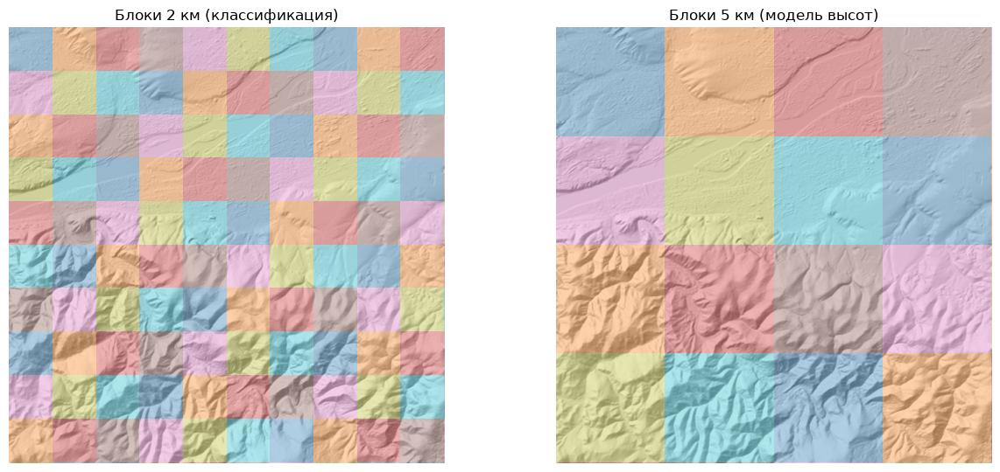

,Показатель,Случайное разбиение,По пространственным блокам
0,Классификация покрова: общая точность,0.872,0.851
1,Классификация покрова: средний F1,0.859,0.827
2,"Модель высот: RMSE, м",3.326,3.558


In [ ]:
S2B = ["B2", "B3", "B4", "B8", "B11", "B12", "NDVI", "NDWI", "NDBI"]    # Спектральные признаки.
RELB = ["slope", "tpi7", "tpi31", "rough7"]                              # Признаки рельефа (кроме высоты).
F_s2 = np.stack([stack[b] for b in S2B], -1).reshape(-1, len(S2B))       # Таблица «ячейка × спектральный признак».
F_rel = np.column_stack([dem.ravel()] + [REL[k].ravel() for k in RELB])  # Таблица «ячейка × признак рельефа».
X_b = np.hstack([F_s2, F_rel])                                           # Все признаки.
y_all = label_map.ravel()                                                # Метка каждой ячейки.
rr, cc = np.indices(dem.shape)                                           # Строка и столбец каждой ячейки.
blk2 = block_id(rr.ravel(), cc.ravel(), GRID, 2000)                      # Номер блока 2 км для каждой ячейки.
rng = np.random.default_rng(SEED)                                        # Генератор случайных чисел с зерном.
idx = np.concatenate([rng.choice(np.where(y_all == c)[0], min(int(counts[c]), 4000), replace=False) for c in classes_used])   # До 4000 ячеек на класс.
def rf():
    """Новый классификатор Random Forest."""
    return RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED)
def cv_accuracy(splits):
    """Общая точность и средний F1 по прогнозам вне обучения для заданного разбиения."""
    pred = np.zeros(len(idx), int)
    for tr, te in splits:                                                # Для каждой части:
        pred[te] = rf().fit(X_b[idx][tr], y_all[idx][tr]).predict(X_b[idx][te])   # обучаем на остальных, предсказываем её.
    return accuracy_score(y_all[idx], pred), f1_score(y_all[idx], pred, average="macro")
acc_rand = cv_accuracy(KFold(5, shuffle=True, random_state=SEED).split(X_b[idx]))          # Случайное разбиение.
acc_blk = cv_accuracy(GroupKFold(5).split(X_b[idx], y_all[idx], blk2[idx]))                # Разбиение по блокам 2 км.
FEAT = {"wcl": label_map, **REL, **{b: stack[b] for b in ["B4", "B8", "B11", "NDVI", "NDWI"]}, "eth": stack["eth"]}   # Признаки модели высот.
ri, ci = np.round(q.row).astype(int).values, np.round(q.col).astype(int).values   # Ячейка сетки для каждой точки.
for k, a in FEAT.items():                                                # Значение каждого признака в точке.
    q[k] = a[ri, ci]
qh = q[q.wcl != 6].copy()                                                # Воду модель высот не уточняет.
F_H = ["wcl", "slope", "tpi7", "tpi31", "rough7", "B4", "B8", "B11", "NDVI", "NDWI", "eth"]   # Признаки модели высот.
yh = qh.dh.values; blk5 = block_id(qh.row.values, qh.col.values, GRID, 5000)   # Целевая переменная и блоки 5 км.
def hgb():
    """Новая модель градиентного бустинга для уточнения высот."""
    return HistGradientBoostingRegressor(loss="absolute_error", max_iter=400, learning_rate=0.05, categorical_features=[0], random_state=SEED)
def cv_rmse(splits):
    """RMSE по прогнозам вне обучения для заданного разбиения."""
    pred = np.zeros(len(qh))
    for tr, te in splits:
        pred[te] = hgb().fit(qh[F_H].iloc[tr], yh[tr]).predict(qh[F_H].iloc[te])
    return height_metrics(yh - pred)["RMSE"]
rmse_rand = cv_rmse(KFold(5, shuffle=True, random_state=SEED).split(qh))                   # Случайное разбиение.
rmse_blk = cv_rmse(GroupKFold(5).split(qh, yh, blk5))                                      # Разбиение по блокам 5 км.
leak = pd.DataFrame([["Классификация покрова: общая точность", acc_rand[0], acc_blk[0]], ["Классификация покрова: средний F1", acc_rand[1], acc_blk[1]],
                     ["Модель высот: RMSE, м", rmse_rand, rmse_blk]], columns=["Показатель", "Случайное разбиение", "По пространственным блокам"]).round(3)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))                          # Карты блоков.
for a, size, t in [(ax[0], 2000, "Блоки 2 км (классификация)"), (ax[1], 5000, "Блоки 5 км (модель высот)")]:
    a.imshow(ls.hillshade(dem, vert_exag=3, dx=30, dy=30), cmap="gray", alpha=0.6)
    a.imshow(block_id(rr, cc, GRID, size) % 7, cmap="tab10", alpha=0.35, interpolation="nearest"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()                           # Показываем рисунок.
leak                                                                     # Показываем таблицу.

При случайном разбиении оценки выглядят лучше: точность классификатора выше, ошибка высот меньше. Но это не точность на новых местах, а умение узнавать соседние пиксели. Оценка по блокам ниже и честнее: она показывает, чего ждать между лазерными треками, где модель и применяется. Все дальнейшие оценки выполняются по блокам.

### **6.3. Снимок против снимка с рельефом**

Классификатор Random Forest (случайный лес) строит сотни деревьев решений на случайных подвыборках пикселей и признаков и выбирает класс голосованием. Параметры: 300 деревьев, в каждом листе не менее 2 пикселей. Сравним классификацию только по снимку (6 каналов и 3 индекса) и по снимку с признаками рельефа (высота, уклон, два TPI, шероховатость).

Для каждой части проверки модель обучается на остальных четырёх и предсказывает её классы — так для всех пикселей выборки получается *прогноз вне обучения*. Качество оценивается тремя показателями: общая точность — доля верно классифицированных пикселей; каппа Коэна — с поправкой на случайные совпадения; средний F1 — усреднённое по классам качество, которое не даёт крупному классу скрыть ошибки в мелких.

In [ ]:
S2B = ["B2", "B3", "B4", "B8", "B11", "B12", "NDVI", "NDWI", "NDBI"]    # Спектральные признаки.
RELB = ["slope", "tpi7", "tpi31", "rough7"]                              # Признаки рельефа (кроме высоты).
F_s2 = np.stack([stack[b] for b in S2B], -1).reshape(-1, len(S2B))       # Таблица «ячейка × спектральный признак».
F_rel = np.column_stack([dem.ravel()] + [REL[k].ravel() for k in RELB])  # Таблица «ячейка × признак рельефа».
y_all = label_map.ravel()                                                # Метка каждой ячейки.
rr, cc = np.indices(dem.shape)                                           # Строка и столбец каждой ячейки.
blk2 = block_id(rr.ravel(), cc.ravel(), GRID, 2000)                      # Номер блока 2 км для каждой ячейки.
rng = np.random.default_rng(SEED)                                        # Генератор случайных чисел с зерном.
parts = []                                                               # Номера ячеек, выбранных по классам.
for c in classes_used:                                                   # Для каждого класса:
    cells_c = np.where(y_all == c)[0]                                    # Все ячейки класса c.
    n_take = min(len(cells_c), 4000)                                     # Не более 4000 ячеек на класс.
    parts.append(rng.choice(cells_c, n_take, replace=False))             # Случайная выборка без повторов.
idx = np.concatenate(parts)                                              # Номера ячеек обучающей выборки.

def cv_classify(X, model_fn):
    """Предсказания вне обучения по пространственным блокам."""
    pred = np.zeros(len(idx), int)
    for tr, te in GroupKFold(5).split(X[idx], y_all[idx], blk2[idx]):    # Пять частей, блоки не разрываются.
        model = model_fn().fit(X[idx][tr], y_all[idx][tr])               # Обучаем на четырёх частях,
        pred[te] = model.predict(X[idx][te])                             # предсказываем пятую.
    return pred

def rf():
    """Новый классификатор Random Forest."""
    return RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED)   # 300 деревьев, в листе ≥ 2 ячеек.

X_a = F_s2                                                               # Признаки: только снимок.
X_b = np.hstack([F_s2, F_rel])                                           # Признаки: снимок + рельеф.
pred_a, pred_b = cv_classify(X_a, rf), cv_classify(X_b, rf)              # Прогнозы вне обучения для обоих наборов.
rows = []                                                                # Строки будущей таблицы.
for name, p_ in [("только снимок", pred_a), ("снимок + рельеф", pred_b)]:  # Для каждого набора признаков:
    rows.append([name, accuracy_score(y_all[idx], p_), cohen_kappa_score(y_all[idx], p_), f1_score(y_all[idx], p_, average="macro")])  # Три показателя качества.
q1 = pd.DataFrame(rows, columns=["Признаки", "Общая точность", "Каппа Коэна", "Средний F1 по классам"]).round(3)  # Таблица сравнения наборов признаков.
q1                                                                       # Показываем таблицу.

,Признаки,Общая точность,Каппа Коэна,Средний F1 по классам
0,только снимок,0.834,0.788,0.811
1,снимок + рельеф,0.851,0.811,0.827


Признаки рельефа повышают все три показателя. Прирост получен на блоках, не участвовавших в обучении, то есть он не связан с переобучением: по высоте и положению на склоне лес на возвышенности отличается от застройки в долине.

### **6.4. Показатели по классам и матрица ошибок**

Для каждого класса приводятся две величины, принятые при оценке тематических карт:
* **точность производителя** (в scikit-learn — `recall`) — доля пикселей класса по эталону, которые модель распознала верно; её дополнение до единицы — ошибка пропуска;
* **точность пользователя** (`precision`) — доля пикселей, отнесённых моделью к классу, которые действительно ему принадлежат; её дополнение — ошибка включения.

Первая показывает, насколько полно выделен класс, вторая — насколько можно доверять классу, показанному на карте. Матрица ошибок нормирована по строкам: на диагонали — точность производителя.

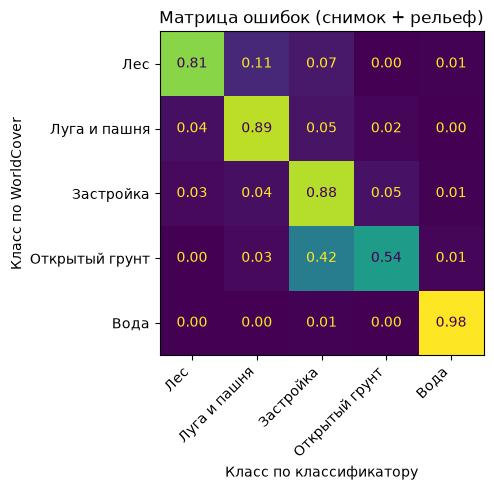

,Класс,"F1, только снимок","F1, снимок + рельеф",Точность производителя,Точность пользователя
0,Лес,0.84,0.86,0.81,0.92
1,Луга и пашня,0.85,0.86,0.89,0.84
2,Застройка,0.78,0.79,0.88,0.73
3,Открытый грунт,0.63,0.64,0.54,0.78
4,Вода,0.96,0.98,0.98,0.98


In [ ]:
labels_present = sorted(set(y_all[idx]))                                 # Классы, представленные в выборке.
f1_cls = pd.DataFrame({"Класс": [CLASS_NAMES[c] for c in labels_present],  # Показатели по каждому классу:
                       "F1, только снимок": f1_score(y_all[idx], pred_a, average=None, labels=labels_present).round(2),
                       "F1, снимок + рельеф": f1_score(y_all[idx], pred_b, average=None, labels=labels_present).round(2),
                       "Точность производителя": recall_score(y_all[idx], pred_b, average=None, labels=labels_present).round(2),
                       "Точность пользователя": precision_score(y_all[idx], pred_b, average=None, labels=labels_present).round(2)})
cm = confusion_matrix(y_all[idx], pred_b, labels=labels_present, normalize="true")   # Доли по строкам (по эталону).
fig, ax = plt.subplots(figsize=(6, 5))                                   # Один рисунок.
ConfusionMatrixDisplay(cm, display_labels=[CLASS_NAMES[c] for c in labels_present]).plot(ax=ax, values_format=".2f", colorbar=False)  # Рисунок матрицы.
plt.xticks(rotation=45, ha="right"); ax.set_xlabel("Класс по классификатору"); ax.set_ylabel("Класс по WorldCover"); plt.title("Матрица ошибок (снимок + рельеф)"); plt.tight_layout(); plt.show()                                           # Подписи и показ рисунка.
f1_cls                                                                   # Показываем таблицу.

Вода распознаётся почти безошибочно, луга и застройка — с точностью около 0,9, лес — около 0,8: часть лесных пикселей отнесена к лугам (редколесье, вырубки, опушки). Хуже всего выделяется открытый грунт: по спектру он похож на застройку.

### **6.5. Важность признаков, карта покрова и её ошибки**

Важность перестановкой измеряет, насколько падает точность, если значения одного признака случайно перемешать: признак, без которого модель не обходится, даёт большое падение. Измерение выполняется на проверочных блоках, поэтому показывает реальную пользу признака.

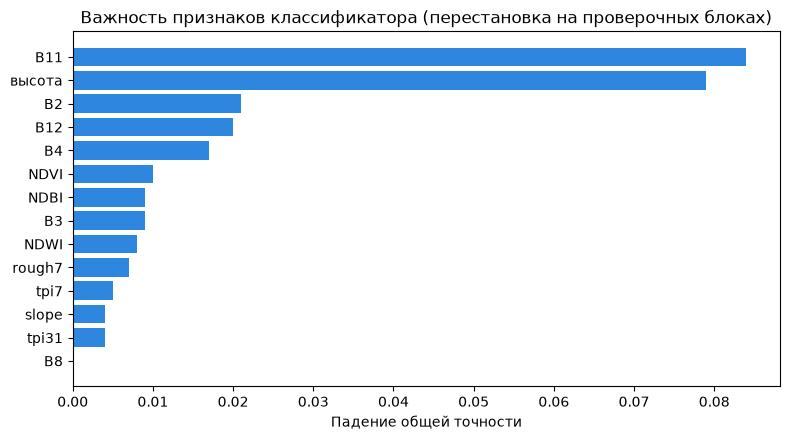

,Признак,Падение точности при перемешивании
4,B11,0.084
9,высота,0.079
0,B2,0.021
5,B12,0.020
2,B4,0.017
6,NDVI,0.010
8,NDBI,0.009
1,B3,0.009


In [ ]:
tr_blocks, te_blocks = next(GroupKFold(5).split(X_b[idx], y_all[idx], blk2[idx]))   # Одна пара «обучение – проверка» по блокам.
clf_imp = rf().fit(X_b[idx][tr_blocks], y_all[idx][tr_blocks])          # Классификатор на четырёх частях.
imp = permutation_importance(clf_imp, X_b[idx][te_blocks], y_all[idx][te_blocks], n_repeats=5, random_state=SEED, n_jobs=N_JOBS)   # Важность на пятой.
feat_names = S2B + ["высота"] + RELB                                     # Имена признаков по порядку столбцов X_b.
imp_tbl = pd.DataFrame({"Признак": feat_names, "Падение точности при перемешивании": imp.importances_mean}).sort_values("Падение точности при перемешивании", ascending=False).round(3)
fig, ax = plt.subplots(figsize=(8, 4.5))                                 # Горизонтальные столбцы.
ax.barh(imp_tbl["Признак"][::-1], imp_tbl["Падение точности при перемешивании"][::-1], color="#2e86de"); ax.set_xlabel("Падение общей точности"); ax.set_title("Важность признаков классификатора (перестановка на проверочных блоках)")
plt.tight_layout(); plt.show()              # Показываем рисунок.
imp_tbl.head(8)                                                          # Восемь самых важных признаков.

Впереди коротковолновый инфракрасный канал B11 (разделяет растительность, застройку и открытый грунт) и высота (лес на возвышенностях, застройка в долине). Индексы уступают каналам, из которых рассчитаны: информация в них та же, и лес решений берёт её из каналов напрямую.

Обучаем итоговый классификатор на всей выборке и классифицируем все пиксели изображения. Их сотни тысяч, поэтому прогноз рассчитывается частями по 200 000 пикселей.

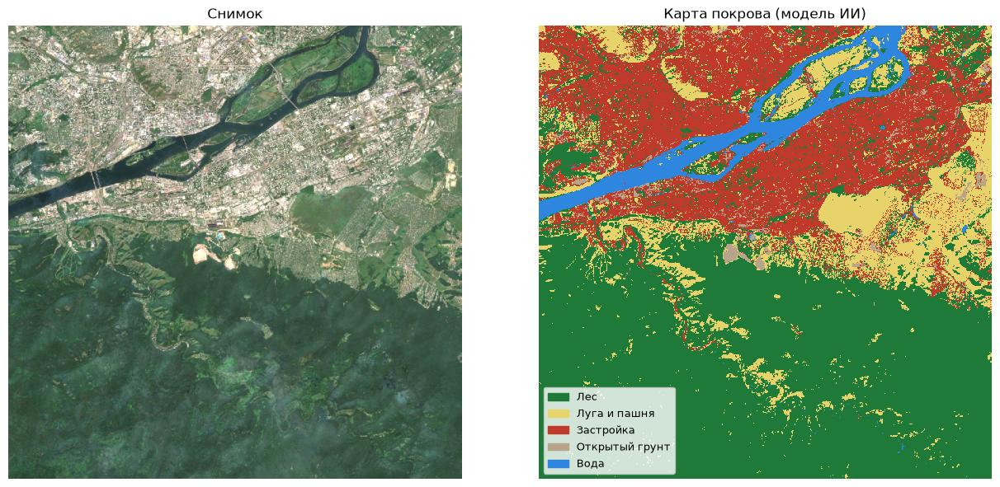

,Класс,"Площадь, км²"
0,Лес,215.2
1,Луга и пашня,62.1
2,Застройка,98.6
3,Открытый грунт,7.5
4,Вода,18.9


In [ ]:
clf = rf().fit(X_b[idx], y_all[idx])                                    # Итоговый классификатор: снимок + рельеф.
pieces = []                                                              # Прогнозы по частям.
for i in range(0, len(X_b), 200000):                                     # Части по 200 000 ячеек.
    pieces.append(clf.predict(X_b[i:i + 200000]))                        # Прогноз для очередных 200 000 ячеек.
cls = np.concatenate(pieces).reshape(dem.shape)                          # Карта покрова на сетке участка.
cmap_cls = ListedColormap([CLASS_COLORS[i] for i in range(1, 8)])        # Палитра из цветов классов 1–7.
norm_cls = BoundaryNorm(np.arange(0.5, 8.5), 7)                          # Каждому номеру класса – свой цвет.
fig, ax = plt.subplots(1, 2, figsize=(13, 6))                            # Два рисунка рядом.
ax[0].imshow(rgb); ax[0].set_title("Снимок")                             # Слева – снимок.
ax[1].imshow(cls, cmap=cmap_cls, norm=norm_cls, interpolation="nearest"); ax[1].set_title("Карта покрова (модель ИИ)")  # Справа – карта покрова.
legend = [Patch(color=CLASS_COLORS[c], label=CLASS_NAMES[c]) for c in classes_used]   # Элементы легенды.
ax[1].legend(handles=legend, loc="lower left", fontsize=9)               # Легенда классов.
for a in ax: a.axis("off")                                               # Без осей координат.
plt.tight_layout(); plt.show()                   # Показываем рисунок.
areas = pd.DataFrame({"Класс": [CLASS_NAMES[c] for c in classes_used],   # Площадь каждого класса на карте:
                      "Площадь, км²": [round((cls == c).sum() * 900 / 1e6, 1) for c in classes_used]})   # Ячейка – 900 м².
areas                                                                    # Показываем таблицу.

На границах классов карта мозаична — для пикселей 30 м это нормально. Где классификатор расходится с WorldCover? Сравним карты по пикселям, не попавшим в обучающую выборку.

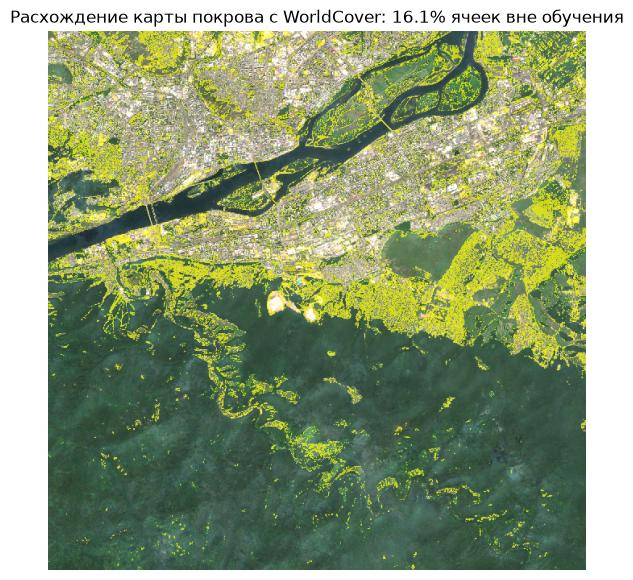

In [ ]:
mask_train = np.zeros(label_map.size, bool); mask_train[idx] = True   # Ячейки обучающей выборки.
err = (cls != label_map) & (label_map > 0) & ~mask_train.reshape(dem.shape)   # Расхождение с WorldCover вне обучения.
fig, ax = plt.subplots(figsize=(8, 7))                                   # Карта расхождений.
ax.imshow(rgb); ax.imshow(np.where(err, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1, alpha=0.7)   # Красным – расхождения.
ax.set_title(f"Расхождение карты покрова с WorldCover: {100 * err.sum() / ((label_map > 0) & ~mask_train.reshape(dem.shape)).sum():.1f}% ячеек вне обучения"); ax.axis("off")
plt.show()                                        # Показываем рисунок.

Расхождения сосредоточены на границах классов и в смешанных участках (окраины застройки, редколесье), а не рассыпаны случайно. Часть из них — ошибки самой WorldCover. Для модели высот это допустимо: ошибка класса в отдельном пикселе меняет поправку только в нём.

### **Выводы по разделу 6:**

1. **Соседние пиксели почти одинаковы**, поэтому случайная проверка завышает точность; честная оценка — по пространственным блокам
2. **Признаки рельефа** повышают точность классификации снимка: высота и положение на склоне разделяют спектрально похожие классы
3. **Точность производителя и пользователя** показывают, какие классы модель пропускает, а какие «перехватывает»
4. **Ошибки карты** сосредоточены на границах и в смешанных пикселях

---

## **Раздел 7. Уточнение модели рельефа регрессией**

### **7.1. Целевая переменная, модель и простые ориентиры**

Целевая переменная — завышение модели рельефа $dh = \text{Copernicus} - \text{ICESat-2}$ в точках лазерных измерений. Модель учится предсказывать его по классу покрова, рельефу и снимку и затем применяется ко всем пикселям: **уточнённая модель рельефа = Copernicus − прогноз завышения**.

Используется градиентный бустинг: деревья строятся последовательно, и каждое следующее исправляет ошибки предыдущих. Параметры: `loss="absolute_error"` — минимизируется средняя абсолютная ошибка, поэтому оставшиеся выбросы влияют меньше; `categorical_features=[0]` — класс покрова — категория, а не число; `max_iter=400`, `learning_rate=0.05` — 400 деревьев с малым шагом дают плавную и устойчивую поправку.

Модель полезна, только если она точнее простых правил. Все правила и модели оцениваются на тех же пяти частях по блокам 5 км:

| Метод | Как рассчитывается поправка |
|---|---|
| Без поправки | поправка равна нулю |
| Общий сдвиг | медиана завышения по обучающим блокам |
| По классам WorldCover / по своей карте покрова | медиана завышения в классе точки |
| Модель ИИ с картой WorldCover | бустинг, вместо своей карты покрова — классы WorldCover |
| Модель ИИ без высоты леса / с высотой леса | бустинг без признака ETH и с ним |

Точность высот оценивается несколькими показателями; $e$ — ошибка в точке после поправки:

| Показатель | Как считается | Смысл |
|---|---|---|
| RMSE | $\sqrt{\overline{e^2}}$ | средняя ошибка; крупные ошибки вносят больший вклад |
| MAE | $\overline{\lvert e \rvert}$ | средняя абсолютная ошибка |
| смещение | медиана $e$ | систематическое завышение (+) или занижение (−) |
| NMAD | $1{,}4826 \cdot \text{медиана}\,\lvert e - \text{медиана}(e) \rvert$ | разброс, устойчивый к выбросам |
| LE90 | 90-й процентиль $\lvert e \rvert$ | ошибка, которую не превышают 90 % точек; так задают точность в спецификациях ЦМР |
| R² | $1 - \sum e^2 / \sum (dh - \overline{dh})^2$ | доля разброса завышения, объяснённая поправкой |

In [ ]:
ri, ci = np.round(q.row).astype(int).values, np.round(q.col).astype(int).values   # Ячейка сетки для каждой точки.
FEAT = {"cls": cls, "wcl": label_map}                                    # Класс покрова: своя карта и WorldCover.
FEAT.update(REL)                                                         # Уклон, TPI, шероховатость.
for b in ["B4", "B8", "B11", "NDVI", "NDWI"]:                            # Для каждого спектрального признака:
    FEAT[b] = stack[b]                                                   # Каналы и индексы Sentinel-2.
FEAT["eth"] = stack["eth"]                                               # Высота леса ETH.
for k, a in FEAT.items():                                                # Для каждого признака:
    q[k] = a[ri, ci]                                                     # Значение признака в ячейке каждой точки.
q = q[q.cls != 6].copy()                                                 # Воду модель высот не уточняет.
y = q.dh.values                                                          # Целевая переменная: завышение, м.
blk5 = block_id(q.row.values, q.col.values, GRID, 5000)                  # Номер блока 5 км для каждой точки.
F_BASE = ["cls", "slope", "tpi7", "tpi31", "rough7", "B4", "B8", "B11", "NDVI", "NDWI"]   # Признаки без высоты леса.
F_ETH = F_BASE + ["eth"]                                                 # Признаки с высотой леса.

def hgb():
    """Новая модель градиентного бустинга для уточнения высот."""
    return HistGradientBoostingRegressor(loss="absolute_error", max_iter=400, learning_rate=0.05,   # 400 деревьев, шаг 0,05.
                                         categorical_features=[0], random_state=SEED)              # Класс покрова – категория.

def cv_correction(df, y, groups, feats):
    """Прогноз завышения вне обучения по пространственным блокам 5 км."""
    pred = np.zeros(len(df))
    for tr, te in GroupKFold(5).split(df, y, groups):
        model = hgb().fit(df[feats].iloc[tr], y[tr])                     # Обучаем на четырёх частях,
        pred[te] = model.predict(df[feats].iloc[te])                     # предсказываем пятую.
    return pred

n = len(q)                                                               # Число точек.
P = {"Без поправки": np.zeros(n), "Общий сдвиг": np.zeros(n), "По классам WorldCover": np.zeros(n), "По своей карте покрова": np.zeros(n)}  # Прогнозы поправки каждого метода.
for tr, te in GroupKFold(5).split(q, y, blk5):                           # Простые правила на тех же частях.
    P["Общий сдвиг"][te] = np.median(y[tr])                              # Медиана завышения по обучающим блокам.
    for key, c in [("По классам WorldCover", "wcl"), ("По своей карте покрова", "cls")]:  # Две карты покрова:
        med = pd.Series(y[tr]).groupby(q[c].values[tr]).median()         # Медиана завышения в каждом классе.
        by_class = pd.Series(q[c].values[te]).map(med)                   # Поправка по классу точки,
        P[key][te] = by_class.fillna(np.median(y[tr])).values            # для класса без обучающих точек – общий сдвиг.
P["Модель ИИ с картой WorldCover"] = cv_correction(q, y, blk5, ["wcl"] + F_ETH[1:])  # Готовая карта WorldCover вместо своей.
P["Модель ИИ без высоты леса"] = cv_correction(q, y, blk5, F_BASE)       # Без признака высоты леса ETH.
P["Модель ИИ с высотой леса"] = cv_correction(q, y, blk5, F_ETH)         # Основная модель.
forest = (q.cls == 1).values                                             # Точки в лесу.

def r_squared(e):
    """Доля разброса завышения, объяснённая поправкой (R²)."""
    return 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)

rows = []                                                                # Строки будущей таблицы.
for method, pred in P.items():                                           # Для каждого метода:
    e = y - pred                                                         # Ошибка, оставшаяся после поправки.
    rows.append({"Метод": method, **height_metrics(e), "R²": r_squared(e), "Смещение в лесу": np.median(e[forest])})  # Метрики метода в одну строку.
res = pd.DataFrame(rows).round(2)                                        # Таблица точности высот.
print(f"Сегментов ICESat-2: {len(q)}, пространственных блоков 5 км: {len(set(blk5))}")
res                                                                      # Показываем таблицу.

Сегментов ICESat-2: 11400, пространственных блоков 5 км: 19


,Метод,RMSE,MAE,смещение,NMAD,LE90,R²,Смещение в лесу
0,Без поправки,9.25,6.61,3.56,4.09,16.77,-0.89,12.49
1,Общий сдвиг,7.51,5.32,-0.27,4.36,13.64,-0.25,9.20
2,По классам WorldCover,6.43,4.69,0.13,4.76,10.34,0.09,4.25
3,По своей карте покрова,5.07,3.45,0.09,2.79,9.17,0.43,0.76
4,Модель ИИ с картой WorldCover,3.57,2.24,-0.02,1.92,5.58,0.72,0.09
5,Модель ИИ без высоты леса,3.72,2.33,-0.06,1.96,5.83,0.69,0.03
6,Модель ИИ с высотой леса,3.56,2.24,-0.04,1.91,5.58,0.72,0.04


Главные строки таблицы — первая и последняя: без поправки и модель с полным набором признаков. Между ними — ориентиры, которые показывают, что даёт каждый шаг: общий сдвиг убирает только среднее, поправка по классам покрова снимает большую часть завышения в лесу, модель машинного обучения добавляет зависимость от рельефа и спектра и уменьшает ошибку ещё сильнее. Смещение в лесу после уточнения — сантиметры.

Точность до и после уточнения по классам покрова:

In [ ]:
e_after = y - P["Модель ИИ с высотой леса"]                               # Ошибка после уточнения.
rows = []                                                                # Строки будущей таблицы.
for c in classes_used:                                                   # Для каждого класса:
    m_ = (q.cls == c).values                                             # Точки класса c.
    if m_.sum() >= 30:                                                   # Класс с малым числом точек не оцениваем.
        rows.append({"Класс": CLASS_NAMES[c], "Сегментов": int(m_.sum()),
                     "RMSE до, м": height_metrics(y[m_])["RMSE"], "RMSE после, м": height_metrics(e_after[m_])["RMSE"],
                     "Смещение до, м": np.median(y[m_]), "Смещение после, м": np.median(e_after[m_])})
per_cls = pd.DataFrame(rows).round(2)                                    # Таблица по классам.
per_cls                                                                  # Показываем таблицу.

,Класс,Сегментов,"RMSE до, м","RMSE после, м","Смещение до, м","Смещение после, м"
0,Лес,4830,13.49,4.35,12.49,0.04
1,Луга и пашня,2043,3.50,2.70,1.00,-0.11
2,Застройка,4202,3.77,2.52,2.39,-0.02
3,Открытый грунт,325,6.17,5.91,1.42,-0.06


### **7.2. Что выучила модель**

Таблицы показывают, что модель работает, но не показывают как. Посмотрим, как предсказанная поправка зависит от высоты леса ETH в разных классах и где остаются ошибки — по уклону и по высоте.

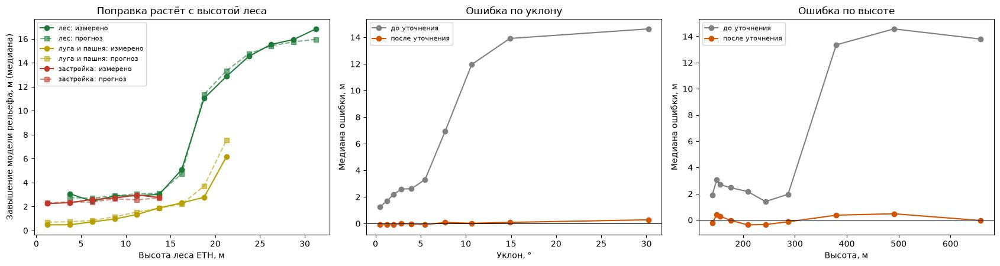

In [ ]:
q["oof"] = P["Модель ИИ с высотой леса"]                                 # Прогноз вне обучения в каждой точке.
e_oof = y - q.oof.values                                                 # Остаток после уточнения.
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))                          # Три диаграммы.
bins_eth = np.arange(0, 35, 2.5)                                         # Интервалы высоты леса.
for c, color, name in [(1, "#1f7a3a", "лес"), (3, "#b8a000", "луга и пашня"), (4, "#c0392b", "застройка")]:   # Три класса.
    m_ = (q.cls == c).values
    if m_.sum() < 100: continue
    g = pd.DataFrame({"eth": q.eth.values[m_], "dh": y[m_], "pred": q.oof.values[m_]}); g["bin"] = pd.cut(g.eth, bins_eth)
    agg = g.groupby("bin", observed=True).agg(dh=("dh", "median"), pred=("pred", "median"), n=("dh", "size")); agg = agg[agg.n >= 30]
    centers = [b.mid for b in agg.index]
    ax[0].plot(centers, agg.dh, "o-", color=color, label=f"{name}: измерено"); ax[0].plot(centers, agg.pred, "s--", color=color, alpha=0.6, label=f"{name}: прогноз")
ax[0].set_xlabel("Высота леса ETH, м"); ax[0].set_ylabel("Завышение модели рельефа, м (медиана)"); ax[0].set_title("Поправка растёт с высотой леса"); ax[0].legend(fontsize=8)
for a, feat, t in [(ax[1], q.slope.values, "Уклон, °"), (ax[2], q.cop.values, "Высота, м")]:   # Остатки по уклону и высоте.
    bins = np.quantile(feat, np.linspace(0, 1, 11)); mids = (bins[:-1] + bins[1:]) / 2
    lab = np.clip(np.digitize(feat, bins[1:-1]), 0, 9)
    a.plot(mids, [np.median(y[lab == b]) for b in range(10)], "o-", color="grey", label="до уточнения")
    a.plot(mids, [np.median(e_oof[lab == b]) for b in range(10)], "o-", color="#d35400", label="после уточнения")
    a.axhline(0, color="k", lw=0.8); a.set_xlabel(t); a.set_ylabel("Медиана ошибки, м"); a.legend(fontsize=8)
ax[1].set_title("Ошибка по уклону"); ax[2].set_title("Ошибка по высоте")
plt.tight_layout(); plt.show()              # Показываем рисунок.

Завышение в лесу зависит от высоты полога нелинейно: при невысоком пологе — 2–3 м, при высоком сомкнутом — до полутора десятков метров: радарный сигнал проникает в редкие кроны, но не в сомкнутый полог. Прогноз повторяет эту зависимость, то есть модель воспроизводит физическую закономерность. Остатки после уточнения близки к нулю во всём диапазоне уклонов и высот.

### **7.3. Сколько измерений нужно: кривая обучения**

Кривая обучения показывает, как ошибка на проверочных блоках зависит от числа обучающих точек: модель обучается на случайных подвыборках разного объёма, проверка — на тех же отложенных блоках.

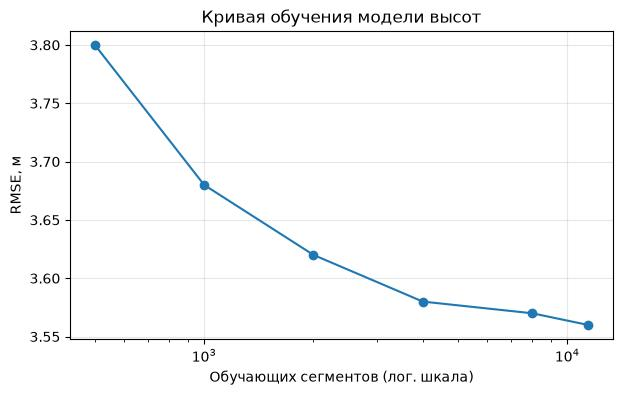

,Обучающих сегментов,"RMSE на отложенных блоках, м"
0,500,3.80
1,1000,3.68
2,2000,3.62
3,4000,3.58
4,8000,3.57
5,11400,3.56


In [ ]:
rows = []                                                                # Строки таблицы.
rng = np.random.default_rng(SEED)                                        # Генератор случайных чисел.
for n_train in [500, 1000, 2000, 4000, 8000, len(q)]:                    # Объёмы обучения.
    errs = []                                                            # Ошибки по пяти частям.
    for tr, te in GroupKFold(5).split(q, y, blk5):                       # Проверка по блокам 5 км.
        sub = rng.choice(tr, min(n_train, len(tr)), replace=False)       # Подвыборка обучающих точек.
        pred = hgb().fit(q[F_ETH].iloc[sub], y[sub]).predict(q[F_ETH].iloc[te])   # Обучение на подвыборке, прогноз на части.
        errs.append(y[te] - pred)
    rows.append([min(n_train, len(q)), height_metrics(np.concatenate(errs))["RMSE"]])
curve = pd.DataFrame(rows, columns=["Обучающих сегментов", "RMSE на отложенных блоках, м"]).round(2)
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(curve.iloc[:, 0], curve.iloc[:, 1], "o-"); ax.set_xscale("log")
ax.set_xlabel("Обучающих сегментов (лог. шкала)"); ax.set_ylabel("RMSE, м"); ax.set_title("Кривая обучения модели высот"); ax.grid(alpha=0.3)
plt.show()                                     # Показываем рисунок.
curve                                                                    # Показываем таблицу.

Основное снижение ошибки приходится на первые 1–2 тысячи точек, после 3–4 тысяч кривая почти горизонтальна. Поэтому для уточнения достаточно нескольких тысяч очищенных лазерных измерений.

### **7.4. Карта поправок и уточнённый рельеф**

Обучаем итоговую модель на всех точках и применяем ко всем пикселям — получаем изображение поправки и уточнённое изображение рельефа. Воду не уточняем.

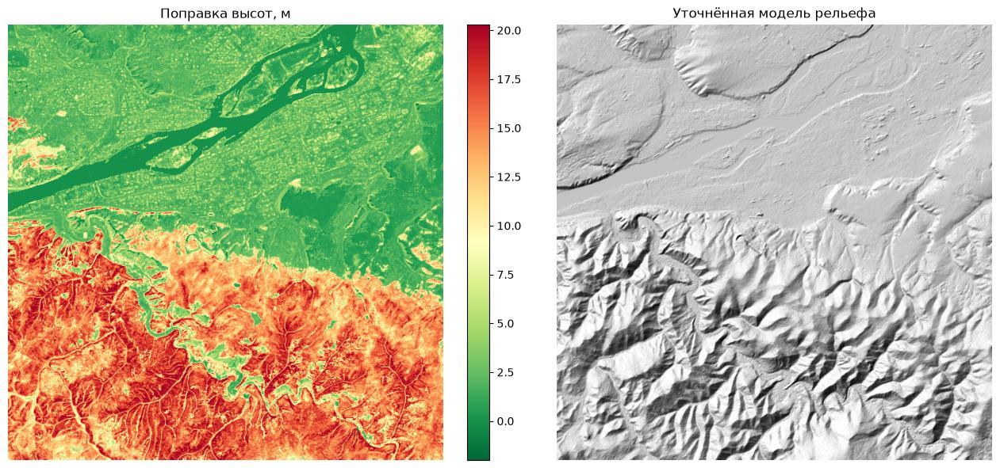

,Класс,Ячеек,"Поправка: медиана, м","Поправка: 95-й процентиль, м"
0,Лес,239143,14.36,19.17
1,Луга и пашня,68945,1.38,5.60
2,Застройка,109542,2.42,5.08
3,Открытый грунт,8291,1.53,7.39
4,Вода,20971,0.00,0.00


In [ ]:
model_h = hgb().fit(q[F_ETH], y)                                         # Итоговая модель: обучаем на всех точках.
G = np.column_stack([FEAT[k].ravel() for k in F_ETH])                    # Признаки всех ячеек: строка – ячейка.
corr = model_h.predict(pd.DataFrame(G, columns=F_ETH)).reshape(dem.shape)   # Прогноз завышения, преобразованный обратно в карту.
corr[cls == 6] = 0                                                       # Воду не уточняем.
dtm = dem - corr                                                         # Уточнённая модель рельефа.
q["oof"] = P["Модель ИИ с высотой леса"]                                 # Прогноз вне обучения в каждой точке.
rows = []                                                                # Строки будущей таблицы.
for c in classes_used:                                                   # Для каждого класса:
    m_ = cls == c                                                        # Ячейки класса на карте покрова.
    if m_.sum() > 0:
        rows.append({"Класс": CLASS_NAMES[c], "Ячеек": int(m_.sum()),
                     "Поправка: медиана, м": np.median(corr[m_]), "Поправка: 95-й процентиль, м": np.percentile(corr[m_], 95)})
by_cls = pd.DataFrame(rows).round(2)                                     # Поправка по классам.
fig, ax = plt.subplots(1, 2, figsize=(13, 6))                            # Два рисунка рядом.
im = ax[0].imshow(corr, cmap="RdYlGn_r", vmin=-2, vmax=np.percentile(corr, 99)); ax[0].set_title("Поправка высот, м")  # Слева – карта поправки.
plt.colorbar(im, ax=ax[0], fraction=0.046)                               # Шкала значений.
ax[1].imshow(ls.hillshade(dtm, vert_exag=3, dx=30, dy=30), cmap="gray"); ax[1].set_title("Уточнённая модель рельефа")  # Справа – отмывка уточнённой модели.
for a in ax: a.axis("off")                                               # Без осей координат.
plt.tight_layout(); plt.show()                  # Показываем рисунок.
by_cls                                                                   # Показываем таблицу.

Изображение поправки повторяет карту леса: в тайге поправка — метры и десятки метров, в городе и на лугах — около нуля. Проверим уточнённую модель на одной лазерной линии. Показан прогноз вне обучения: точки этой линии не участвовали в обучении модели, которая их предсказала.

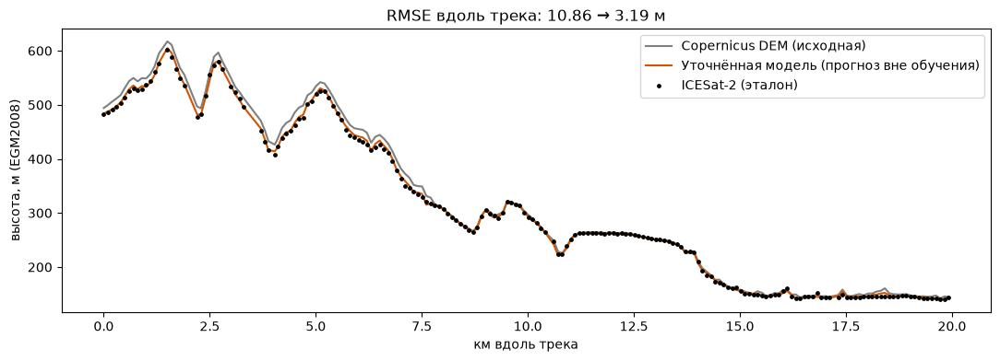

In [ ]:
q["trk"] = q.rgt.astype(str) + "_" + q.cycle.astype(str) + "_" + q.spot.astype(str)   # Одна линия: трек, цикл, луч.
q["is_forest"] = q.cls == 1                                              # Точка в лесу.
tracks = q.groupby("trk").agg(n=("dh", "size"), forest=("is_forest", "mean"))   # Длина линии и доля леса на ней.
tracks = tracks[tracks.n >= 120]                                         # Только длинные линии.
score = tracks.n * tracks.forest * (1.2 - tracks.forest)                 # Длинная линия с долей леса около 60 %.
line = q[q.trk == score.idxmax()].sort_values("lat")                     # Точки выбранной линии с юга на север.
X_, Y_ = Transformer.from_crs("EPSG:4326", GRID["crs"], always_xy=True).transform(line.lon.values, line.lat.values)   # Координаты точек в метрах.
dist = np.hypot(X_ - X_[0], Y_ - Y_[0]) / 1000                           # Расстояние от начала линии, км.
plt.figure(figsize=(13, 4))                                              # Широкий рисунок для профиля.
plt.plot(dist, line.cop, color="grey", label="Copernicus DEM (исходная)")  # Исходная модель вдоль линии.
plt.plot(dist, line.cop - line.oof, color="#d35400", label="Уточнённая модель (прогноз вне обучения)")
plt.scatter(dist, line.h_egm08, s=6, color="k", label="ICESat-2 (эталон)", zorder=5)  # Лазерные высоты.
plt.xlabel("км вдоль трека"); plt.ylabel("высота, м (EGM2008)"); plt.legend()  # Подписи осей, легенда.
rmse_before, rmse_after = height_metrics(line.dh)["RMSE"], height_metrics(line.dh - line.oof)["RMSE"]  # Ошибка на линии до и после.
plt.title(f"RMSE вдоль трека: {rmse_before:.2f} → {rmse_after:.2f} м"); plt.show()  # Заголовок и показ рисунка.

Исходная модель идёт над лазерными точками в лесу и совпадает с ними на открытых участках; уточнённая опускается к земле в лесу и не искажает открытые участки. Карта остатков показывает ошибку во всех точках до и после уточнения: красные — модель выше эталона, синие — ниже.

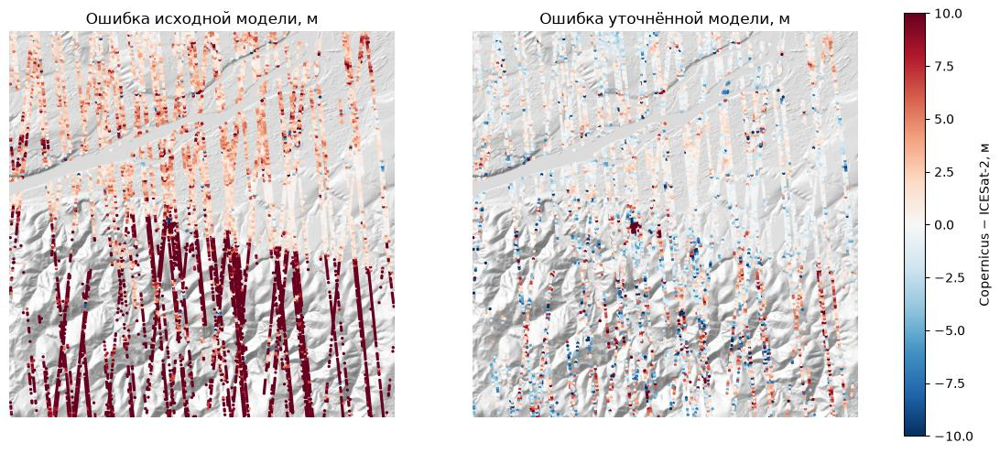

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))                            # Два рисунка рядом.
for a, e, t in [(ax[0], q.dh, "Ошибка исходной модели, м"), (ax[1], q.dh - q.oof, "Ошибка уточнённой модели, м")]:  # Две карты ошибок:
    a.imshow(ls.hillshade(dem, vert_exag=3, dx=30, dy=30), cmap="gray", alpha=0.6)   # Подложка – отмывка рельефа.
    sc = a.scatter(q.col, q.row, c=e, s=2, cmap="RdBu_r", vmin=-10, vmax=10)          # Точки, окрашенные по ошибке.
    a.set_title(t); a.axis("off")                                        # Заголовок, без осей.
plt.colorbar(sc, ax=ax, fraction=0.03, label="Copernicus − ICESat-2, м"); plt.show()  # Общая шкала и показ рисунка.

### **7.5. Трёхмерные поверхности до и после уточнения**

Разницу двух изображений рельефа видно на трёхмерной поверхности, если взять небольшой фрагмент на границе леса и открытой местности. Ячейка выбирает фрагмент 1,2×1,2 км, где лес занимает от 40 до 70 % и поправка в лесу сильно отличается от поправки вне леса, и строит на одном рисунке уточнённую поверхность (цвет — снимок) и исходную модель (красная сетка), а рядом — поверхность самой поправки.

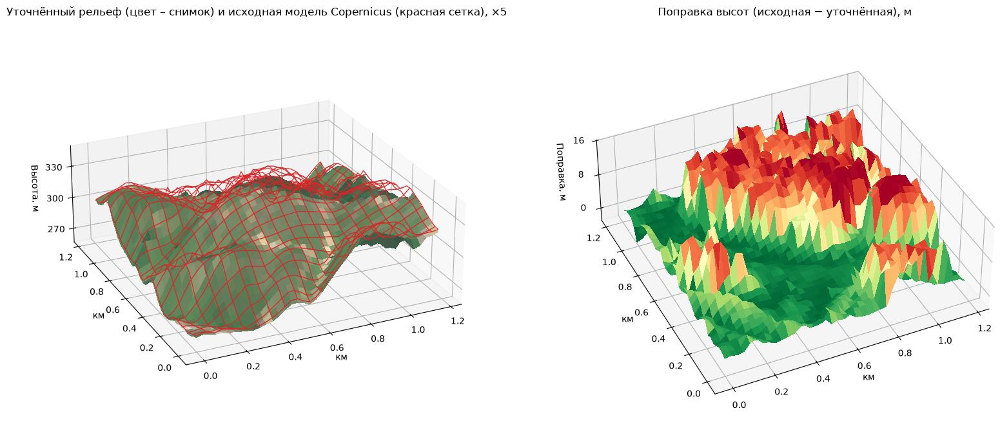

Фрагмент: перепад высот 89 м, доля леса 42%, средняя поправка в лесу 9.6 м, вне леса 1.6 м


In [ ]:
k_win = int(1200 / GRID["res"])                                          # Фрагмент 1,2×1,2 км на границе леса.
best, win = -np.inf, None
for r_ in range(0, GRID["H"] - k_win, k_win // 4):                               # Перебираем фрагменты с шагом 300 м:
    for c_ in range(0, GRID["W"] - k_win, k_win // 4):
        w_ = np.s_[r_:r_ + k_win, c_:c_ + k_win]
        fs = (cls[w_] == 1).mean()                                       # Доля леса во фрагменте.
        if not 0.4 <= fs <= 0.7 or (cls[w_] == 6).any():                 # Нужны и лес, и открытые участки, без воды.
            continue
        score = (corr[w_][cls[w_] == 1].mean() - corr[w_][cls[w_] != 1].mean()) / (np.ptp(dem[w_]) + 10)
        if score > best:                                                 # Большая разница поправки при небольшом перепаде высот.
            best, win = score, w_
Xs = np.arange(k_win) * GRID["res"] / 1000                               # Координаты узлов, км.
XX, YY = np.meshgrid(Xs, Xs[::-1])
fig = plt.figure(figsize=(17, 7))
ax = fig.add_subplot(1, 2, 1, projection="3d")                           # Две модели на одном рисунке.
ax.plot_surface(XX, YY, dtm[win], facecolors=rgb[win], rstride=1, cstride=1, linewidth=0, antialiased=False, shade=False)
ax.plot_wireframe(XX, YY, dem[win], color="#d62728", linewidth=0.9, rstride=2, cstride=2)   # Исходная модель – красная сетка.
ax.set_box_aspect((1, 1, 5 * np.ptp(dem[win]) / (k_win * GRID["res"])))  # Вертикальный масштаб ×5.
ax.view_init(elev=25, azim=-115); ax.zaxis.set_major_locator(plt.MaxNLocator(3))
ax.set_xlabel("км"); ax.set_ylabel("км"); ax.set_zlabel("Высота, м")
ax.set_title("Уточнённый рельеф (цвет – снимок) и исходная модель Copernicus (красная сетка), ×5")
ax = fig.add_subplot(1, 2, 2, projection="3d")
surface_3d(ax, corr[win], cmap="RdYlGn_r", z_ratio=0.35, title="Поправка высот (исходная − уточнённая), м", zlabel="Поправка, м")
plt.tight_layout(); plt.show()
print(f"Фрагмент: перепад высот {np.ptp(dem[win]):.0f} м, доля леса {100 * (cls[win] == 1).mean():.0f}%, средняя поправка в лесу {corr[win][cls[win] == 1].mean():.1f} м, вне леса {corr[win][cls[win] != 1].mean():.1f} м")

Над лесом красная сетка исходной модели поднимается над уточнённой поверхностью на высоту крон, а на открытом участке обе поверхности совпадают: модель уточнения опустила рельеф только там, где радар «видел» кроны. На поверхности поправки лес выглядит плато высотой в среднем около 10 м, открытые участки — низиной около нуля.

Интерактивная модель всего участка: на одну и ту же уточнённую модель рельефа наложены слева снимок, справа — карта покрова. Сцены поворачиваются мышью синхронно. Для скорости вершинами сетки служит каждый четвёртый пиксель (шаг 120 м).

In [ ]:
rgb8 = (rgb * 255).astype(np.uint8)                                     # Цвета снимка в диапазоне 0–255.
cls_rgb = np.zeros(cls.shape + (3,), np.uint8)                           # Цветное изображение карты покрова.
for c, color in CLASS_COLORS.items():                                    # Для каждого класса:
    cls_rgb[cls == c] = np.round(np.array(to_rgb(color)) * 255)          # цвет класса из "#rrggbb" в три числа 0–255.
title = f"{TERRITORY}: трёхмерная модель местности (вертикальный масштаб ×3)"  # Заголовок модели.
fig3d = mesh3d_pair(dtm, rgb8, cls_rgb, classes_used, GRID, step=4, title=title)  # Две сцены, вершины через 120 м.
fig3d.show(post_script=SYNC_JS)                                          # Интерактивная модель: сцены поворачиваются вместе.

### **7.6. Насколько результат зависит от решений**

**Алгоритм классификации.** Каждый алгоритм оценивается дважды: по качеству карты покрова (блоки 2 км) и по точности модели высот, построенной с его картой. Логистической регрессии и SVM нужна стандартизация признаков, поэтому они собраны в цепочку со `StandardScaler`. Расчёт занимает несколько минут.

In [ ]:
def gb_cls():
    """Градиентный бустинг для классификации."""
    return HistGradientBoostingClassifier(max_iter=300, random_state=SEED)

def logreg():
    """Логистическая регрессия со стандартизацией признаков."""
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

def svm():
    """Метод опорных векторов с радиальным ядром и стандартизацией."""
    return make_pipeline(StandardScaler(), SVC(C=10))

models = {"Random Forest": rf, "Градиентный бустинг": gb_cls, "Логистическая регрессия": logreg, "SVM (RBF)": svm}  # Сравниваемые алгоритмы.
pt = (np.round(q.row).astype(int) * GRID["W"] + np.round(q.col).astype(int)).values   # Номера ячеек с точками ICESat-2.
rows = []                                                                # Строки будущей таблицы.
for name, fn in models.items():                                          # Для каждого алгоритма:
    t = time.time()                                                      # Засекаем время.
    p_ = cv_classify(X_b, fn)                                            # Качество карты покрова вне обучения.
    q_m = q.copy()                                                       # Копия таблицы точек.
    q_m["cls"] = fn().fit(X_b[idx], y_all[idx]).predict(X_b[pt])         # Карта покрова этого алгоритма в точках.
    rmse_h = height_metrics(y - cv_correction(q_m, y, blk5, F_ETH))["RMSE"]   # Точность высот с этой картой.
    rows.append([name, accuracy_score(y_all[idx], p_), f1_score(y_all[idx], p_, average="macro"), rmse_h, time.time() - t])  # Строка таблицы.
v2 = pd.DataFrame(rows, columns=["Алгоритм", "Общая точность", "Средний F1", "RMSE высот после уточнения, м", "Время, с"]).round(3)  # Таблица сравнения алгоритмов.
v2                                                                       # Показываем таблицу.

,Алгоритм,Общая точность,Средний F1,"RMSE высот после уточнения, м","Время, с"
0,Random Forest,0.851,0.827,3.560,28.924
1,Градиентный бустинг,0.854,0.830,3.562,21.051
2,Логистическая регрессия,0.851,0.828,3.568,14.030
3,SVM (RBF),0.856,0.832,3.557,47.924


Алгоритмы дают близкую точность карты покрова и практически одинаковую точность высот после уточнения: результат определяют признаки, а не способ их обработки.

**Модель высот и её параметры.** Сравним градиентный бустинг со случайным лесом и проверим, как бустинг зависит от шага обучения и числа деревьев.

In [ ]:
from sklearn.ensemble import RandomForestRegressor                      # Случайный лес для регрессии.
from sklearn.base import clone                                           # Копия модели с теми же параметрами.

def rmse(e):
    "Среднеквадратическая ошибка, м."
    return float(np.sqrt(np.mean(np.square(e))))

def cv_model(model, feats):
    "Прогноз завышения вне обучения для произвольной модели по блокам 5 км."
    pred = np.zeros(len(q))
    for tr, te in GroupKFold(5).split(q, y, blk5):
        fitted = clone(model).fit(q[feats].iloc[tr], y[tr])              # Новая копия модели для каждой части.
        pred[te] = fitted.predict(q[feats].iloc[te])
    return pred

def scores(e):
    "RMSE, MAE, смещение и R² для ошибок e."
    return {"RMSE": rmse(e), "MAE": float(np.mean(np.abs(e))), "смещение": float(np.median(e)),
            "R²": float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2))}

cands = {"Градиентный бустинг": hgb(),                                   # Модель из раздела 4.2.
         "Случайный лес": RandomForestRegressor(300, min_samples_leaf=5, max_features=0.5, n_jobs=N_JOBS, random_state=SEED)}
rows = []                                                                # Строки будущей таблицы.
for name, model in cands.items():                                        # Для каждой модели:
    t = time.time()                                                      # засекаем время,
    e = y - cv_model(model, F_ETH)                                       # ошибки прогноза вне обучения.
    rows.append({"Модель": name, **scores(e), "Смещение в лесу": float(np.median(e[forest])), "Время, с": time.time() - t})
v2_models = pd.DataFrame(rows).round(3)                                  # Таблица сравнения моделей.
v2_models                                                                # Показываем таблицу.

,Модель,RMSE,MAE,смещение,R²,Смещение в лесу,"Время, с"
0,Градиентный бустинг,3.560,2.237,-0.044,0.720,0.037,12.884
1,Случайный лес,3.525,2.246,-0.086,0.725,-0.010,7.981


In [ ]:
rows = []                                                                # Строки будущей таблицы.
for lr in (0.02, 0.05, 0.1):                                             # Шаг обучения.
    for it in (200, 400, 800):                                           # Число итераций (деревьев).
        model = HistGradientBoostingRegressor(loss="absolute_error", max_iter=it, learning_rate=lr,
                                              categorical_features=[0], random_state=SEED)
        e = y - cv_model(model, F_ETH)                                   # Ошибки прогноза вне обучения.
        rows.append({"Шаг обучения": lr, "Итераций": it, **scores(e)})
v2_params = pd.DataFrame(rows).round(3)                                  # Таблица чувствительности.
print(f"Разброс RMSE по сетке параметров: {v2_params.RMSE.min():.3f} … {v2_params.RMSE.max():.3f} м")
v2_params                                                                # Показываем таблицу.

Разброс RMSE по сетке параметров: 3.550 … 3.627 м


,Шаг обучения,Итераций,RMSE,MAE,смещение,R²
0,0.02,200,3.550,2.239,-0.044,0.721
1,0.02,400,3.555,2.236,-0.039,0.721
2,0.02,800,3.565,2.238,-0.040,0.719
3,0.05,200,3.552,2.234,-0.038,0.721
4,0.05,400,3.560,2.237,-0.044,0.720
5,0.05,800,3.573,2.245,-0.052,0.718
6,0.10,200,3.588,2.253,-0.051,0.715
7,0.10,400,3.610,2.265,-0.055,0.712
8,0.10,800,3.627,2.275,-0.060,0.709


Разница между моделями и между вариантами параметров — сантиметры, тогда как само уточнение уменьшает ошибку в разы. Подбор алгоритма здесь вторичен по сравнению с выбором признаков.

**Глобальные модели рельефа.** Та же схема уточнения применяется к каждой из четырёх моделей; ALOS, MERIT и NASADEM заданы над EGM96, поэтому сравниваются с лазерными высотами в EGM96.

In [ ]:
rows = []                                                                # Строки будущей таблицы.
DEM_NAMES = {"cop": "Copernicus GLO-30", "alos": "ALOS AW3D30", "merit": "MERIT DEM", "nasadem": "NASADEM"}   # Названия моделей.
for name, ref in [("cop", "h_egm08"), ("alos", "h_egm96"), ("merit", "h_egm96"), ("nasadem", "h_egm96")]:  # Модель и её система высот:
    d_ = map_coordinates(stack[name], [q.row.values, q.col.values], order=1) - q[ref].values   # Завышение модели в точках.
    ok = np.abs(d_) < MAX_DH                                             # То же правило грубых выбросов.
    p_ = cv_correction(q[ok], d_[ok], blk5[ok], F_ETH)                   # Поправка вне обучения.
    before, after = height_metrics(d_[ok]), height_metrics(d_[ok] - p_)  # Ошибки до и после уточнения.
    rows.append({"Модель": DEM_NAMES[name], "RMSE до": before["RMSE"], "смещение до": before["смещение"],  # Строка таблицы.
                 "RMSE после": after["RMSE"], "смещение после": after["смещение"]})
v4 = pd.DataFrame(rows).round(2)                                         # Таблица сравнения моделей рельефа.
v4                                                                       # Показываем таблицу.

,Модель,RMSE до,смещение до,RMSE после,смещение после
0,Copernicus GLO-30,9.25,3.56,3.56,-0.04
1,ALOS AW3D30,9.27,3.00,5.19,0.07
2,MERIT DEM,6.46,2.96,3.91,-0.07
3,NASADEM,7.42,2.94,4.03,-0.00


До уточнения меньше всех ошибается MERIT: при её построении уже исправлено влияние растительности. После уточнения лучшей становится Copernicus: шаг 30 м, самая поздняя съёмка и наименьшая остаточная ошибка. Систематическое завышение уточнение убирает у всех моделей.

**Где помогает высота леса.** Сравним модели без признака ETH и с ним по классам покрова и по градациям высоты леса.

In [ ]:
e_no = y - P["Модель ИИ без высоты леса"]                                # Ошибки модели без признака ETH.
e_eth = y - P["Модель ИИ с высотой леса"]                                # Ошибки модели с признаком ETH.
rows = []                                                                # Строки будущей таблицы.
for c in classes_used:                                                   # Группы по классам покрова.
    m_ = (q.cls == c).values
    if m_.sum() >= 30:                                                   # Малые группы не оцениваем.
        rows.append([CLASS_NAMES[c], int(m_.sum()), rmse(e_no[m_]), rmse(e_eth[m_])])
for lo, hi, name in [(-1, 5, "до 5 м"), (5, 15, "5–15 м"), (15, 25, "15–25 м"), (25, 99, "более 25 м")]:   # Интервалы высоты леса ETH.
    m_ = ((q.eth > lo) & (q.eth <= hi)).values                           # Точки с высотой леса в интервале.
    if m_.sum() >= 30:
        rows.append([f"высота леса ETH {name}", int(m_.sum()), rmse(e_no[m_]), rmse(e_eth[m_])])
v5 = pd.DataFrame(rows, columns=["Группа", "Сегментов", "RMSE без ETH, м", "RMSE с ETH, м"])
v5["Изменение, %"] = 100 * (v5["RMSE с ETH, м"] - v5["RMSE без ETH, м"]) / v5["RMSE без ETH, м"]   # Отрицательное – выигрыш.
v5 = v5.round(2)                                                         # Округляем для таблицы.
v5                                                                       # Показываем таблицу.

,Группа,Сегментов,"RMSE без ETH, м","RMSE с ETH, м","Изменение, %"
0,Лес,4830,4.62,4.35,-5.79
1,Луга и пашня,2043,2.78,2.70,-2.91
2,Застройка,4202,2.53,2.52,-0.14
3,Открытый грунт,325,6.08,5.91,-2.77
4,высота леса ETH до 5 м,4133,2.97,2.93,-1.33
5,высота леса ETH 5–15 м,2733,2.56,2.45,-4.52
6,высота леса ETH 15–25 м,3142,4.49,4.34,-3.48
7,высота леса ETH более 25 м,1392,5.35,4.91,-8.28


Карта высоты леса даёт наибольший выигрыш в высоком лесу (выше 25 м ошибка уменьшается на 8 %), в застройке она ничего не добавляет. Выигрыш невелик: высокий лес модель находит и по спектру, и по собственной карте покрова.

**Перенос на соседнюю территорию.** Обучаем на западной половине участка и проверяем на восточной, затем наоборот.

In [ ]:
west = (q.col < GRID["W"] / 2).values                                    # Точки западной половины участка.
rows = []                                                                # Строки будущей таблицы.
for name, tr_m in [("обучение на западе → проверка на востоке", west), ("обучение на востоке → проверка на западе", ~west)]:  # Две схемы переноса:
    mdl = hgb().fit(q[F_ETH][tr_m], y[tr_m])                              # Обучаем на одной половине.
    e_ = y[~tr_m] - mdl.predict(q[F_ETH][~tr_m])                          # Ошибка на другой половине.
    rows.append({"Схема": name, "RMSE без поправки": height_metrics(y[~tr_m])["RMSE"], "RMSE после переноса": height_metrics(e_)["RMSE"]})  # Строка таблицы.
v6 = pd.DataFrame(rows).round(2)                                         # Таблица переноса.
v6                                                                       # Показываем таблицу.

,Схема,RMSE без поправки,RMSE после переноса
0,обучение на западе → проверка на востоке,9.46,3.37
1,обучение на востоке → проверка на западе,9.02,3.86


Ошибка при переносе того же порядка, что при проверке по блокам, и в разы меньше ошибки без поправки: модель переносится на соседнюю территорию с похожим покровом.

**Сезон измерений.** Сравним модель, обученную на измерениях всех сезонов (включая снег), и модель, обученную только на летних; проверка в обоих случаях — на летних измерениях отложенных блоков.

In [ ]:
qa = isat_q.copy()                                                       # Измерения после фильтров качества, включая снежные.
qa["h_egm08"] = ellipsoid_to_geoid(qa.h_ground.values, qa.lon.values, qa.lat.values)   # Высота над EGM2008.
qa["row"], qa["col"] = lonlat_to_rowcol(qa.lon.values, qa.lat.values, GRID)   # Положение на сетке.
inside = (qa.row > 1) & (qa.row < GRID["H"] - 2) & (qa.col > 1) & (qa.col < GRID["W"] - 2)  # Точки не у края сетки.
qa = qa[inside].copy()                                                   # Точки не у края сетки.
qa["dh"] = map_coordinates(dem, [qa.row.values, qa.col.values], order=1) - qa.h_egm08   # Завышение модели рельефа.
ia, ja = np.round(qa.row).astype(int).values, np.round(qa.col).astype(int).values   # Ячейка сетки для каждой точки.
for k, a in FEAT.items():                                                # Для каждого признака:
    qa[k] = a[ia, ja]                                                    # Те же признаки, что в 4.2.
qa["wc"], qa["lossyear"] = stack["wc"][ia, ja], stack["lossyear"][ia, ja]  # Для правил очистки.
keep = (qa.cls != 6) & (qa.wc != 80) & ~qa.landcover.isin([80, 200]) & (qa.lossyear < 11) & (qa.dh.abs() < MAX_DH)
qa = qa[keep]                                                            # Те же правила очистки, кроме снега.
blk_a = block_id(qa.row.values, qa.col.values, GRID, 5000)               # Блоки 5 км.
summer = (qa.snowcover <= 1).values                                      # Измерения без снега.
ya = qa.dh.values                                                        # Целевая переменная.
e_all, e_sum = [], []                                                    # Ошибки двух моделей на проверке.
for tr, te in GroupKFold(5).split(qa, ya, blk_a):                        # Пять частей по блокам 5 км:
    te_s = te[summer[te]]                                                # Проверяем только на летних точках.
    tr_s = tr[summer[tr]]                                                # Летние точки обучающих блоков.
    m_all = hgb().fit(qa[F_ETH].iloc[tr], ya[tr])                        # Модель на всех сезонах.
    m_sum = hgb().fit(qa[F_ETH].iloc[tr_s], ya[tr_s])                    # Модель только на летних.
    e_all.append(ya[te_s] - m_all.predict(qa[F_ETH].iloc[te_s]))         # Ошибки модели «все сезоны».
    e_sum.append(ya[te_s] - m_sum.predict(qa[F_ETH].iloc[te_s]))         # Ошибки модели «только лето».
v7 = pd.DataFrame([{"Обучающие измерения": "все сезоны (со снегом)", **height_metrics(np.concatenate(e_all))},  # Таблица сравнения сезонов.
                   {"Обучающие измерения": "только без снега", **height_metrics(np.concatenate(e_sum))}]).round(2)
print(f"Доля измерений со снегом: {100 * (1 - summer.mean()):.0f}%")     # Сколько измерений со снегом.
v7                                                                       # Показываем таблицу.

Доля измерений со снегом: 42%


,Обучающие измерения,RMSE,MAE,смещение,NMAD,LE90
0,все сезоны (со снегом),3.53,2.24,0.04,1.93,5.57
1,только без снега,3.54,2.25,-0.05,1.91,5.64


Точность двух моделей на летних точках одинакова (RMSE 3,53 и 3,54 м): исключение зимних измерений не ухудшает модель, а делает эталон однородным.

### **Выводы по разделу 7:**

1. **Уточнение рельефа** — регрессия по изображениям: модель предсказывает завышение высот в каждом пикселе по классу покрова, рельефу и снимку
2. **Модель точнее простых правил** при проверке по блокам; её прогноз повторяет физическую зависимость завышения от высоты полога
3. **Нескольких тысяч** лазерных измерений достаточно: кривая обучения выходит на полку
4. **Трёхмерные поверхности** показывают, что уточнённый рельеф в лесу опускается с крон на землю
5. **Результат устойчив** к выбору алгоритма и его параметров; решающими оказываются признаки и качество эталона

---

## **Раздел 8. Гравитационное поле как изображение: аномалии Буге**

### **8.1. Что такое аномалия Буге и зачем она нужна**

Сила тяжести в разных точках Земли немного разная. Модель GGMplus показывает для каждого пикселя, на сколько миллигал она отличается от «нормальной» силы тяжести идеального эллипсоида, — это **возмущение силы тяжести** $\delta g$. Отличие складывается из двух частей, и их важно различать.

Представим, что одну и ту же гирю взвешивают на очень точных пружинных весах в разных местах. На вершине холма под гирей лежит лишняя толща пород, она притягивает гирю, и весы покажут чуть больше. Над залежью плотной железной руды весы тоже покажут больше — руда притягивает сильнее, чем окружающие породы. А над впадиной, заполненной рыхлыми лёгкими осадками, — меньше. На карте $\delta g$ все эти причины смешаны, и вклад видимого рельефа в ней самый большой: на участке примера коэффициент корреляции возмущения со сглаженным рельефом близок к единице.

Но рельеф мы знаем — он есть на изображении ЦМР. Значит, его притяжение можно **рассчитать и вычесть** из измеренного поля. То, что останется, — **аномалия Буге** — показывает только то, чего на поверхности не видно: где под землёй породы тяжелее или легче среднего. Высота рельефа и класс покрова видны сразу, а аномалия Буге — это способ «заглянуть» под поверхность, не бурясь.

Для чего это нужно:
- **поиск полезных ископаемых**: плотные рудные тела (например, железные руды Курской магнитной аномалии) дают положительные аномалии, соляные купола и осадочные впадины — отрицательные;
- **геологическое картирование**: границы блоков пород и разломы видны как резкие перепады аномалий;
- **инженерные изыскания**: пустоты и карст под площадкой строительства дают небольшие отрицательные аномалии;
- **геодезия**: аномалии Буге используются при вычислении геоида и приведении гравиметрических измерений.

Притяжение рельефа в простейшем приближении (редукция Буге) — притяжение бесконечного плоского слоя толщиной $H$ (высота точки) и плотностью $\rho = 2670$ кг/м³ (средняя плотность горных пород):

$$\Delta g_B = 2\pi G \rho H \approx 0{,}1119 \cdot H \text{ мГал}.$$

Каждый метр высоты добавляет к силе тяжести 0,11 мГал. Вычитая его, получаем возмущение Буге $\delta g_B = \delta g - 0{,}1119 \cdot H$ (для краткости дальше — аномалия Буге). Поправка за форму окружающих гор здесь не вводится.

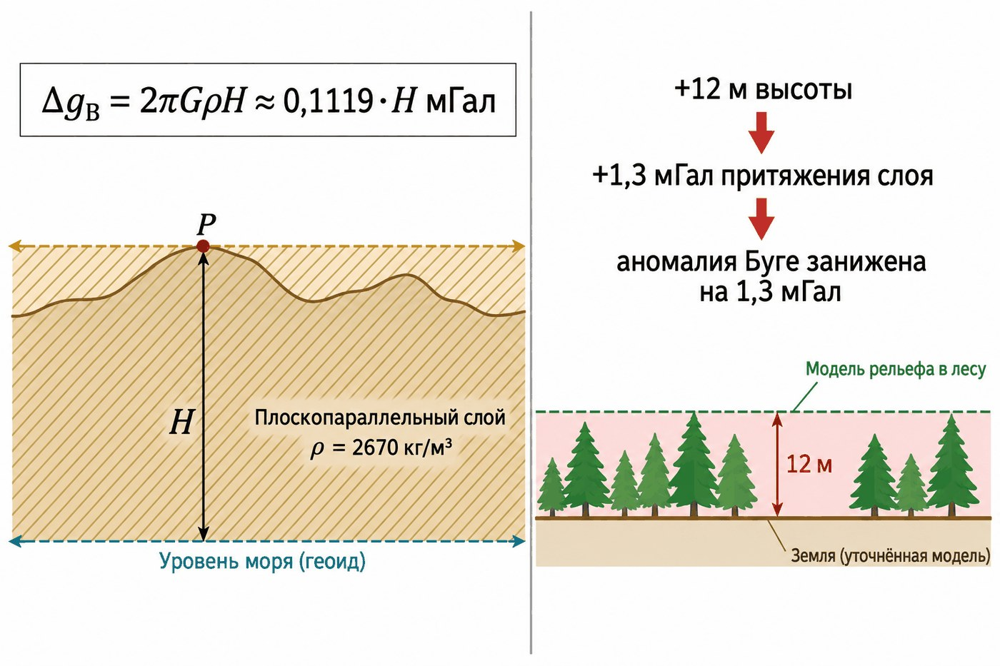

*Плоский слой Буге и влияние завышения высоты на аномалию Буге.*

**Почему здесь важна точность рельефа.** Аномалия Буге получается вычитанием, и всё, что неверно в высоте, переходит в аномалию. Если в лесу ЦМР завышена на 12 м, притяжение слоя завышено на $0{,}1119 \cdot 12 \approx 1{,}3$ мГал, и аномалия Буге в лесу занижена на ту же величину. Локальные аномалии, ради которых всё делается, имеют амплитуду в единицы миллигал. Значит, ошибка рельефа рисует на карте ложную отрицательную «аномалию», повторяющую контуры леса, — её можно принять за реальную геологическую структуру. Поэтому уточнение рельефа и выполняется перед гравиметрическим расчётом.

**С точки зрения обработки изображений** вся цепочка — операции над растрами: вычитание изображения, рассчитанного по ЦМР, из измеренного; сглаживание гауссовым фильтром (фон, низкие частоты); вычитание фона (остаток, высокие частоты); пороговая сегментация остатка (аномальные структуры); кластеризация структур (типы). Поле GGMplus модельное — его мелкие детали сами рассчитаны по рельефу SRTM, — поэтому выделенные здесь структуры служат учебным примером, а не геологической картой.

### **8.2. Поле на сетке участка и его связь с рельефом**

Пересчитаем поле GGMplus (шаг около 220 м) на сетку участка 30 м билинейной интерполяцией и сравним его с рельефом.

In [ ]:
t = time.time()                                                          # Засекаем время.
LON, LAT = grid_lonlat(GRID)                                             # Долгота и широта центра каждой ячейки.
GGM_BOUNDS = [LON.min() - 0.01, LAT.min() - 0.01, LON.max() + 0.01, LAT.max() + 0.01]   # Сетка UTM по углам выходит за
dg_ll, g_lons, g_lats = load_ggmplus(GGM_BOUNDS, "dg")                  # границы, поэтому загружаем с запасом 0,01°.
zeta_ll, _, _ = load_ggmplus(GGM_BOUNDS, "geoid")                        # Высоты квазигеоида на той же сетке GGMplus.
fi, fj = (LAT - g_lats[0]) / 0.002, (LON - g_lons[0]) / 0.002            # Дробные номера узлов GGMplus для наших ячеек.
dg = map_coordinates(dg_ll, [fi, fj], order=1, mode="nearest")           # Возмущения силы тяжести на сетке участка, мГал.
zeta = map_coordinates(zeta_ll, [fi, fj], order=1, mode="nearest")       # Высоты квазигеоида на сетке участка, м.
assert not np.isnan(dg).any(), "На участке нет данных GGMplus (море или выход за 60° с. ш.)"  # Проверка: поле есть во всех ячейках.
print(f"Возмущения силы тяжести: {np.nanmin(dg):.1f} … {np.nanmax(dg):.1f} мГал; квазигеоид {np.nanmin(zeta):.2f} … {np.nanmax(zeta):.2f} м; {time.time() - t:.0f} с")
relief_smooth = gaussian_filter(stack["cop"], 8)                         # Сглаженный рельеф (масштаб поля GGMplus).
corr_relief = np.corrcoef(relief_smooth.ravel(), dg.ravel())[0, 1]       # Связь возмущений с рельефом.
print(f"Корреляция возмущений с рельефом: {corr_relief:.2f}")
ggm_params = pd.DataFrame([                                              # Параметры загрузки.
    ["Источник поля", "фрагмент вокруг участка из подготовленных данных" if ggm_source()[0] == "подготовленные данные" else f"{files_ru(len(ggm_source()[1]))} 5°×5° с сервера Curtin University (возмущения и квазигеоид)"],
    ["Границы загрузки", f"долгота {GGM_BOUNDS[0]:.3f}…{GGM_BOUNDS[2]:.3f}°, широта {GGM_BOUNDS[1]:.3f}…{GGM_BOUNDS[3]:.3f}°"],
    ["Шаг сетки GGMplus", "0,002° (около 220 м)"],
    ["Пересчёт на сетку участка", f"билинейная интерполяция, 30 м, {GRID['crs']}"],
    ["Возмущения силы тяжести, мГал", f"{np.nanmin(dg):.1f} … {np.nanmax(dg):.1f}"],
    ["Высота квазигеоида, м", f"{np.nanmin(zeta):.2f} … {np.nanmax(zeta):.2f}"],
    ["Корреляция возмущений с рельефом", f"{corr_relief:.2f}"],
], columns=["Параметр", "Значение"])
ggm_params                                                               # Показываем таблицу.

Возмущения силы тяжести: -80.2 … 19.0 мГал; квазигеоид -39.34 … -38.07 м; 0 с
Корреляция возмущений с рельефом: 0.96


,Параметр,Значение
0,Источник поля,фрагмент вокруг участка из подготовленных данных
1,Границы загрузки,"долгота 92.739…93.080°, широта 55.860…56.060°"
2,Шаг сетки GGMplus,"0,002° (около 220 м)"
3,Пересчёт на сетку участка,"билинейная интерполяция, 30 м, EPSG:32646"
4,"Возмущения силы тяжести, мГал",-80.2 … 19.0
5,"Высота квазигеоида, м",-39.34 … -38.07
6,Корреляция возмущений с рельефом,0.96


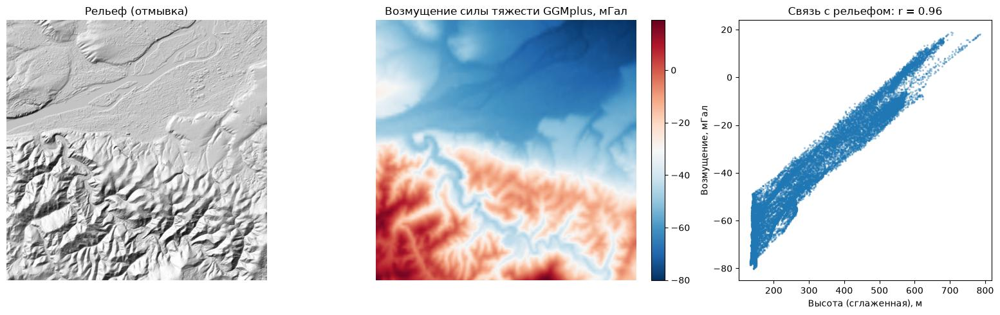

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})   # Две карты и диаграмма.
ax[0].imshow(ls.hillshade(stack["cop"], vert_exag=3, dx=30, dy=30), cmap="gray"); ax[0].set_title("Рельеф (отмывка)"); ax[0].axis("off")
im = ax[1].imshow(dg, cmap="RdBu_r"); ax[1].set_title("Возмущение силы тяжести GGMplus, мГал"); ax[1].axis("off"); plt.colorbar(im, ax=ax[1], fraction=0.046)
sub = np.random.default_rng(SEED).choice(dg.size, 20000, replace=False)  # Выборка ячеек для диаграммы.
ax[2].scatter(relief_smooth.ravel()[sub], dg.ravel()[sub], s=2, alpha=0.3); ax[2].set_xlabel("Высота (сглаженная), м"); ax[2].set_ylabel("Возмущение, мГал")
ax[2].set_title(f"Связь с рельефом: r = {corr_relief:.2f}")
plt.tight_layout(); plt.show()                # Показываем рисунок.

Возмущение почти линейно растёт с высотой: коэффициент корреляции со сглаженным рельефом близок к единице. Именно эту часть поля и убирает редукция Буге.

### **8.3. Цепочка расчёта как обработка изображений**

GGMplus не содержит деталей мельче своей ячейки (около 220 м), поэтому высоты перед расчётом осредняются в окне 7×7 пикселей (210 м) — фильтр низких частот приводит изображение рельефа к разрешению поля. Аномалия Буге считается дважды: по исходной и по уточнённой модели рельефа.

Поле складывается из плавной региональной части (глубинные структуры коры) и локальных аномалий. Фон оценивается **гауссовым фильтром** с σ = 3 км — сглаживанием, в котором соседи учитываются с весами, убывающими с расстоянием по нормальному закону, — и вычитается; остаток — локальные аномалии. *Аномальными структурами* считаются пиксели, где модуль остатка больше 1,5 стандартного отклонения остатка, — это пороговая сегментация.

In [ ]:
K_BOUGUER = 0.1119                                                       # Притяжение слоя 1 м плотностью 2670 кг/м³, мГал.

def smooth(a):
    """Среднее в окне 7×7 ячеек (210 м): осреднение до разрешения GGMplus."""
    return uniform_filter(a, 7)

bg0 = dg - K_BOUGUER * smooth(dem)                                       # Возмущение Буге по исходным высотам.
bg1 = dg - K_BOUGUER * smooth(dtm)                                       # Возмущение Буге по уточнённым высотам.

def anomalies(bg, sigma_km=3, k=1.5):
    """Остаток после вычитания регионального фона и маска аномальных структур."""
    resid = bg - gaussian_filter(bg, sigma_km * 1000 / GRID["res"])      # Вычитаем плавный фон (параметр в ячейках).
    return resid, np.abs(resid) > k * np.std(resid)                      # Остаток и маска |остаток| > k·σ.

r0, a0 = anomalies(bg0)                                                  # Остаток и структуры по исходным высотам.
r1, a1 = anomalies(bg1)                                                  # То же по уточнённым высотам.
forest_s = uniform_filter((cls == 1).astype(float), 7) > 0.5             # Ячейки, где в окне 210 м преобладает лес.
surfaces = {"Лес": cls == 1, "Застройка": cls == 4, "Открытая местность": np.isin(cls, [3, 5])}   # Типы поверхности.
rows = []                                                                # Строки будущей таблицы.
for name, mask in surfaces.items():                                      # Для каждого типа поверхности:
    m_ = uniform_filter(mask.astype(float), 7) > 0.5                     # Тип преобладает в окне 210 м.
    if m_.sum() > 100:
        rows.append([name, np.median((bg1 - bg0)[m_]), 100 * a0[m_].mean(), 100 * a1[m_].mean()])  # Сдвиг Буге и доля аномальной площади.
grav = pd.DataFrame(rows, columns=["Тип поверхности", "Сдвиг аномалии Буге, мГал", "Аномальная площадь (исходные высоты), %", "Аномальная площадь (уточнённые высоты), %"]).round(2)  # Таблица гравиметрического блока.
changed = 100 * (a0 & ~a1).sum() / a0.sum()                              # Доля структур, исчезнувших после уточнения.
new = 100 * (a1 & ~a0).sum() / a1.sum()                                  # Доля структур, появившихся после уточнения.
print(f"Остаточные аномалии: σ = {np.std(r0):.2f} мГал; исчезло после уточнения {changed:.0f}% аномальной площади, появилось {new:.0f}%")
grav                                                                     # Показываем таблицу.

Остаточные аномалии: σ = 1.40 мГал; исчезло после уточнения 11% аномальной площади, появилось 12%


,Тип поверхности,"Сдвиг аномалии Буге, мГал","Аномальная площадь (исходные высоты), %","Аномальная площадь (уточнённые высоты), %"
0,Лес,1.64,12.50,13.66
1,Застройка,0.30,14.55,12.76
2,Открытая местность,0.19,12.76,13.44


Промежуточные изображения удобно увидеть рядом: так видно, какую часть поля убирает каждый шаг.

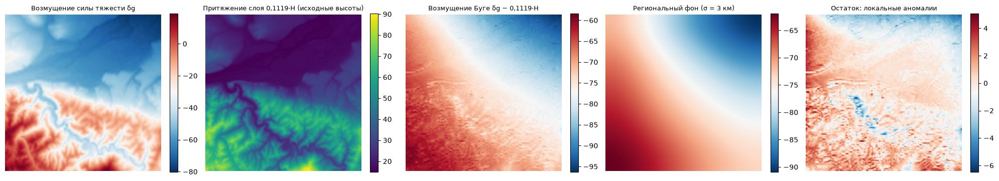

In [ ]:
fields = [(dg, "Возмущение силы тяжести δg", "RdBu_r"), (K_BOUGUER * smooth(dem), "Притяжение слоя 0,1119·H (исходные высоты)", "viridis"),
          (bg0, "Возмущение Буге δg − 0,1119·H", "RdBu_r"), (gaussian_filter(bg0, 3000 / GRID["res"]), "Региональный фон (σ = 3 км)", "RdBu_r"), (r0, "Остаток: локальные аномалии", "RdBu_r")]
fig, ax = plt.subplots(1, 5, figsize=(20, 4.2))                          # Пять карт в ряд.
for a, (arr, t, cmap) in zip(ax, fields):
    im = a.imshow(arr, cmap=cmap); a.set_title(t, fontsize=9); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()                # Показываем рисунок.

Притяжение слоя повторяет рельеф и по величине сопоставимо с самим возмущением; после его вычитания поле становится более гладким, а после вычитания регионального фона остаются локальные аномалии амплитудой в единицы миллигал.

### **8.4. Трёхмерные поверхности гравитационного поля**

Поле — тоже изображение, и его можно построить как поверхность: высота поверхности — значение поля в миллигалах. Так особенно наглядно, как вычитание притяжения рельефа «выравнивает» поле и как после вычитания фона остаются отдельные локальные максимумы и минимумы.

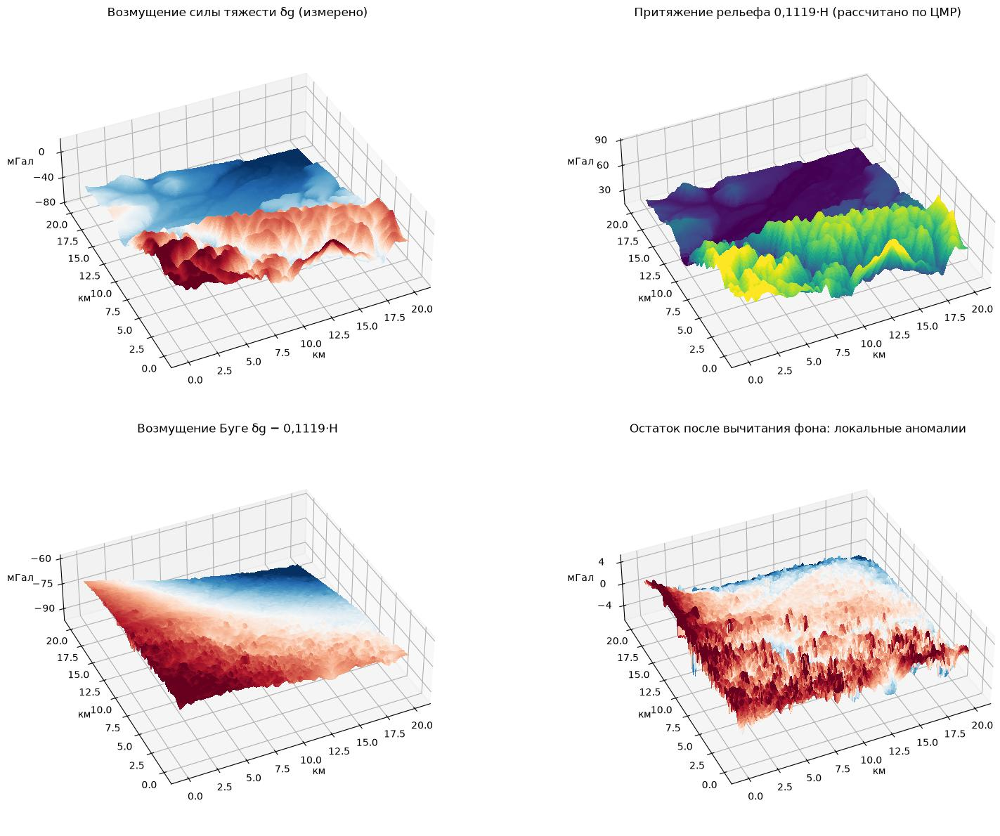

In [ ]:
fields_3d = [(dg, "Возмущение силы тяжести δg (измерено)", "RdBu_r"),
             (K_BOUGUER * smooth(dem), "Притяжение рельефа 0,1119·H (рассчитано по ЦМР)", "viridis"),
             (bg0, "Возмущение Буге δg − 0,1119·H", "RdBu_r"),
             (r0, "Остаток после вычитания фона: локальные аномалии", "RdBu_r")]
fig = plt.figure(figsize=(18, 12))                                       # Четыре поверхности: два ряда по две.
for i, (Z, t, cmap) in enumerate(fields_3d):
    ax = fig.add_subplot(2, 2, i + 1, projection="3d")
    surface_3d(ax, Z, cmap=cmap, z_ratio=0.3, title=t, zlabel="мГал")    # Высота поверхности – значение поля, мГал.
plt.tight_layout(); plt.show()

Поверхность $\delta g$ повторяет рельеф: возвышенность на юге — «гора» поля. После вычитания притяжения рельефа гора исчезает, остаётся плавный наклон регионального фона, а поверхность остатка — набор отдельных холмов и впадин амплитудой в единицы миллигал: это и есть локальные аномалии.

### **8.5. Аномалии по исходным и уточнённым высотам**

Построим карты остаточных аномалий по исходным и уточнённым высотам с контурами структур и карту сдвига аномалии Буге.

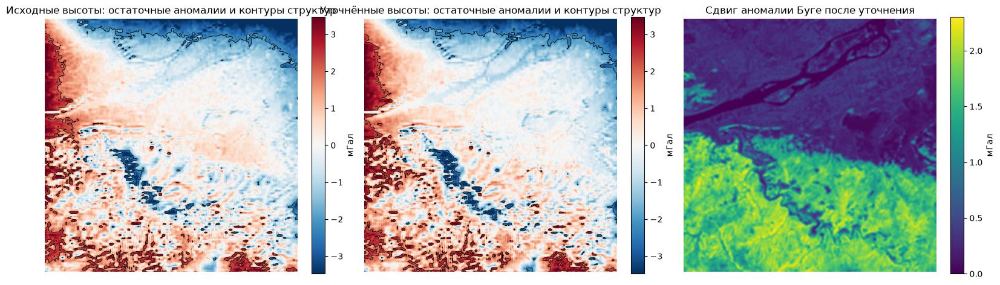

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))                            # Три рисунка рядом.
vmax = np.percentile(np.abs(r0), 98)                                     # Общая шкала для двух карт остатка.
for a, arr, msk, t in [(ax[0], r0, a0, "Исходные высоты"), (ax[1], r1, a1, "Уточнённые высоты")]:  # Две карты остатка:
    im = a.imshow(arr, cmap="RdBu_r", vmin=-vmax, vmax=vmax); plt.colorbar(im, ax=a, fraction=0.046, label="мГал")  # Остаток и шкала.
    a.contour(msk, levels=[0.5], colors="k", linewidths=0.6); a.set_title(f"{t}: остаточные аномалии и контуры структур")   # Границы структур.
im = ax[2].imshow(bg1 - bg0, cmap="viridis"); ax[2].set_title("Сдвиг аномалии Буге после уточнения"); plt.colorbar(im, ax=ax[2], fraction=0.046, label="мГал")  # Сдвиг Буге.
for a in ax: a.axis("off")                                               # Без осей координат.
plt.tight_layout(); plt.show()                   # Показываем рисунок.

Карта сдвига повторяет карту леса: там, где высота была завышена, аномалия Буге была занижена на 1–2 мГал. Часть структур на границах леса после уточнения исчезает, часть появляется: контуры аномалий, проведённые по исходной модели рельефа, частично отражали лес, а не недра.

### **8.6. Чувствительность к параметрам фильтра и порога**

Радиус регионального фона (3 км) и порог выделения структур (1,5σ) заданы экспертно. Проверим, как от них зависят выводы.

In [ ]:
rows = []                                                                # Строки таблицы.
for sig_km in (3, 5):                                                    # Радиус регионального фона, км.
    for kk in (1.5, 2.0):                                                # Порог выделения структур, σ.
        r0_, m0_ = anomalies(bg0, sig_km, kk)                            # Структуры по исходным высотам.
        r1_, m1_ = anomalies(bg1, sig_km, kk)                            # Структуры по уточнённым высотам.
        rows.append([sig_km, kk, 100 * m1_.mean(), 100 * (m0_ & ~m1_).sum() / m0_.sum(), 100 * (m1_ & ~m0_).sum() / m1_.sum(), np.median((bg1 - bg0)[forest_s])])
sens = pd.DataFrame(rows, columns=["Фон, км", "Порог, σ", "Аномальная площадь, %", "Исчезло после уточнения, %", "Появилось, %", "Сдвиг Буге в лесу, мГал"]).round(2)
sens                                                                     # Показываем таблицу.

,"Фон, км","Порог, σ","Аномальная площадь, %","Исчезло после уточнения, %","Появилось, %","Сдвиг Буге в лесу, мГал"
0,3,1.5,14.12,11.47,11.66,1.64
1,3,2.0,6.28,12.84,11.96,1.64
2,5,1.5,13.93,9.19,8.28,1.64
3,5,2.0,4.79,11.64,4.37,1.64


Доля аномальной площади зависит от порога по построению. Сдвиг аномалии Буге в лесу от параметров не зависит: он определяется только разностью высот. Поэтому главный вывод — систематический сдвиг аномалий в лесу, а доли изменившихся структур приводятся вместе с параметрами фильтра и порога.

### **8.7. Типизация аномальных структур кластеризацией**

Аномальные пиксели можно разделить на типы методом K-средних ([лекция по кластеризации](https://colab.research.google.com/drive/1rWGeyE30g6rAk6eYgdLkFdEFaiVZ3cey)): каждый пиксель описывается амплитудой остаточной аномалии, уклоном, долей леса и высотой (все — в окне 210 м). Признаки измеряются в разных единицах, поэтому перед кластеризацией они стандартизуются. Число типов подбирается методом локтя (излом кривой внутрикластерной суммы квадратов) и проверяется коэффициентом силуэта.

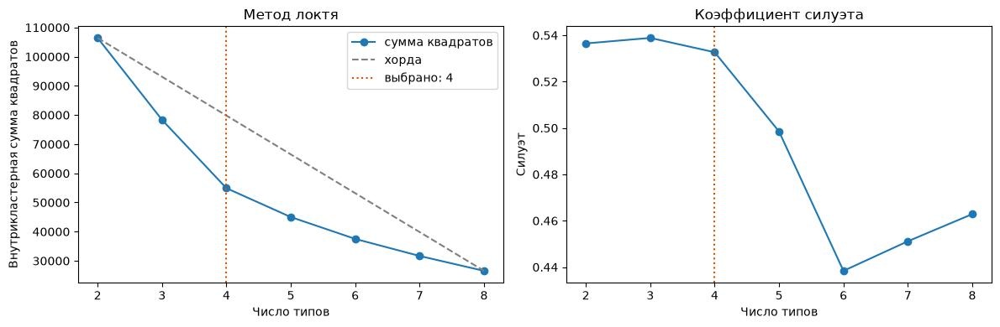

Число типов по методу локтя: 4


,Число типов,Внутрикластерная сумма квадратов,Силуэт,Расстояние до хорды
0,2,106425.787,0.536,0.000
1,3,78338.490,0.539,0.185
2,4,54907.244,0.533,0.312
3,5,45007.075,0.498,0.269
4,6,37512.122,0.438,0.196
5,7,31661.455,0.451,0.103
6,8,26553.192,0.463,0.000


In [ ]:
amp = r1.ravel()                                                         # Амплитуда остаточной аномалии, мГал.
slope_s = smooth(REL["slope"]).ravel()                                   # Средний уклон в окне 210 м.
forest_share = uniform_filter((cls == 1).astype(float), 7).ravel()       # Доля леса в окне.
height_s = smooth(dtm).ravel()                                           # Средняя высота в окне.
feat_g = np.column_stack([amp, slope_s, forest_share, height_s])         # Признаки каждой ячейки.
sel = a1.ravel()                                                         # Только ячейки аномальных структур.
X_g = StandardScaler().fit_transform(feat_g[sel])                        # Стандартизованные признаки аномальных ячеек.
sub = np.random.default_rng(SEED).choice(len(X_g), min(20000, len(X_g)), replace=False)   # Выборка ячеек для силуэта.
K_RANGE = list(range(2, 9))                                              # Проверяемое число типов: от 2 до 8.
rows = []                                                                # Строки будущей таблицы.
for k_ in K_RANGE:                                                       # Для каждого числа типов:
    km_k = KMeans(k_, n_init=10, random_state=SEED).fit(X_g)             # Разбиение на k_ типов.
    rows.append([k_, km_k.inertia_, silhouette_score(X_g[sub], km_k.labels_[sub])])   # Сумма квадратов и силуэт.
k_sel = pd.DataFrame(rows, columns=["Число типов", "Внутрикластерная сумма квадратов", "Силуэт"])   # Таблица выбора.
wcss = k_sel["Внутрикластерная сумма квадратов"]                         # Короткое имя для расчёта.
x_n = (k_sel["Число типов"] - K_RANGE[0]) / (K_RANGE[-1] - K_RANGE[0])   # Число типов, приведённое к диапазону 0…1.
y_n = (wcss - wcss.min()) / (wcss.max() - wcss.min())                    # Сумма квадратов, приведённая к 0…1.
k_sel["Расстояние до хорды"] = (1 - x_n) - y_n                           # Насколько точка ниже прямой между крайними точками.
K_TYPES = int(k_sel.loc[k_sel["Расстояние до хорды"].idxmax(), "Число типов"])   # Точка наибольшего излома – «локоть».
fig, ax = plt.subplots(1, 2, figsize=(12, 4))                            # Два графика рядом.
ax[0].plot(k_sel["Число типов"], wcss, "o-", label="сумма квадратов")    # Кривая локтя.
ax[0].plot([K_RANGE[0], K_RANGE[-1]], [wcss.iloc[0], wcss.iloc[-1]], "--", color="grey", label="хорда")   # Прямая между крайними точками.
ax[0].axvline(K_TYPES, color="#d35400", ls=":", label=f"выбрано: {K_TYPES}")   # Выбранное число типов.
ax[0].set_title("Метод локтя"); ax[0].set_xlabel("Число типов"); ax[0].set_ylabel("Внутрикластерная сумма квадратов"); ax[0].legend()
ax[1].plot(k_sel["Число типов"], k_sel["Силуэт"], "o-"); ax[1].axvline(K_TYPES, color="#d35400", ls=":")   # Силуэт при каждом k.
ax[1].set_title("Коэффициент силуэта"); ax[1].set_xlabel("Число типов"); ax[1].set_ylabel("Силуэт")
plt.tight_layout(); plt.show()                # Показываем рисунок.
k_sel = k_sel.round(3)                                                   # Округляем для показа и файла.
print(f"Число типов по методу локтя: {K_TYPES}")
k_sel                                                                    # Показываем таблицу.

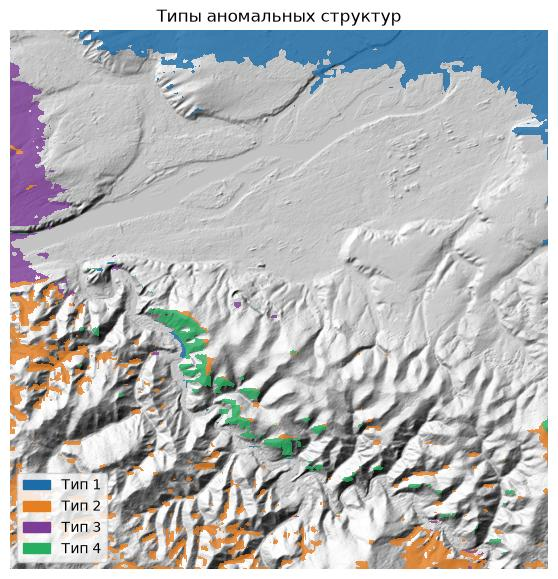

,Тип,"Доля аномальной площади, %","Средняя аномалия, мГал","Уклон, °",Доля леса
0,1,44.84,-3.01,3.29,0.19
1,2,31.56,2.38,15.54,0.99
2,3,15.33,2.91,5.59,0.46
3,4,8.27,-3.14,26.12,0.52


In [ ]:
km = make_pipeline(StandardScaler(), KMeans(K_TYPES, n_init=10, random_state=SEED)).fit(feat_g[sel])   # Стандартизация и разбиение на выбранное число типов.
types = np.full(a1.size, -1)                                             # −1 – ячейка вне структур.
types[sel] = km.predict(feat_g[sel])                                     # Номер типа для аномальных ячеек.
types = types.reshape(a1.shape)                                          # Преобразуем обратно в карту.
rows = []                                                                # Строки будущей таблицы.
for t in range(K_TYPES):                                                 # Для каждого типа:
    m_ = types == t                                                      # Ячейки типа t.
    rows.append({"Тип": t + 1, "Доля аномальной площади, %": 100 * m_.sum() / sel.sum(),
                 "Средняя аномалия, мГал": r1[m_].mean(), "Уклон, °": REL["slope"][m_].mean(), "Доля леса": (cls[m_] == 1).mean()})
b4 = pd.DataFrame(rows).round(2)                                         # Описание типов.
type_colors = ["#1b6ca8", "#e67e22", "#7d3c98", "#27ae60", "#c0392b", "#16a085", "#8d6e63", "#7f8c8d"][:K_TYPES]   # Цвета типов.
fig, ax = plt.subplots(figsize=(8, 7))                                   # Один рисунок.
ax.imshow(ls.hillshade(dtm, vert_exag=3, dx=30, dy=30), cmap="gray")     # Подложка – отмывка рельефа.
ax.imshow(np.ma.masked_less(types, 0), cmap=ListedColormap(type_colors), vmin=-0.5, vmax=K_TYPES - 0.5, alpha=0.8, interpolation="nearest")   # Ячейки вне структур прозрачны.
ax.legend(handles=[Patch(color=type_colors[t], label=f"Тип {t + 1}") for t in range(K_TYPES)], loc="lower left")  # Легенда типов.
ax.set_title("Типы аномальных структур"); ax.axis("off")                 # Заголовок, без осей.
plt.show()                                        # Показываем рисунок.
b4                                                                       # Показываем таблицу.

Типы различаются знаком и амплитудой аномалии, уклоном и долей леса. Чтобы убедиться, что они не являются особенностью одного алгоритма, сравним K-средних с иерархической кластеризацией (метод Уорда) и смесью нормальных распределений на одной выборке из 6000 аномальных пикселей. Согласие разбиений измеряет скорректированный индекс Рэнда (ARI, 1 — полное совпадение).

In [ ]:
from sklearn.cluster import AgglomerativeClustering                      # Иерархическая кластеризация (метод Уорда).
from sklearn.mixture import GaussianMixture                              # Смесь нормальных распределений.
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score   # Метрики разбиения и согласия.
sub6 = np.random.default_rng(SEED).choice(len(X_g), min(6000, len(X_g)), replace=False)   # Общая выборка 6000 ячеек.
X6 = X_g[sub6]                                                           # Стандартизованные признаки выборки.
rows = []                                                                # Строки будущей таблицы.
for k_ in sorted({max(2, K_TYPES - 1), K_TYPES, K_TYPES + 1}):           # Выбранное число типов и соседние:
    lab_km = KMeans(k_, n_init=10, random_state=SEED).fit(X_g).labels_[sub6]   # k-средних по всем ячейкам.
    lab_ward = AgglomerativeClustering(k_, linkage="ward").fit_predict(X6)     # Метод Уорда – по выборке.
    lab_gmm = GaussianMixture(k_, random_state=SEED).fit(X_g).predict(X6)      # Смесь распределений по всем ячейкам.
    for name, lab in [("k-средних", lab_km), ("иерархическая (Уорд)", lab_ward), ("смесь нормальных распределений", lab_gmm)]:
        rows.append({"Метод": name, "Число типов": k_, "Силуэт": silhouette_score(X6, lab),   # Показатели на одной выборке.
                     "Калинский – Харабаш": calinski_harabasz_score(X6, lab), "Дэвис – Боулдин": davies_bouldin_score(X6, lab),
                     "Согласие с k-средних (ARI)": adjusted_rand_score(lab_km, lab)})
b4_methods = pd.DataFrame(rows).round(3)                                 # Таблица сравнения методов.
b4_methods                                                               # Показываем таблицу.

,Метод,Число типов,Силуэт,Калинский – Харабаш,Дэвис – Боулдин,Согласие с k-средних (ARI)
0,k-средних,3,0.535,6591.295,0.844,1.000
1,иерархическая (Уорд),3,0.532,6277.380,0.766,0.916
2,смесь нормальных распределений,3,0.491,6736.332,0.897,0.613
3,k-средних,4,0.532,7277.539,0.809,1.000
4,иерархическая (Уорд),4,0.492,6032.815,0.717,0.846
5,смесь нормальных распределений,4,0.456,5138.980,1.061,0.804
6,k-средних,5,0.500,7051.882,0.830,1.000
7,иерархическая (Уорд),5,0.450,6038.442,0.920,0.853
8,смесь нормальных распределений,5,0.259,4097.744,1.302,0.479


При выбранном числе типов согласие метода Уорда с K-средних — 0,85, смеси распределений — 0,80, а при трёх типах метод Уорда совпадает с K-средних на 0,92: основные типы устойчивы к выбору алгоритма. Смесь распределений согласуется слабее, особенно при большем числе типов: она допускает вытянутые и перекрывающиеся кластеры.

Применим ту же модель типизации к признакам, рассчитанным по исходной модели рельефа: так видно, меняет ли уточнение рельефа тип уже выделенных структур или только их границы.

In [ ]:
feat_g0 = np.column_stack([r0.ravel(), smooth(relief_features(dem)["slope"]).ravel(),   # Те же признаки,
                           uniform_filter((cls == 1).astype(float), 7).ravel(), smooth(dem).ravel()])   # но по исходной модели.
types0 = np.full(a0.size, -1)                                            # −1 – ячейка вне структур.
types0[a0.ravel()] = km.predict(feat_g0[a0.ravel()])                     # Типы по исходным высотам той же моделью.
types0 = types0.reshape(a0.shape)                                        # Обратно в карту.
both = a0 & a1                                                           # Аномалия есть в обоих вариантах.
rows = []                                                                # Строки будущей таблицы.
for t in range(K_TYPES):                                                 # Для каждого типа:
    share0 = 100 * (types0 == t).sum() / a0.sum()                        # доля по исходным высотам,
    share1 = 100 * (types == t).sum() / a1.sum()                         # доля по уточнённым высотам,
    switched = ((types0 == t) & (types != t) & both).sum()               # ячейки, сменившие этот тип на другой.
    rows.append([f"Тип {t + 1}", share0, share1, 100 * switched / max(((types0 == t) & both).sum(), 1)])
b4_change = pd.DataFrame(rows, columns=["Тип", "Доля площади, исходные высоты, %", "Доля площади, уточнённые высоты, %", "Сменили тип, %"]).round(1)
print(f"Аномальная площадь: {a0.sum() * 900 / 1e6:.1f} км² (исходные высоты) и {a1.sum() * 900 / 1e6:.1f} км² (уточнённые); "
      f"общая {both.sum() * 900 / 1e6:.1f} км²; сменили тип {100 * (both & (types0 != types)).sum() / both.sum():.1f}% общей площади")
b4_change                                                                # Показываем таблицу.

Аномальная площадь: 56.7 км² (исходные высоты) и 56.8 км² (уточнённые); общая 50.2 км²; сменили тип 0.4% общей площади


,Тип,"Доля площади, исходные высоты, %","Доля площади, уточнённые высоты, %","Сменили тип, %"
0,Тип 1,45.7,44.8,0.0
1,Тип 2,28.5,31.6,1.3
2,Тип 3,18.8,15.3,0.1
3,Тип 4,7.0,8.3,0.7


Тип меняется у малой доли общей площади: уточнение рельефа меняет прежде всего границы структур, а не их тип.

### **8.8. Результаты на подложке Esri**

Соберём результаты на интерактивной карте с подложкой космических снимков Esri. Растры пересчитываются из проекции UTM в географические координаты; слои включаются и выключаются переключателем справа.


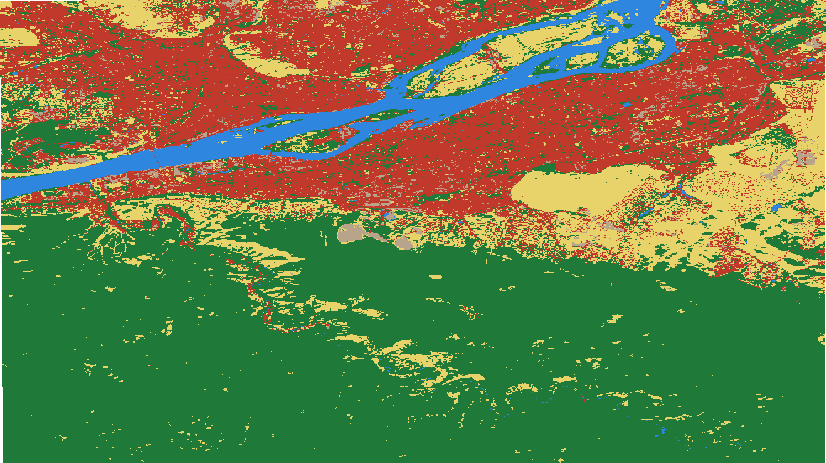
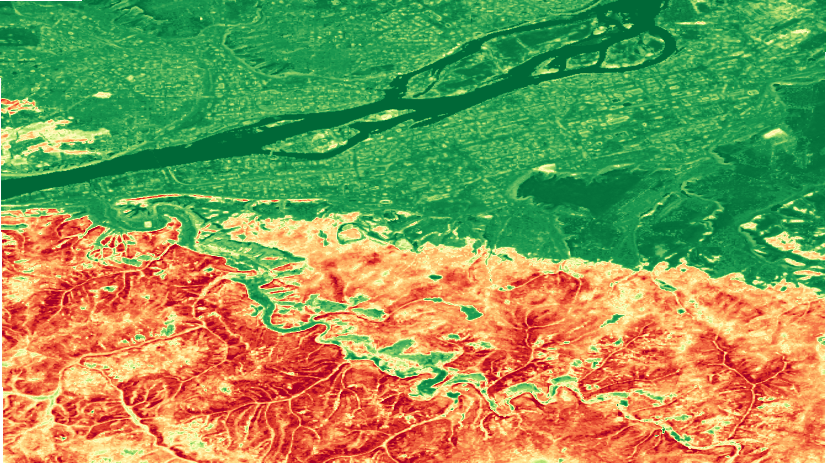
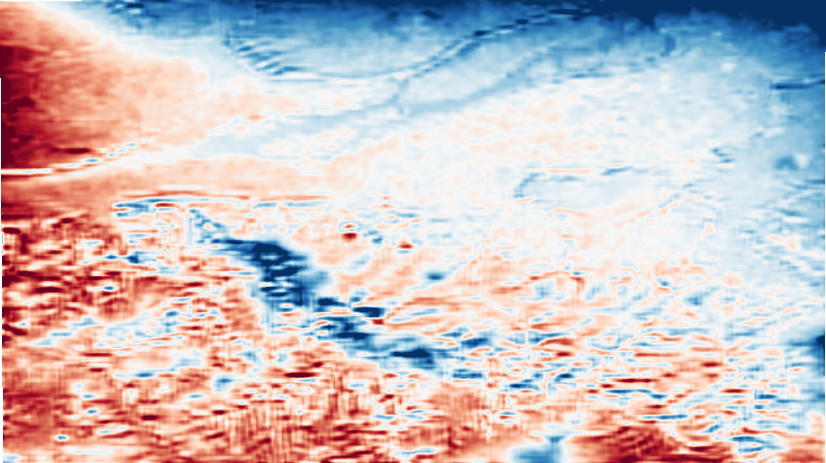
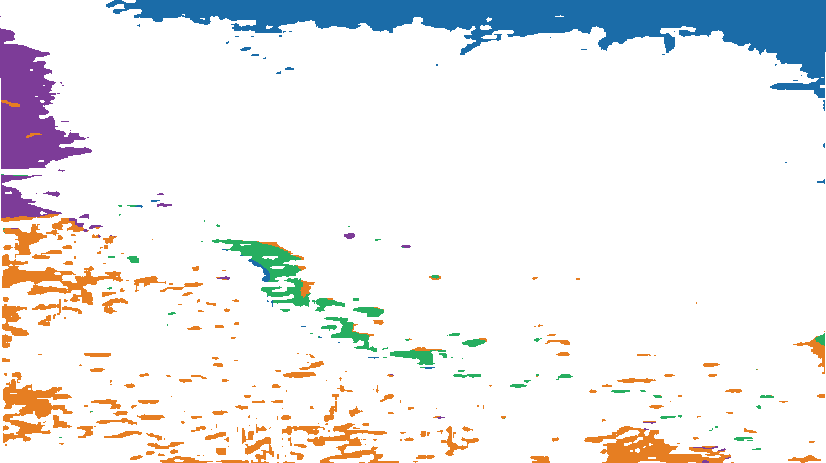

In [ ]:
fmap = folium.Map(location=center, zoom_start=11, tiles="Esri.WorldImagery")   # Подложка – космические снимки Esri.
cls_cmap = ListedColormap(["#00000000"] + [CLASS_COLORS[c] for c in range(1, 8)])   # Номер класса – номер цвета (0 – прозрачный).
overlay_layer(cls, "Карта покрова (модель ИИ)", cls_cmap, 0, 7, categorical=True).add_to(fmap)
overlay_layer(corr, "Поправка высот, м", "RdYlGn_r", 0, float(np.percentile(corr, 99))).add_to(fmap)
v = float(np.percentile(np.abs(r1), 98))                                 # Симметричная шкала аномалий.
overlay_layer(r1, "Локальные аномалии Буге (уточнённые высоты), мГал", "RdBu_r", -v, v, show=True).add_to(fmap)
overlay_layer(np.where(a1, types + 1, np.nan), "Типы аномальных структур", ListedColormap(["#00000000"] + type_colors), 0, K_TYPES,
              categorical=True, opacity=0.8).add_to(fmap)
folium.Rectangle([[ROI_BOUNDS[1], ROI_BOUNDS[0]], [ROI_BOUNDS[3], ROI_BOUNDS[2]]], color="yellow", weight=2, fill=False).add_to(fmap)
folium.LayerControl(collapsed=False).add_to(fmap)                        # Переключатель слоёв.
fmap                                                                     # Показываем карту.

Включая по очереди слои, можно сопоставить аномалии с тем, что видно на снимке: совпадают ли они с границами леса, долинами, городом или от покрова не зависят.

| Тип кластера | Геоморфологическая интерпретация | Доля площади | Средняя аномалия (мГал) | Средний уклон (°) | Ландшафт и покров |
| :--- | :--- | ---: | ---: | ---: | :--- |
| 🟦 **Тип 1** | **Речная долина и низменность** | 44,84 % | −3,01 | 3,29 | Русло реки и почти плоская равнина: вода, застройка, луга и пашня. Доля леса — **0,19 (19 %)**. |
| 🟧 **Тип 2** | **Лесистые склоны и хребты** | 31,56 % | +2,38 | 15,54 | Горные склоны средней крутизны с почти сплошным лесным покровом. Доля леса — **0,99 (99 %)**. |
| 🟪 **Тип 3** | **Пологие предгорья, террасы и плато** | 15,33 % | +2,91 | 5,59 | Переходная зона между равниной и горами со сглаженным рельефом и смешанным покровом. Доля леса — **0,46 (46 %)**. |
| 🟩 **Тип 4** | **Крутые овраги и обрывы** | 8,27 % | −3,14 | 26,12 | Наиболее крутые участки, склоны оврагов и речных врезов; сочетание леса и открытого грунта. Доля леса — **0,52 (52 %)**. |



#### **Краткая интерпретация кластеров**

По приведённому описанию снимка, рельефа и карты покрова кластеры можно интерпретировать следующим образом.


- ##### **🟦 Тип 1 — Низменная равнина и пойма реки**


- - Самый распространённый и наиболее пологий кластер, расположенный преимущественно в северной части территории. Соответствует участкам воды, застройки, лугов и пашни — синему, красному и жёлтому классам на карте покрова. Лесистость минимальна. В исходной интерпретации отрицательная аномалия связывается с отсутствием избыточных горных масс и влиянием водной толщи.

- ##### **🟧 Тип 2 — Лесистые горные массивы**



- - Охватывает около трети территории и соответствует лесистым склонам и хребтам южной части снимка. Практически сплошной лесной покров согласуется с зелёным классом «Лес». Положительная аномалия предположительно связана с избыточной массой горного рельефа.

- ##### **🟪 Тип 3 — Предгорья, террасы и плато**



- - Образует узкую переходную полосу между равниной и горами. Покров смешанный: лес, поля и кустарники; в исходном описании также предполагается наличие участков перевыпаса. При небольшом среднем уклоне здесь наблюдается **максимальная положительная аномалия**. Возможное объяснение — приподнятый, слабо расчленённый рельеф с сохранённой массой горных пород.

- ##### **🟩 Тип 4 — Участки сильного эрозионного расчленения**


- - Наименьший по площади кластер с **максимальным средним уклоном** и наиболее отрицательной средней аномалией. По исходному описанию, образует линейную сеть по дну и склонам оврагов и речных врезов, рассекающих лесной массив. Участки открытого грунта соответствуют серому классу на карте покрова и могут быть связаны с эрозией и оползнями. Отрицательная аномалия предположительно отражает дефицит массы пород в эрозионных врезах.

#### **Выводы по результатам кластеризации:**



Полученное разделение можно интерпретировать как выделение четырёх ландшафтных зон: **низменности**, **лесистых горных склонов**, **переходных предгорий и плато**, а также **крутых эрозионных врезов**. Кластеры различаются сочетанием уклона, средней гравитационной аномалии и лесистости.

### **Выводы по разделу 8:**

1. **Аномалия Буге** — измеренное поле минус рассчитанное по ЦМР притяжение рельефа; она показывает плотностные неоднородности под поверхностью, которых не видно на снимке и рельефе
2. **Цепочка расчёта** — операции над изображениями: вычитание, сглаживание гауссовым фильтром (фон), выделение высоких частот (остаток), пороговая сегментация (структуры)
3. **Ошибка рельефа переходит в аномалию**: 12 м завышения в лесу дают 1,3 мГал ложной аномалии — столько же, сколько амплитуда реальных локальных аномалий
4. **Уточнение рельефа** сдвигает аномалии в лесу на 1–2 мГал и меняет границы структур, а не их тип
5. **Кластеризация** делит аномальные структуры на типы; типы устойчивы к выбору алгоритма

---

## **Раздел 9. Прикладные задачи обработки изображения рельефа**

Уточнённая модель рельефа меняет результат практических расчётов. Во всех задачах расчёт выполняется дважды — по исходной и по уточнённой модели.

### **9.1. Зона затопления: связные области**

Уровень выбранного водного объекта повышается на `WATER_RISE_M` от медианной высоты его поверхности. Затопленными считаются пиксели ниже нового уровня, **связанные** с этим водным объектом. Связность определяет функция `label` из SciPy: она нумерует связные области — группы соседних пикселей с одинаковым признаком. Низина за водоразделом тоже может оказаться ниже уровня, но с рекой она не соединена и не затапливается. Модель упрощённая: уклон водной поверхности и защитные сооружения не учитываются.

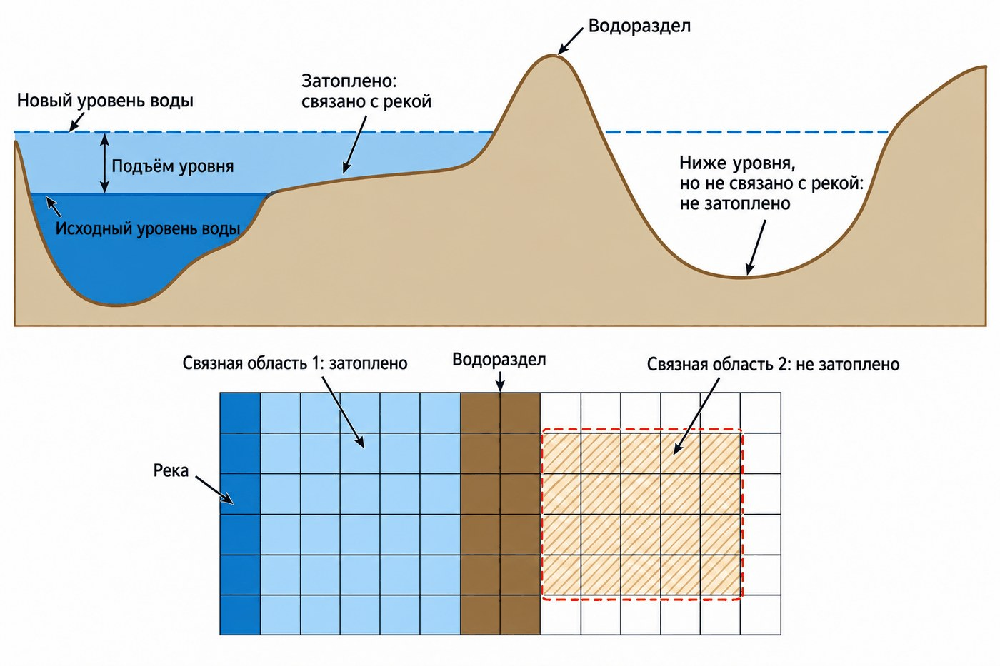

*Зона затопления как связная область пикселей ниже нового уровня воды.*

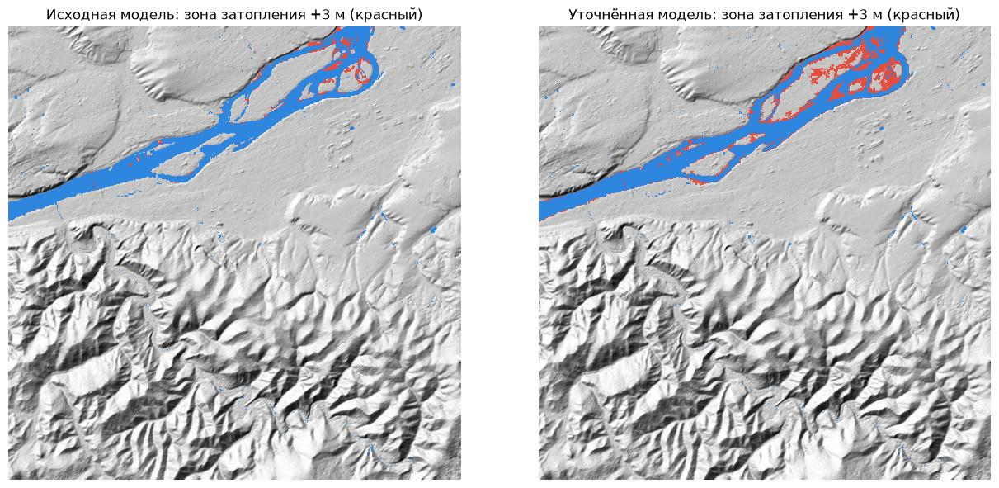

,Модель,"Уровень воды, м","Площадь затопления, км²"
0,Исходная модель,139.0,1.56
1,Уточнённая модель,139.0,5.61


In [ ]:
water_lab, _ = label(cls == 6)                                           # Номера отдельных водных объектов (0 – суша).
if WATER_POINT is None:                                                  # Точка не задана:
    sizes = np.bincount(water_lab.ravel())                               # Число ячеек в каждом водном объекте.
    sizes[0] = 0                                                         # Сушу не учитываем.
    body = water_lab == np.argmax(sizes)                                 # Самый крупный водный объект.
else:                                                                    # Иначе:
    wr, wc = np.round(lonlat_to_rowcol(*WATER_POINT, GRID)).astype(int)  # Ячейка заданной точки.
    body = water_lab == water_lab[wr, wc]                                # Водный объект, содержащий точку.

def flood_area(height, rise):
    """Зона затопления при подъёме уровня водного объекта body на rise метров."""
    level = np.median(height[body]) + rise                               # Новый уровень воды, м.
    lab, _ = label(height <= level)                                      # Связные области ниже уровня.
    connected = np.unique(lab[body & (lab > 0)])                         # Области, которые касаются водного объекта.
    return np.isin(lab, connected) & (cls != 6), level                   # Затопленная суша и уровень.

f0, lev0 = flood_area(dem, WATER_RISE_M)                                 # По исходной модели.
f1, lev1 = flood_area(dtm, WATER_RISE_M)                                 # По уточнённой модели.
b1 = pd.DataFrame([["Исходная модель", lev0, f0.sum() * 900 / 1e6], ["Уточнённая модель", lev1, f1.sum() * 900 / 1e6]],  # Уровень и площадь, км².
                  columns=["Модель", "Уровень воды, м", "Площадь затопления, км²"]).round(2)
if max(f0.mean(), f1.mean()) > 0.25:                                     # Затоплено больше четверти участка:
    print("Затоплено больше четверти территории. Для широкой поймы это возможно; если же выбран водоём выше "
          "окружающей местности (пруд, хвостохранилище), укажите точку на реке в параметре WATER_POINT.")
flood_colors = ListedColormap([(0, 0, 0, 0), "#2e86de", "#e74c3c"])      # Прозрачный, вода, затопление.
fig, ax = plt.subplots(1, 2, figsize=(13, 6))                            # Два рисунка рядом.
for a, f, t in [(ax[0], f0, "Исходная модель"), (ax[1], f1, "Уточнённая модель")]:  # Две карты затопления:
    layer = np.where(cls == 6, 1, np.where(f, 2, 0))                     # 1 – вода, 2 – затопленная суша.
    a.imshow(ls.hillshade(dtm, vert_exag=3, dx=30, dy=30), cmap="gray")  # Подложка – отмывка рельефа.
    a.imshow(layer, cmap=flood_colors, interpolation="nearest")          # Вода и зона затопления.
    a.set_title(f"{t}: зона затопления +{WATER_RISE_M:g} м (красный)"); a.axis("off")  # Заголовок, без осей.
plt.tight_layout(); plt.show()                  # Показываем рисунок.
b1                                                                       # Показываем таблицу.

Там, где модель рельефа была завышена, пойма оказывалась выше уровня воды, и площадь затопления по исходной модели недооценивалась.

### **9.2. Продольный профиль: интерполяция вдоль линии**

Профиль между точками `PROFILE` строится по 400 точкам на равных расстояниях; высота в каждой — билинейной интерполяцией изображения рельефа. Сравниваются перепад высот и крутизна уклонов (95-й процентиль, чтобы единичные скачки не определяли результат).

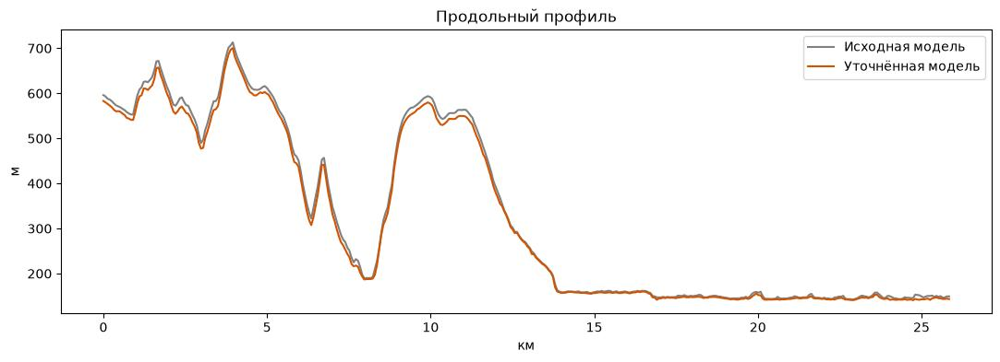

,Модель,"Перепад высот, м","Уклон, 95-й процентиль, °"
0,Исходная модель,570.55,19.15
1,Уточнённая модель,559.74,20.26


In [ ]:
if PROFILE is None:                                                      # По умолчанию – диагональ участка.
    PROFILE = [(ROI_BOUNDS[0] + 0.01, ROI_BOUNDS[1] + 0.01), (ROI_BOUNDS[2] - 0.01, ROI_BOUNDS[3] - 0.01)]
n_pts = 400                                                              # Число точек профиля.
lons_p = np.linspace(PROFILE[0][0], PROFILE[1][0], n_pts)                # Долготы точек профиля.
lats_p = np.linspace(PROFILE[0][1], PROFILE[1][1], n_pts)                # Широты точек профиля.
pr, pc = lonlat_to_rowcol(lons_p, lats_p, GRID)                          # Положение точек на сетке.
h0 = map_coordinates(dem, [pr, pc], order=1)                             # Высоты по исходной модели.
h1 = map_coordinates(dtm, [pr, pc], order=1)                             # Высоты по уточнённой модели.
Xp, Yp = Transformer.from_crs("EPSG:4326", GRID["crs"], always_xy=True).transform(lons_p, lats_p)   # Точки в метрах.
sp = np.r_[0, np.cumsum(np.hypot(np.diff(Xp), np.diff(Yp)))] / 1000      # Расстояние вдоль профиля, км.
plt.figure(figsize=(13, 4))                                              # Широкий рисунок для профиля.
plt.plot(sp, h0, color="grey", label="Исходная модель"); plt.plot(sp, h1, color="#d35400", label="Уточнённая модель")  # Два профиля.
plt.xlabel("км"); plt.ylabel("м"); plt.legend(); plt.title("Продольный профиль"); plt.show()                                           # Подписи и показ рисунка.

def profile_slope(h):
    """Уклон между соседними точками профиля, градусы."""
    return np.degrees(np.arctan(np.abs(np.diff(h)) / np.diff(sp * 1000)))

slope0, slope1 = profile_slope(h0), profile_slope(h1)                    # Уклоны по двум моделям.
b2 = pd.DataFrame([["Исходная модель", h0.max() - h0.min(), np.percentile(slope0, 95)],  # Перепад и уклон по моделям.
                   ["Уточнённая модель", h1.max() - h1.min(), np.percentile(slope1, 95)]],
                  columns=["Модель", "Перепад высот, м", "Уклон, 95-й процентиль, °"]).round(2)
b2                                                                       # Показываем таблицу.

На профиле видно, где уточнение устранило «ступеньки» высотой в лес на границах лесных массивов: по исходной модели трасса как будто поднимается на кроны.

**Практическое применение:** предварительный выбор трасс дорог и трубопроводов, оценка уклонов и планирование водоотвода.



**Характеристика профиля:** выражен переход от расчленённого горного рельефа к равнине. После ML-коррекции общая форма сохранилась, перепад высот уменьшился с **570,55 до 559,74 м**, а 95-й процентиль уклона увеличился с **19,15° до 20,26°**. Следовательно, уточнение изменило высоты и расчётные уклоны, сохранив основные формы рельефа. Повышение точности необходимо подтвердить независимыми измерениями.

### **9.3. Объёмы земляных масс**

Объём — сумма по пикселям участка: (высота − базовая отметка) × площадь пикселя 900 м². Если участок не задан, выбирается квадрат 2×2 км с наибольшей средней поправкой высот — в нём различие моделей проявляется сильнее всего.

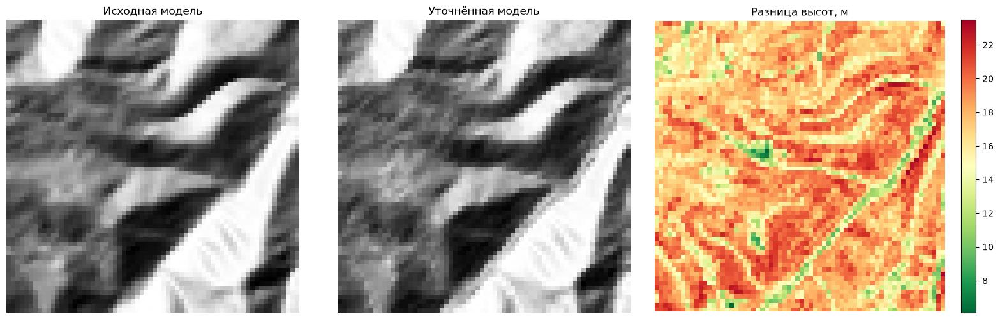

,,"Объём, млн м³"
0,Исходная модель,716.08
1,Уточнённая модель,646.83
2,"Разница, %",10.71


In [ ]:
if VOLUME_BOX is None:                                                   # Участок не задан – выбираем автоматически:
    k = int(2000 / GRID["res"])                                          # Сторона квадрата 2 км в ячейках.
    mean_corr = uniform_filter(corr, k)                                  # Средняя поправка в окне 2×2 км вокруг каждой ячейки.
    inner = mean_corr[k // 2:-k // 2, k // 2:-k // 2]                    # Без краёв, где окно выходит за участок.
    r_, c_ = np.unravel_index(np.argmax(inner), inner.shape)             # Окно с наибольшей средней поправкой.
    box = (slice(r_, r_ + k), slice(c_, c_ + k))                         # Строки и столбцы квадрата.
else:                                                                    # Иначе:
    r_a, c_a = np.round(lonlat_to_rowcol(VOLUME_BOX[0], VOLUME_BOX[3], GRID)).astype(int)   # Северо-западный угол.
    r_b, c_b = np.round(lonlat_to_rowcol(VOLUME_BOX[2], VOLUME_BOX[1], GRID)).astype(int)   # Юго-восточный угол.
    box = (slice(r_a, r_b), slice(c_a, c_b))                             # Строки и столбцы участка.
if VOLUME_LEVEL is None:                                                 # Объём над самой низкой точкой.
    base = dtm[box].min()                                                # Базовая отметка – минимум уточнённой модели.
    v0 = (dem[box] - base).clip(0).sum() * 900                           # Объём по исходной модели, м³.
    v1 = (dtm[box] - base).clip(0).sum() * 900                           # Объём по уточнённой модели, м³.
else:                                                                    # Объём выемки ниже отметки.
    v0 = (VOLUME_LEVEL - dem[box]).clip(0).sum() * 900                   # Выемка по исходной модели, м³.
    v1 = (VOLUME_LEVEL - dtm[box]).clip(0).sum() * 900                   # Выемка по уточнённой модели, м³.
b3 = pd.DataFrame([["Исходная модель", v0 / 1e6], ["Уточнённая модель", v1 / 1e6], ["Разница, %", 100 * (v0 - v1) / v1]],  # Объёмы, млн м³.
                  columns=["", "Объём, млн м³"]).round(2)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))                            # Три рисунка рядом.
for a, h, t in [(ax[0], dem, "Исходная модель"), (ax[1], dtm, "Уточнённая модель")]:  # Отмывка участка по двум моделям:
    a.imshow(ls.hillshade(h[box], vert_exag=3, dx=30, dy=30), cmap="gray"); a.set_title(t); a.axis("off")
im = ax[2].imshow((dem - dtm)[box], cmap="RdYlGn_r"); ax[2].set_title("Разница высот, м"); ax[2].axis("off")  # Разница моделей.
plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()                  # Показываем рисунок.
b3                                                                       # Показываем таблицу.

В лесу исходная модель добавляет к объёму «грунта» объём древостоя: в примере объём завышен примерно на 11 %.

### **9.4. Высота растительности: разность изображений**

В лесу исходная модель показывает поверхность крон, уточнённая — землю, поэтому их разность — оценка высоты растительности (модель высот объектов nDSM = ЦМП − ЦМР). Радарный сигнал частично проникает в кроны, поэтому разность обычно меньше полной высоты деревьев. Сравним её с картой высоты леса ETH.

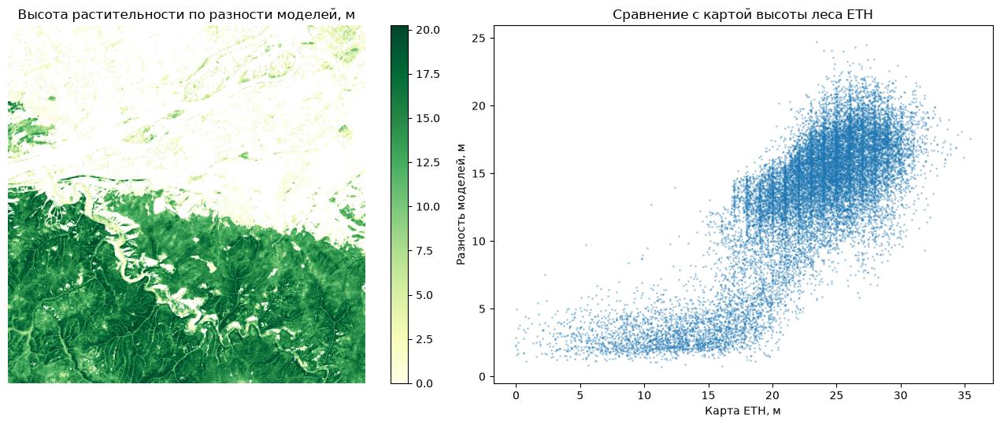

,Показатель,Разность моделей,Карта ETH
0,"Медиана в лесу, м",14.36,23.78
1,Корреляция с картой ETH (лес),0.80,NaN


In [ ]:
veg = (dem - dtm).clip(0)                                                # Разность моделей; отрицательные значения → 0.
fm = cls == 1                                                            # Ячейки леса.
b5 = pd.DataFrame([["Медиана в лесу, м", np.median(veg[fm]), np.median(stack["eth"][fm])],  # Медианы и корреляция.
                   ["Корреляция с картой ETH (лес)", np.corrcoef(veg[fm], stack["eth"][fm])[0, 1], np.nan]],
                  columns=["Показатель", "Разность моделей", "Карта ETH"]).round(2)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))                          # Два рисунка рядом.
im = ax[0].imshow(np.where(fm, veg, np.nan), cmap="YlGn", vmin=0, vmax=np.nanpercentile(veg[fm], 98))   # Только лес.
ax[0].set_title("Высота растительности по разности моделей, м"); ax[0].axis("off")  # Заголовок, без осей.
plt.colorbar(im, ax=ax[0], fraction=0.046)                               # Шкала значений.
sub = np.random.default_rng(SEED).choice(np.where(fm.ravel())[0], min(20000, fm.sum()), replace=False)   # 20 000 ячеек леса для графика.
ax[1].scatter(stack["eth"].ravel()[sub], veg.ravel()[sub], s=1, alpha=0.3)  # Каждая точка – ячейка леса.
ax[1].set_xlabel("Карта ETH, м"); ax[1].set_ylabel("Разность моделей, м"); ax[1].set_title("Сравнение с картой высоты леса ETH")  # Подписи.
plt.tight_layout(); plt.show()            # Показываем рисунок.
b5                                                                       # Показываем таблицу.

Разность моделей связана с картой ETH, но меньше её: радар «видит» не самую верхушку крон, а поверхность где-то внутри полога.

### **Выводы по разделу 9:**

1. **Затопление** — пороговая сегментация изображения рельефа и выделение связной области, соединённой с рекой
2. **Профиль** — билинейная интерполяция изображения вдоль линии
3. **Объёмы** и **высота растительности** — арифметика над изображениями рельефа
4. Во всех задачах исходная модель в лесу искажает результат на величину высоты деревьев

---

## **Заключение**

В рамках данного блокнота была построена полная цепочка обработки спутниковых изображений:

1. **Подготовка изображений:**
   - Приведение снимка, моделей рельефа, карт и гравитационного поля к одной сетке 30 м
   - Безоблачный медианный композит как медианный фильтр во времени, спектральные индексы как попиксельная арифметика каналов

2. **Рельеф как изображение:**
   - Фильтры низких и высоких частот, уклон, индекс топографического положения и шероховатость как фильтры в окне
   - Трёхмерные поверхности рельефа и гравитационного поля

3. **Точечные измерения:**
   - Фильтрация лазерных измерений, пересчёт систем высот, билинейная интерполяция изображений в точках, обоснованные правила очистки

4. **Машинное обучение на изображениях:**
   - Классификация пикселей с проверкой по пространственным блокам
   - Регрессия ошибки высот и уточнённая модель рельефа

5. **Аномалии Буге:**
   - Вычитание притяжения рельефа, выделение фона и остатка фильтрами, пороговая сегментация и кластеризация структур
   - Влияние ошибки рельефа на гравиметрические аномалии

### **Возможные направления применения полученных знаний**

**1. Уточнение рельефа:**
- Подготовка модели рельефа для проектирования трасс, площадок и расчёта объёмов в лесистой местности
- Оценка высоты леса и запасов древесины по разности моделей

**2. Гравиметрия и геология:**
- Расчёт аномалий Буге по уточнённым высотам перед поиском плотностных неоднородностей
- Выделение и типизация аномальных структур для планирования наземных работ

**3. Гидрология и чрезвычайные ситуации:**
- Оценка зон затопления по уточнённому рельефу поймы
- Выделение связных областей ниже заданного уровня

**4. Обработка изображений вообще:**
- Медианные композиты и маски для любых временных рядов снимков
- Фильтры низких и высоких частот для отделения фона от локальных объектов на любом растре